In [1]:
# Идентификаторы моделей OpenRouter (при 404 проверьте точное имя на openrouter.ai)
models = [
    "moonshotai/kimi-k2-thinking",
    "z-ai/glm-4.6",
    # "qwen/qwen3.5-9b",
    # "minimax/minimax-m2.5",
]

# Фиксированный провайдер на модель: значение для extra_body["provider"]["order"] (обычно endpoint tag из OpenRouter).
# Подобрано по /models/.../endpoints: поддержка reasoning + высокий uptime; при сбоях смените tag вручную.
PROVIDER_ROUTE_BY_MODEL = {
    "moonshotai/kimi-k2-thinking": "atlas-cloud/int4",
    "z-ai/glm-4.6": "siliconflow/fp8",
    # "qwen/qwen3.5-9b": "together",
    # "minimax/minimax-m2.5": "inceptron/fp8",
}

In [2]:
import pandas as pd
df = pd.read_parquet("attitude/runs/no_incentive_50_reasoning_trace_t1/responses_final_no_incentive_50_reasoning_trace_t1.parquet")

In [3]:
df.columns

Index(['job_id', 'seed', 'model', 'template_name', 'template_type',
       'experiment_name', 'group_name', 'respondent_id', 'profile_id',
       'profile_pid', 'incentive_key', 'wording_status', 'timestamp_utc',
       'raw_response_text', 'final_answer_text', 'parse_status',
       'error_message', 'stage1_response_text', 'stage2_response_text',
       'stage1_prompt_tokens', 'stage1_completion_tokens',
       'stage1_total_tokens', 'stage2_prompt_tokens',
       'stage2_completion_tokens', 'stage2_total_tokens', 'run_total_tokens',
       'usage_missing', 'retry_attempts_stage1', 'retry_attempts_stage2',
       'stage1_reasoning_text', 'stage1_reasoning_details_json',
       'stage1_reasoning_trace', 'stage2_reasoning_text',
       'stage2_reasoning_details_json', 'stage2_reasoning_trace',
       'reasoning_trace_combined'],
      dtype='object')

In [4]:
df['template_name'].unique()

array(['one_stage_attitude_expression'], dtype=object)

## helpers

In [5]:
import os
import re
import json
import math
import uuid
import random
import asyncio
from pathlib import Path
from datetime import datetime, timezone
from typing import Any, Callable, Dict, List, Optional

import pandas as pd
from tqdm.auto import tqdm
from openai import AsyncOpenAI

# Каталог attitude: ищем prompts_attitude.json относительно текущей рабочей папки (cwd).
# Удобные cwd: .../thinking_expos, .../coursework, .../thinking_expos/runs и т.п.
WORKSPACE_ROOT = Path.cwd()


def _find_attitude_dir() -> Path:
    cwd = WORKSPACE_ROOT.resolve()
    candidates = [
        cwd / "attitude",
        cwd / "thinking_expos" / "attitude",
        cwd.parent / "attitude",
        cwd.parent / "thinking_expos" / "attitude",
    ]
    seen: set = set()
    uniq: List[Path] = []
    for p in candidates:
        rp = p.resolve()
        if rp not in seen:
            seen.add(rp)
            uniq.append(p)
    marker = "prompts_attitude.json"
    for p in uniq:
        if (p / marker).is_file():
            return p
    raise FileNotFoundError(
        "Не найдена папка attitude с prompts_attitude.json. Проверены пути:\n"
        + "\n".join(f"  - {p}" for p in uniq)
    )


ATTITUDE_DIR = _find_attitude_dir()
# Результаты прогонов: attitude/runs (не thinking_expos/runs — иначе файлы окажутся в другом месте, чем открытая вами папка).
RUNS_DIR = ATTITUDE_DIR / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

# Имя подпапки прогона в RUNS_DIR. Задайте строку, например "sharp_topics_v1", или оставьте None.
# Приоритет: аргумент run_id= в run_sdb_experiments_async → глобальный RUN_ID → автоматически run_YYYYMMDDTHHMMSSZ (UTC).
RUN_ID: Optional[str] = None

API_KEY = "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"
if not API_KEY:
    raise ValueError("Задайте переменную окружения OPENROUTER_API_KEY")

BASE_URL = "https://openrouter.ai/api/v1"
client = AsyncOpenAI(api_key=API_KEY, base_url=BASE_URL)


# Инсентивы (опционально). INCLUDE_INCENTIVE=False — блок Incentive в system prompt не добавляется.
INCENTIVES_PATH = ATTITUDE_DIR / "incentives.json"
INCLUDE_INCENTIVE = False

if INCLUDE_INCENTIVE:
    with open(INCENTIVES_PATH, "r", encoding="utf-8") as f:
        INCENTIVES: Dict[str, str] = json.load(f)
    INCENTIVE_KEY: Optional[str] = "A_original_core_realism"
    if INCENTIVE_KEY not in INCENTIVES:
        raise KeyError(f"В {INCENTIVES_PATH} нет ключа {INCENTIVE_KEY!r}")
    INCENTIVE_TEXT = INCENTIVES[INCENTIVE_KEY]
else:
    INCENTIVES = {}
    INCENTIVE_KEY = None
    INCENTIVE_TEXT = ""

RESPONDENTS_PER_GROUP = 100
DEFAULT_MAX_CONCURRENCY = 12
DEFAULT_BATCH_SIZE = 120
DEFAULT_MAX_RETRIES = 5
DEFAULT_CHECKPOINT_EVERY = 100
DEFAULT_TIMEOUT_SECONDS = 180
RANDOM_SEED = 42
random.seed(RANDOM_SEED)

# True — добавить блок с persona_summary (профиль респондента) в system. None или False — демография/персона в промпт не включаются (по умолчанию None).
INCLUDE_PROFILE_IN_PROMPT: Optional[bool] = None

# Конфиг reasoning для OpenRouter: полный trace в ответе (не exclude).
# При необходимости подстройте под модель: например {"max_tokens": 8192} для Qwen thinking.
REASONING_EXTRA_BODY: Dict[str, Any] = {
    "enabled": True,
    "exclude": False,
}


def build_openrouter_extra_body_for_model(model: str, reasoning_cfg: Dict[str, Any]) -> Dict[str, Any]:
    """Склеивает reasoning + фиксированный provider.order из PROVIDER_ROUTE_BY_MODEL (первая ячейка)."""
    body: Dict[str, Any] = {"reasoning": dict(reasoning_cfg)}
    route_id = PROVIDER_ROUTE_BY_MODEL.get(model)
    if route_id:
        body["provider"] = {"order": [route_id], "allow_fallbacks": False}
    return body


for _m in models:
    if _m not in PROVIDER_ROUTE_BY_MODEL:
        raise ValueError(
            f"Модель {_m!r} не задана в PROVIDER_ROUTE_BY_MODEL — добавьте строку в первую ячейку."
        )

KeyboardInterrupt: 

In [ ]:
# Все пути ниже — внутри найденного ATTITUDE_DIR (см. предыдущую ячейку).
PROMPT_TEMPLATES_PATH = ATTITUDE_DIR / "prompts_attitude.json"
EXPERIMENTS_PATH = ATTITUDE_DIR / "two_experiments_hassner_savary_goldsmith.json"
PROFILES_PARQUET_PATH = ATTITUDE_DIR / "twin2k_sample_100_with_demographics.parquet"
SHARP_TOPICS_EXPERIMENTS_PATH = ATTITUDE_DIR / "sharp_topics_experiments.json"


def load_prompt_templates(json_path: Optional[Path] = None) -> Dict[str, Dict[str, str]]:
    """Читает шаблоны из файла при каждом вызове — правки в prompts_attitude.json попадут в датасет после перезапуска ячейки со сборкой."""
    path = (json_path or PROMPT_TEMPLATES_PATH).resolve()
    if not path.is_file():
        raise FileNotFoundError(f"Нет файла шаблонов: {path}")
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def load_sdb_experiments(json_path: Optional[Path] = None) -> List[Dict[str, Any]]:
    """Основной список экспериментов (по умолчанию two_experiments_hassner_savary_goldsmith.json)."""
    path = (json_path or EXPERIMENTS_PATH).resolve()
    if not path.is_file():
        print(f"Предупреждение: нет {path} — sdb_experiments = [].")
        return []
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


sdb_experiments: List[Dict[str, Any]] = load_sdb_experiments()


def load_sharp_topics_experiments(json_path: Optional[Path] = None) -> List[Dict[str, Any]]:
    """Три статьи для sharp-topics; файл обязателен для этого сценария."""
    path = (json_path or SHARP_TOPICS_EXPERIMENTS_PATH).resolve()
    if not path.is_file():
        raise FileNotFoundError(f"Нет файла: {path}")
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


# Снимок для интерактива; в build_requests_dataset передавайте load_prompt_templates(), чтобы не кешировать старую версию.
prompt_templates = load_prompt_templates()


def flatten_experiment_groups(experiments: List[Dict[str, Any]]) -> List[Dict[str, Any]]:
    rows: List[Dict[str, Any]] = []
    for exp in experiments:
        exp_name = exp["experiment_name"]
        groups = exp.get("groups", {})
        for group_name, group_data in groups.items():
            rows.append(
                {
                    "experiment_name": exp_name,
                    "group_name": group_name,
                    "vignette": group_data.get("vignette", "") or "",
                    "question": group_data.get("question", "") or "",
                    "response_options_text": group_data.get("response_options_text", "") or "",
                    "open_rationale_question": group_data.get("open_rationale_question", "") or "",
                    "wording_status": group_data.get("wording_status", "") or "",
                }
            )
    return rows


def load_profiles_from_twin2k_parquet(parquet_path: Path, n_profiles: int = 100) -> List[Dict[str, Any]]:
    df = pd.read_parquet(parquet_path)
    if len(df) != n_profiles:
        raise ValueError(
            f"Expected exactly {n_profiles} rows in {parquet_path.name}, got {len(df)}"
        )
    required = {"pid", "persona_summary"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Parquet missing columns: {sorted(missing)}")

    profiles: List[Dict[str, Any]] = []
    for i in range(len(df)):
        row = df.iloc[i]
        summary = row["persona_summary"]
        if pd.isna(summary):
            summary = ""
        else:
            summary = str(summary)
        profiles.append(
            {
                "profile_id": int(i),
                "pid": str(row["pid"]),
                "persona_summary": summary,
            }
        )
    return profiles


# Демография Twin2k (опционально). По умолчанию — без профилей.
selected_profiles: Optional[List[Dict[str, Any]]] = None
# selected_profiles = load_profiles_from_twin2k_parquet(
#     PROFILES_PARQUET_PATH,
#     n_profiles=RESPONDENTS_PER_GROUP,
# )
_inputs = {
    "prompts_attitude.json": PROMPT_TEMPLATES_PATH,
    "two_experiments_hassner_savary_goldsmith.json": EXPERIMENTS_PATH,
    "sharp_topics_experiments.json (опц.)": SHARP_TOPICS_EXPERIMENTS_PATH,
    "twin2k_...parquet": PROFILES_PARQUET_PATH,
    "incentives.json": INCENTIVES_PATH,
}
print("ATTITUDE_DIR:", ATTITUDE_DIR.resolve())
print("RUNS_DIR:", RUNS_DIR.resolve())
for label, p in _inputs.items():
    print(f"  [{label}] {'OK' if p.is_file() else '— нет файла —'} {p.resolve()}")

print(
    "Respondent profiles:",
    "none (no Twin2k demographics)" if selected_profiles is None else f"{len(selected_profiles)} loaded",
)


ATTITUDE_DIR: /Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinking_expos/attitude
RUNS_DIR: /Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinking_expos/attitude/runs
  [prompts_attitude.json] OK /Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinking_expos/attitude/prompts_attitude.json
  [two_experiments_hassner_savary_goldsmith.json] OK /Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinking_expos/attitude/two_experiments_hassner_savary_goldsmith.json
  [sharp_topics_experiments.json (опц.)] — нет файла — /Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinking_expos/attitude/sharp_topics_experiments.json
  [twin2k_...parquet] OK /Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinking_expos/attitude/twin2k_sample_100_with_demo

In [ ]:
def is_two_stage_template(template_cfg: Dict[str, str]) -> bool:
    return all(
        k in template_cfg
        for k in (
            "STAGE_1_SYSTEM_PROMPT",
            "STAGE_1_USER_PROMPT",
            "STAGE_2_SYSTEM_PROMPT",
            "STAGE_2_USER_PROMPT",
        )
    )


def _safe_format(text: str, values: Dict[str, Any]) -> str:
    text = text or ""
    missing = set(re.findall(r"\{([A-Za-z0-9_]+)\}", text)) - set(values.keys())
    for key in missing:
        values[key] = ""
    return text.format(**values)


def _compose_system_prompt(
    base_system_prompt: str,
    profile_summary: str,
    incentive_text: str,
    *,
    use_incentive: Optional[bool] = None,
) -> str:
    """use_incentive: None — брать глобальный INCLUDE_INCENTIVE."""
    _ui = INCLUDE_INCENTIVE if use_incentive is None else use_incentive
    parts = [(base_system_prompt or "").rstrip()]
    if _ui and incentive_text:
        parts.append("\n\nIncentive:\n" + incentive_text.strip())
    if INCLUDE_PROFILE_IN_PROMPT and (profile_summary or "").strip():
        parts.append(
            "\n\nRespondent profile (use it as the persona for this answer):\n"
            + profile_summary.strip()
            + "\nStay consistent with this profile while answering the survey item."
        )
    return "".join(parts)


def render_prompts_for_job(
    template_name: str,
    template_cfg: Dict[str, str],
    job: Dict[str, Any],
    *,
    incentive_text: Optional[str] = None,
    use_incentive: Optional[bool] = None,
) -> Dict[str, Any]:
    """incentive_text / use_incentive: None — глобальные INCENTIVE_TEXT / INCLUDE_INCENTIVE."""
    _inc_txt = INCENTIVE_TEXT if incentive_text is None else incentive_text
    common_values = {
        "VIGNETTE_TEXT": job.get("vignette", ""),
        "QUESTION_TEXT": job.get("question", ""),
        "ANSWER_OPTIONS": job.get("response_options_text", ""),
        "OPEN_RATIONALE_QUESTION": job.get("open_rationale_question", ""),
        "EXPERIMENT_NAME": job.get("experiment_name", ""),
        "GROUP_NAME": job.get("group_name", ""),
        "RESPONDENT_ID": job.get("respondent_id", ""),
        "PROFILE_ID": job.get("profile_id", ""),
        "PROFILE_PID": job.get("profile_pid", ""),
        "PROFILE_SUMMARY": job.get("profile_summary", ""),
    }

    profile_summary = common_values["PROFILE_SUMMARY"]

    if is_two_stage_template(template_cfg):
        stage1_system = _safe_format(template_cfg.get("STAGE_1_SYSTEM_PROMPT", ""), dict(common_values))
        stage2_system = _safe_format(template_cfg.get("STAGE_2_SYSTEM_PROMPT", ""), dict(common_values))

        return {
            "template_type": "two_stage",
            "stage1": {
                "system": _compose_system_prompt(
                    stage1_system, profile_summary, _inc_txt, use_incentive=use_incentive
                ),
                "user": _safe_format(template_cfg.get("STAGE_1_USER_PROMPT", ""), dict(common_values)),
            },
            "stage2": {
                "system": _compose_system_prompt(
                    stage2_system, profile_summary, _inc_txt, use_incentive=use_incentive
                ),
                "user_template": template_cfg.get("STAGE_2_USER_PROMPT", ""),
                "common_values": common_values,
            },
        }

    base_system = _safe_format(template_cfg.get("SYSTEM_PROMPT", ""), dict(common_values))
    return {
        "template_type": "single_stage",
        "stage1": {
            "system": _compose_system_prompt(
                base_system, profile_summary, _inc_txt, use_incentive=use_incentive
            ),
            "user": _safe_format(template_cfg.get("USER_PROMPT", ""), dict(common_values)),
        },
    }


def extract_final_answer(response_text: str) -> str:
    if not response_text:
        return ""
    lines = [ln.strip() for ln in response_text.splitlines() if ln.strip()]
    for line in reversed(lines):
        if line.lower().startswith("final answer:"):
            return line.split(":", 1)[1].strip()
    return lines[-1] if lines else ""


def normalize_job_output(response_text: str, error_message: Optional[str] = None) -> Dict[str, Any]:
    if error_message:
        return {
            "raw_response_text": response_text or "",
            "final_answer_text": "",
            "parse_status": "error",
            "error_message": error_message,
        }

    final_answer = extract_final_answer(response_text)
    status = "ok" if final_answer else "empty_response"
    return {
        "raw_response_text": response_text or "",
        "final_answer_text": final_answer,
        "parse_status": status,
        "error_message": None,
    }


# Плейсхолдеры в user_prompt второго шага до получения ответа первого
STAGE1_RAW_PLACEHOLDER = "<<<OR_INSERT_STAGE1_RAW_RESPONSE>>>"
STAGE1_FINAL_ANSWER_PLACEHOLDER = "<<<OR_INSERT_STAGE1_FINAL_ANSWER>>>"


def build_requests_dataset(
    models_list: List[str],
    templates_map: Dict[str, Dict[str, str]],
    experiments: List[Dict[str, Any]],
    num_respondents: int,
    respondent_profiles: Optional[List[Dict[str, Any]]] = None,
    reasoning_extra_body: Optional[Dict[str, Any]] = None,
    base_seed: int = 42,
    *,
    incentive_key: Optional[str] = None,
    incentive_text: Optional[str] = None,
    include_incentive: Optional[bool] = None,
) -> pd.DataFrame:
    """
    Одна строка = один HTTP-запрос.
    Для two-stage — две строки на один logical_job_id (stage_index 1 и 2).
    Если respondent_profiles is None — без демографии Twin2k (пустой persona, profile_id = None).
    reasoning_extra_body: если None — используется глобальный REASONING_EXTRA_BODY.
    incentive_key / incentive_text: опционально подставить инсентив из incentives.json или явный текст
    (без смены глобальных INCLUDE_INCENTIVE / INCENTIVE_KEY).
    include_incentive: переопределить флаг добавления блока Incentive; по умолчанию True, если задан key/text.
    """
    _rb = reasoning_extra_body if reasoning_extra_body is not None else REASONING_EXTRA_BODY

    if incentive_text is not None:
        _inc_txt = incentive_text
        _inc_on = True if include_incentive is None else include_incentive
        _inc_key_meta: Optional[str] = incentive_key
    elif incentive_key is not None:
        with open(INCENTIVES_PATH, "r", encoding="utf-8") as f:
            _inc_map: Dict[str, str] = json.load(f)
        if incentive_key not in _inc_map:
            raise KeyError(f"Нет ключа {incentive_key!r} в {INCENTIVES_PATH}")
        _inc_txt = _inc_map[incentive_key]
        _inc_on = True if include_incentive is None else include_incentive
        _inc_key_meta = incentive_key
    else:
        _inc_txt = INCENTIVE_TEXT
        _inc_on = INCLUDE_INCENTIVE if include_incentive is None else include_incentive
        _inc_key_meta = INCENTIVE_KEY

    if num_respondents < 1:
        raise ValueError("num_respondents must be >= 1")
    if respondent_profiles is None:
        respondent_profile_map = {
            rid: {"profile_id": None, "pid": None, "persona_summary": ""}
            for rid in range(1, num_respondents + 1)
        }
    elif len(respondent_profiles) < num_respondents:
        raise ValueError(
            f"need at least {num_respondents} profiles, got {len(respondent_profiles)}"
        )
    else:
        respondent_profile_map = {i + 1: respondent_profiles[i] for i in range(num_respondents)}

    group_rows = flatten_experiment_groups(experiments)
    template_names = sorted(templates_map.keys())

    rows_out: List[Dict[str, Any]] = []
    logical_job_id = 0
    request_id = 0

    for model_name in models_list:
        provider_route_id = PROVIDER_ROUTE_BY_MODEL.get(model_name, "")
        for template_name in template_names:
            template_cfg = templates_map[template_name]
            for group in group_rows:
                for respondent_id in range(1, num_respondents + 1):
                    logical_job_id += 1
                    profile = respondent_profile_map[respondent_id]
                    run_seed = base_seed + logical_job_id
                    _pid = profile.get("profile_id")
                    job: Dict[str, Any] = {
                        "job_id": logical_job_id,
                        "seed": run_seed,
                        "model": model_name,
                        "template_name": template_name,
                        "experiment_name": group["experiment_name"],
                        "group_name": group["group_name"],
                        "respondent_id": respondent_id,
                        "profile_id": None if _pid is None else int(_pid),
                        "profile_pid": profile.get("pid"),
                        "profile_summary": profile.get("persona_summary", "") or "",
                        "vignette": group["vignette"],
                        "question": group["question"],
                        "response_options_text": group["response_options_text"],
                        "open_rationale_question": group["open_rationale_question"],
                        "wording_status": group["wording_status"],
                    }
                    rendered = render_prompts_for_job(
                        template_name,
                        template_cfg,
                        job,
                        incentive_text=_inc_txt,
                        use_incentive=_inc_on,
                    )
                    collect_rt = bool(_rb.get("exclude") is not True)

                    base_meta = {
                        "logical_job_id": logical_job_id,
                        "model": model_name,
                        "provider_route_id": provider_route_id,
                        "template_name": template_name,
                        "template_type": rendered["template_type"],
                        "experiment_name": group["experiment_name"],
                        "group_name": group["group_name"],
                        "treatment_name": group["group_name"],
                        "respondent_id": respondent_id,
                        "profile_id": None if _pid is None else int(_pid),
                        "profile_pid": profile.get("pid"),
                        "profile_summary": job["profile_summary"],
                        "incentive_key": _inc_key_meta if _inc_on else None,
                        "seed": run_seed,
                        "vignette": group["vignette"],
                        "question": group["question"],
                        "response_options_text": group["response_options_text"],
                        "open_rationale_question": group["open_rationale_question"],
                        "wording_status": group["wording_status"],
                        "collect_reasoning_trace": collect_rt,
                        "reasoning_extra_body_json": json.dumps(_rb, ensure_ascii=False),
                        "include_profile_in_prompt": INCLUDE_PROFILE_IN_PROMPT,
                    }

                    if rendered["template_type"] == "single_stage":
                        request_id += 1
                        rows_out.append(
                            {
                                **base_meta,
                                "request_id": request_id,
                                "stage_index": 1,
                                "system_prompt": rendered["stage1"]["system"],
                                "user_prompt": rendered["stage1"]["user"],
                                "user_prompt_needs_stage1_fill": False,
                            }
                        )
                    else:
                        request_id += 1
                        rows_out.append(
                            {
                                **base_meta,
                                "request_id": request_id,
                                "stage_index": 1,
                                "system_prompt": rendered["stage1"]["system"],
                                "user_prompt": rendered["stage1"]["user"],
                                "user_prompt_needs_stage1_fill": False,
                            }
                        )
                        common = dict(rendered["stage2"]["common_values"])
                        pv = dict(common)
                        pv["DELIBERATION_TEXT"] = STAGE1_RAW_PLACEHOLDER
                        pv["RATIONALE_TEXT"] = STAGE1_RAW_PLACEHOLDER
                        pv["SELECTED_ANSWER"] = STAGE1_FINAL_ANSWER_PLACEHOLDER
                        u2 = _safe_format(rendered["stage2"]["user_template"], pv)
                        request_id += 1
                        rows_out.append(
                            {
                                **base_meta,
                                "request_id": request_id,
                                "stage_index": 2,
                                "system_prompt": rendered["stage2"]["system"],
                                "user_prompt": u2,
                                "user_prompt_needs_stage1_fill": True,
                            }
                        )

    return pd.DataFrame(rows_out)


In [ ]:
# requests_df = build_requests_dataset(
#     models_list=models,
#     templates_map=load_prompt_templates(),
#     experiments=sdb_experiments,
#     num_respondents=30,
#     respondent_profiles=selected_profiles,
#     base_seed=RANDOM_SEED,
# )

# if requests_df["profile_id"].notna().any():
#     _mapping_variants = (
#         requests_df[["respondent_id", "profile_id"]]
#         .drop_duplicates()
#         .groupby("respondent_id")["profile_id"]
#         .nunique()
#     )
#     assert (_mapping_variants == 1).all(), "Profile mapping is not stable across groups"

# print("requests_df rows (1 row = 1 API call):", len(requests_df))
# print("logical jobs:", requests_df["logical_job_id"].nunique())
# print(requests_df[["request_id", "logical_job_id", "stage_index", "model", "template_name"]].head(4))


In [ ]:
def _safe_get(obj: Any, key: str, default: Any = None) -> Any:
    if obj is None:
        return default
    if isinstance(obj, dict):
        return obj.get(key, default)
    return getattr(obj, key, default)


def _usage_to_dict(usage_obj: Any) -> Dict[str, Any]:
    prompt_tokens = _safe_get(usage_obj, "prompt_tokens", None)
    completion_tokens = _safe_get(usage_obj, "completion_tokens", None)
    total_tokens = _safe_get(usage_obj, "total_tokens", None)
    return {
        "prompt_tokens": prompt_tokens,
        "completion_tokens": completion_tokens,
        "total_tokens": total_tokens,
        "usage_missing": total_tokens is None,
    }


def _message_to_dict(msg: Any) -> Dict[str, Any]:
    """Достаёт поля сообщения, включая OpenRouter-расширения (reasoning, reasoning_details)."""
    if msg is None:
        return {}
    if isinstance(msg, dict):
        return dict(msg)
    d: Dict[str, Any] = {}
    if hasattr(msg, "model_dump"):
        try:
            d = msg.model_dump()
        except Exception:
            d = {}
    for key in ("content", "role", "reasoning", "reasoning_content", "reasoning_details"):
        if key not in d or d.get(key) is None:
            val = getattr(msg, key, None)
            if val is not None:
                d[key] = val
    extra = getattr(msg, "model_extra", None)
    if isinstance(extra, dict):
        for key in ("reasoning", "reasoning_content", "reasoning_details"):
            if d.get(key) is None and key in extra:
                d[key] = extra[key]
    return d


def _assistant_reply_text(msg: Any) -> str:
    """Финальный текст ответа: `content`, иначе `reasoning` / `reasoning_content` (thinking-модели на OpenRouter часто оставляют content пустым)."""
    d = _message_to_dict(msg)
    c = d.get("content")
    if isinstance(c, str) and c.strip():
        return c.strip()
    if c is not None and not isinstance(c, str):
        s = str(c).strip()
        if s:
            return s
    for key in ("reasoning", "reasoning_content"):
        v = d.get(key)
        if isinstance(v, str) and v.strip():
            return v.strip()
        if v is not None and not isinstance(v, str):
            s = str(v).strip()
            if s:
                return s
    return ""


def extract_reasoning_trace_from_message(msg: Any) -> Dict[str, Optional[str]]:
    """
    Собирает максимально полный reasoning trace: текст reasoning + JSON reasoning_details (если есть).
    """
    d = _message_to_dict(msg)
    reasoning_text = d.get("reasoning")
    if reasoning_text is None or (isinstance(reasoning_text, str) and not reasoning_text.strip()):
        alt = d.get("reasoning_content")
        if alt is not None:
            reasoning_text = alt
    if reasoning_text is None:
        reasoning_text = ""
    elif not isinstance(reasoning_text, str):
        reasoning_text = str(reasoning_text)

    rd = d.get("reasoning_details")
    details_json: Optional[str] = None
    if rd is not None:
        try:
            details_json = json.dumps(rd, ensure_ascii=False)
        except (TypeError, ValueError):
            details_json = str(rd)

    parts: List[str] = []
    if reasoning_text.strip():
        parts.append(reasoning_text.strip())
    if details_json:
        parts.append("--- reasoning_details ---\n" + details_json)

    full_trace = "\n\n".join(parts).strip()
    return {
        "reasoning_text": reasoning_text,
        "reasoning_details_json": details_json,
        "reasoning_trace": full_trace,
    }


def _is_retryable_error(exc: Exception) -> bool:
    msg = str(exc).lower()
    retry_markers = ["429", "rate", "timeout", "tempor", "connection", "5", "overloaded"]
    return any(marker in msg for marker in retry_markers)


def _empty_reasoning_fields() -> Dict[str, Any]:
    return {
        "reasoning_text": "",
        "reasoning_details_json": None,
        "reasoning_trace": "",
    }


def _reasoning_body_from_row(row: Dict[str, Any]) -> Dict[str, Any]:
    raw = row.get("reasoning_extra_body_json") or ""
    if not raw:
        return dict(REASONING_EXTRA_BODY)
    try:
        return json.loads(raw)
    except Exception:
        return dict(REASONING_EXTRA_BODY)


def _fill_stage2_user_prompt(user_prompt: str, stage1_response_text: str) -> str:
    fa = extract_final_answer(stage1_response_text)
    return (
        user_prompt.replace(STAGE1_RAW_PLACEHOLDER, stage1_response_text)
        .replace(STAGE1_FINAL_ANSWER_PLACEHOLDER, fa)
    )


async def _chat_completion_with_retry(
    model: str,
    system_text: str,
    user_text: str,
    max_retries: int = DEFAULT_MAX_RETRIES,
    timeout_seconds: int = DEFAULT_TIMEOUT_SECONDS,
    reasoning_body: Optional[Dict[str, Any]] = None,
    temperature: float = 0.7,
) -> Dict[str, Any]:
    reasoning_body = reasoning_body if reasoning_body is not None else REASONING_EXTRA_BODY
    last_err = None
    for attempt in range(max_retries + 1):
        try:
            completion = await asyncio.wait_for(
                client.chat.completions.create(
                    model=model,
                    messages=[
                        {"role": "system", "content": system_text},
                        {"role": "user", "content": user_text},
                    ],
                    temperature=temperature,
                    extra_body=build_openrouter_extra_body_for_model(model, reasoning_body),
                ),
                timeout=timeout_seconds,
            )

            choice = completion.choices[0] if completion.choices else None
            msg_obj = _safe_get(choice, "message", None)
            response_text = _assistant_reply_text(msg_obj)
            usage_dict = _usage_to_dict(_safe_get(completion, "usage", None))
            rfields = extract_reasoning_trace_from_message(msg_obj)

            return {
                "ok": True,
                "response_text": response_text,
                "usage": usage_dict,
                "error_message": None,
                "attempt": attempt,
                **rfields,
            }
        except Exception as exc:
            last_err = exc
            if attempt >= max_retries or not _is_retryable_error(exc):
                break
            sleep_s = min(20, (2**attempt) + random.random())
            await asyncio.sleep(sleep_s)

    er = _empty_reasoning_fields()
    return {
        "ok": False,
        "response_text": "",
        "usage": {
            "prompt_tokens": None,
            "completion_tokens": None,
            "total_tokens": None,
            "usage_missing": True,
        },
        "error_message": str(last_err),
        "attempt": max_retries,
        **er,
    }


async def openrouter_chat_with_reasoning(
    model: str,
    system_text: str,
    user_text: str,
    **kwargs: Any,
) -> Dict[str, Any]:
    """Один async-запрос к OpenRouter; в ответе — `response_text`, поля reasoning и usage (см. `_chat_completion_with_retry`)."""
    return await _chat_completion_with_retry(model, system_text, user_text, **kwargs)


async def _run_one_logical_job_async(
    job_rows: List[Dict[str, Any]],
    temperature: float,
) -> Dict[str, Any]:
    """job_rows — строки requests_df с одним logical_job_id, по возрастанию stage_index."""
    job_rows = sorted(job_rows, key=lambda r: int(r["stage_index"]))
    first = job_rows[0]
    base_result = {
        "job_id": int(first["logical_job_id"]),
        "seed": first["seed"],
        "model": first["model"],
        "template_name": first["template_name"],
        "template_type": first["template_type"],
        "experiment_name": first["experiment_name"],
        "group_name": first["group_name"],
        "respondent_id": int(first["respondent_id"]),
        "profile_id": int(first["profile_id"]) if first.get("profile_id") is not None else None,
        "profile_pid": first.get("profile_pid"),
        "incentive_key": first.get("incentive_key"),
        "wording_status": first.get("wording_status", ""),
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    }

    r1row = job_rows[0]
    rb = _reasoning_body_from_row(r1row)
    stage1 = await _chat_completion_with_retry(
        model=str(r1row["model"]),
        system_text=str(r1row["system_prompt"]),
        user_text=str(r1row["user_prompt"]),
        reasoning_body=rb,
        temperature=temperature,
    )

    def _stage_reasoning(prefix: str, st: Dict[str, Any]) -> Dict[str, Any]:
        return {
            f"{prefix}_reasoning_text": st.get("reasoning_text", ""),
            f"{prefix}_reasoning_details_json": st.get("reasoning_details_json"),
            f"{prefix}_reasoning_trace": st.get("reasoning_trace", ""),
        }

    r1 = _stage_reasoning("stage1", stage1)

    if len(job_rows) == 1:
        parsed = normalize_job_output(stage1["response_text"], stage1["error_message"])
        return {
            **base_result,
            **parsed,
            "stage1_response_text": stage1["response_text"],
            "stage2_response_text": None,
            "stage1_prompt_tokens": stage1["usage"]["prompt_tokens"],
            "stage1_completion_tokens": stage1["usage"]["completion_tokens"],
            "stage1_total_tokens": stage1["usage"]["total_tokens"],
            "stage2_prompt_tokens": None,
            "stage2_completion_tokens": None,
            "stage2_total_tokens": None,
            "run_total_tokens": stage1["usage"]["total_tokens"],
            "usage_missing": stage1["usage"]["usage_missing"],
            "retry_attempts_stage1": stage1["attempt"],
            "retry_attempts_stage2": None,
            **r1,
            **_stage_reasoning("stage2", _empty_reasoning_fields()),
            "reasoning_trace_combined": r1["stage1_reasoning_trace"],
        }

    r2row = job_rows[1]
    u2 = (
        _fill_stage2_user_prompt(str(r2row["user_prompt"]), stage1["response_text"])
        if r2row.get("user_prompt_needs_stage1_fill")
        else str(r2row["user_prompt"])
    )
    rb2 = _reasoning_body_from_row(r2row)
    stage2 = await _chat_completion_with_retry(
        model=str(r2row["model"]),
        system_text=str(r2row["system_prompt"]),
        user_text=u2,
        reasoning_body=rb2,
        temperature=temperature,
    )

    final_error = stage1["error_message"] or stage2["error_message"]
    parsed = normalize_job_output(stage2["response_text"], final_error)

    st1_total = stage1["usage"]["total_tokens"]
    st2_total = stage2["usage"]["total_tokens"]
    run_total = (
        None
        if (st1_total is None and st2_total is None)
        else (st1_total or 0) + (st2_total or 0)
    )

    r2 = _stage_reasoning("stage2", stage2)
    _parts: List[str] = []
    if (r1.get("stage1_reasoning_trace") or "").strip():
        _parts.append("=== STAGE 1 reasoning ===\n" + (r1["stage1_reasoning_trace"] or ""))
    if (r2.get("stage2_reasoning_trace") or "").strip():
        _parts.append("=== STAGE 2 reasoning ===\n" + (r2["stage2_reasoning_trace"] or ""))
    combined = "\n\n".join(_parts)

    return {
        **base_result,
        **parsed,
        "stage1_response_text": stage1["response_text"],
        "stage2_response_text": stage2["response_text"],
        "stage1_prompt_tokens": stage1["usage"]["prompt_tokens"],
        "stage1_completion_tokens": stage1["usage"]["completion_tokens"],
        "stage1_total_tokens": st1_total,
        "stage2_prompt_tokens": stage2["usage"]["prompt_tokens"],
        "stage2_completion_tokens": stage2["usage"]["completion_tokens"],
        "stage2_total_tokens": st2_total,
        "run_total_tokens": run_total,
        "usage_missing": stage1["usage"]["usage_missing"] or stage2["usage"]["usage_missing"],
        "retry_attempts_stage1": stage1["attempt"],
        "retry_attempts_stage2": stage2["attempt"],
        **r1,
        **r2,
        "reasoning_trace_combined": combined,
    }


In [ ]:
def _parts_dir(run_dir: Path) -> Path:
    p = run_dir / "parts"
    p.mkdir(parents=True, exist_ok=True)
    return p


def _progress_path(run_dir: Path) -> Path:
    return run_dir / "progress.parquet"


def _metadata_path(run_dir: Path) -> Path:
    return run_dir / "run_metadata.json"


def _load_completed_job_ids(run_dir: Path) -> set:
    progress_file = _progress_path(run_dir)
    if not progress_file.exists():
        return set()
    progress_df = pd.read_parquet(progress_file)
    return set(progress_df["job_id"].astype(int).tolist()) if not progress_df.empty else set()


def _save_progress(run_dir: Path, completed_job_ids: set) -> None:
    progress_df = pd.DataFrame({"job_id": sorted(completed_job_ids)})
    progress_df.to_parquet(_progress_path(run_dir), index=False)


def _save_batch_chunk(run_dir: Path, rows: List[Dict[str, Any]]) -> Path:
    chunk_name = f"responses_part_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S')}_{uuid.uuid4().hex[:8]}.parquet"
    out_path = _parts_dir(run_dir) / chunk_name
    pd.DataFrame(rows).to_parquet(out_path, index=False)
    return out_path


def _merge_parts_to_final(run_dir: Path) -> Path:
    part_files = sorted((_parts_dir(run_dir)).glob("responses_part_*.parquet"))
    if not part_files:
        out = run_dir / "responses_final.parquet"
        pd.DataFrame().to_parquet(out, index=False)
        return out

    frames = [pd.read_parquet(p) for p in part_files]
    full_df = pd.concat(frames, ignore_index=True)
    full_df = full_df.sort_values("job_id").drop_duplicates(subset=["job_id"], keep="last").reset_index(drop=True)

    out_path = run_dir / "responses_final.parquet"
    full_df.to_parquet(out_path, index=False)
    return out_path


In [ ]:
def _logical_jobs_list_from_requests_df(requests_df: pd.DataFrame) -> List[List[Dict[str, Any]]]:
    """Группирует строки датасета запросов в список логических задач (1 или 2 API-вызова)."""
    out: List[List[Dict[str, Any]]] = []
    for lid in sorted(requests_df["logical_job_id"].unique()):
        sub = requests_df[requests_df["logical_job_id"] == lid].sort_values("stage_index")
        out.append(sub.to_dict("records"))
    return out


def _error_row_base(first_row: Dict[str, Any]) -> Dict[str, Any]:
    return {
        "job_id": int(first_row["logical_job_id"]),
        "seed": first_row["seed"],
        "model": first_row["model"],
        "template_name": first_row["template_name"],
        "template_type": None,
        "experiment_name": first_row["experiment_name"],
        "group_name": first_row["group_name"],
        "respondent_id": first_row["respondent_id"],
        "profile_id": int(first_row["profile_id"]) if first_row.get("profile_id") is not None else None,
        "profile_pid": first_row.get("profile_pid"),
        "incentive_key": first_row.get("incentive_key"),
        "wording_status": first_row.get("wording_status", ""),
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "raw_response_text": "",
        "final_answer_text": "",
        "parse_status": "error",
        "error_message": None,
        "stage1_response_text": None,
        "stage2_response_text": None,
        "stage1_prompt_tokens": None,
        "stage1_completion_tokens": None,
        "stage1_total_tokens": None,
        "stage2_prompt_tokens": None,
        "stage2_completion_tokens": None,
        "stage2_total_tokens": None,
        "run_total_tokens": None,
        "usage_missing": True,
        "retry_attempts_stage1": None,
        "retry_attempts_stage2": None,
        "stage1_reasoning_text": "",
        "stage1_reasoning_details_json": None,
        "stage1_reasoning_trace": "",
        "stage2_reasoning_text": "",
        "stage2_reasoning_details_json": None,
        "stage2_reasoning_trace": "",
        "reasoning_trace_combined": "",
    }


async def _run_batch_async(
    batch_logical_jobs: List[List[Dict[str, Any]]],
    temperature: float,
    semaphore: asyncio.Semaphore,
    on_job_done: Optional[Callable[[], None]] = None,
) -> List[Dict[str, Any]]:
    async def _guarded(job_rows: List[Dict[str, Any]]) -> Dict[str, Any]:
        async with semaphore:
            try:
                r = await _run_one_logical_job_async(job_rows, temperature)
                if on_job_done is not None:
                    on_job_done()
                return r
            except Exception as exc:
                row = _error_row_base(job_rows[0])
                row["error_message"] = str(exc)
                if on_job_done is not None:
                    on_job_done()
                return row

    tasks = [_guarded(jr) for jr in batch_logical_jobs]
    return await asyncio.gather(*tasks, return_exceptions=False)


def _iter_batches(items: List[Any], batch_size: int):
    for i in range(0, len(items), batch_size):
        yield items[i : i + batch_size]


def _build_token_usage_summary(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty:
        return pd.DataFrame()

    grouped = (
        df.groupby(["model", "template_name", "experiment_name", "group_name"], as_index=False)
        .agg(
            respondents=("job_id", "count"),
            ok_rows=("parse_status", lambda s: int((s == "ok").sum())),
            error_rows=("parse_status", lambda s: int((s == "error").sum())),
            total_tokens_sum=("run_total_tokens", "sum"),
            stage1_tokens_sum=("stage1_total_tokens", "sum"),
            stage2_tokens_sum=("stage2_total_tokens", "sum"),
            usage_missing_rows=("usage_missing", lambda s: int(pd.Series(s).fillna(False).sum())),
        )
    )
    grouped["avg_tokens_per_row"] = grouped["total_tokens_sum"] / grouped["respondents"].clip(lower=1)
    return grouped.sort_values(["model", "template_name", "experiment_name", "group_name"]).reset_index(drop=True)


def _group_pending_logical_jobs_by_model(
    pending_logical_jobs: List[List[Dict[str, Any]]], model_order: List[str]
) -> Dict[str, List[List[Dict[str, Any]]]]:
    from collections import defaultdict

    buckets: Dict[str, List[List[Dict[str, Any]]]] = defaultdict(list)
    for j in pending_logical_jobs:
        m = j[0]["model"]
        buckets[m].append(j)
    return {m: buckets[m] for m in model_order if m in buckets and buckets[m]}


async def run_sdb_experiments_async(
    requests_df: pd.DataFrame,
    *,
    temperature: float = 0.7,
    run_id: Optional[str] = None,
    resume: bool = True,
    max_concurrency: int = DEFAULT_MAX_CONCURRENCY,
    batch_size: int = DEFAULT_BATCH_SIZE,
    checkpoint_every: int = DEFAULT_CHECKPOINT_EVERY,
    show_progress: bool = True,
) -> Dict[str, Any]:
    """
    Отправка запросов по таблице `requests_df` (одна строка = один HTTP-вызов).
    `temperature` — температура генерации для всех вызовов.
    `run_id` — явная строка (имя папки в RUNS_DIR). Если None — берётся глобальный `RUN_ID`; если и он None — `run_…` по времени UTC.
    """
    if run_id is not None and str(run_id).strip() != "":
        run_id = str(run_id).strip()
    elif RUN_ID is not None and str(RUN_ID).strip() != "":
        run_id = str(RUN_ID).strip()
    else:
        run_id = datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%SZ")
    run_dir = RUNS_DIR / run_id
    run_dir.mkdir(parents=True, exist_ok=True)

    all_logical_jobs = _logical_jobs_list_from_requests_df(requests_df)
    completed_job_ids = _load_completed_job_ids(run_dir) if resume else set()
    pending_logical_jobs = [
        lj for lj in all_logical_jobs if int(lj[0]["logical_job_id"]) not in completed_job_ids
    ]

    semaphore = asyncio.Semaphore(max_concurrency)
    written_parts: List[str] = []

    run_meta = {
        "run_id": run_id,
        "started_utc": datetime.now(timezone.utc).isoformat(),
        "temperature": temperature,
        "max_concurrency": max_concurrency,
        "batch_size": batch_size,
        "checkpoint_every": checkpoint_every,
        "resume": resume,
        "total_logical_jobs": len(all_logical_jobs),
        "total_api_rows_in_dataset": len(requests_df),
        "pending_logical_jobs_at_start": len(pending_logical_jobs),
        "incentive_key": INCENTIVE_KEY if INCLUDE_INCENTIVE else None,
        "include_incentive": INCLUDE_INCENTIVE,
        "include_profile_in_prompt": INCLUDE_PROFILE_IN_PROMPT,
        "attitude_dir": str(ATTITUDE_DIR),
        "prompt_templates_path": str(PROMPT_TEMPLATES_PATH),
        "experiments_path": str(EXPERIMENTS_PATH),
        "sharp_topics_experiments_path": str(SHARP_TOPICS_EXPERIMENTS_PATH),
        "profiles_parquet_path": str(PROFILES_PARQUET_PATH),
        "incentives_path": str(INCENTIVES_PATH),
        "reasoning_extra_body": REASONING_EXTRA_BODY,
        "provider_route_by_model": dict(PROVIDER_ROUTE_BY_MODEL),
    }

    model_order = list(dict.fromkeys(requests_df["model"].tolist()))
    by_model = _group_pending_logical_jobs_by_model(pending_logical_jobs, model_order)
    models_active = [m for m in model_order if m in by_model]

    pbar_all = None
    model_pbars: Dict[str, Any] = {}
    if show_progress and pending_logical_jobs:
        pbar_all = tqdm(
            total=len(pending_logical_jobs),
            desc="Всего логических задач",
            unit="job",
            position=0,
            leave=True,
        )
        for pos, m in enumerate(models_active, start=1):
            short = (m[:52] + "…") if len(m) > 53 else m
            model_pbars[m] = tqdm(
                total=len(by_model[m]),
                desc=short,
                unit="job",
                position=pos,
                leave=True,
            )

    since_last_checkpoint = 0
    try:
        for m in models_active:
            for batch in _iter_batches(by_model[m], batch_size):

                def _make_bump():
                    def _bump() -> None:
                        if pbar_all is not None:
                            pbar_all.update(1)
                        if m in model_pbars:
                            model_pbars[m].update(1)

                    return _bump

                rows = await _run_batch_async(
                    batch,
                    temperature,
                    semaphore,
                    on_job_done=_make_bump() if show_progress else None,
                )

                chunk_path = _save_batch_chunk(run_dir, rows)
                written_parts.append(str(chunk_path))

                n_done = len(rows)
                for row in rows:
                    completed_job_ids.add(int(row["job_id"]))

                since_last_checkpoint += n_done
                if since_last_checkpoint >= checkpoint_every:
                    _save_progress(run_dir, completed_job_ids)
                    since_last_checkpoint = 0
    finally:
        if model_pbars:
            for bar in model_pbars.values():
                bar.close()
        if pbar_all is not None:
            pbar_all.close()

    _save_progress(run_dir, completed_job_ids)

    responses_final_path = _merge_parts_to_final(run_dir)
    responses_df = pd.read_parquet(responses_final_path)
    if not responses_df.empty and "profile_id" in responses_df.columns:
        responses_df["profile_id"] = pd.to_numeric(responses_df["profile_id"], errors="coerce").astype("Int64")
        responses_df.to_parquet(responses_final_path, index=False)

    usage_summary_df = _build_token_usage_summary(responses_df)
    usage_summary_path = run_dir / "token_usage_summary.parquet"
    usage_summary_df.to_parquet(usage_summary_path, index=False)

    expected_rows = len(all_logical_jobs)
    completed_rows = len(responses_df)
    missing_usage_share = (
        float(responses_df["usage_missing"].fillna(True).mean())
        if not responses_df.empty
        else math.nan
    )
    total_tokens_used = (
        None if responses_df.empty else float(responses_df["run_total_tokens"].fillna(0).sum())
    )

    run_meta.update(
        {
            "finished_utc": datetime.now(timezone.utc).isoformat(),
            "completed_rows": completed_rows,
            "expected_rows": expected_rows,
            "coverage_ratio": (completed_rows / expected_rows) if expected_rows else math.nan,
            "missing_usage_share": missing_usage_share,
            "total_tokens_used": total_tokens_used,
            "parts_written": len(written_parts),
            "responses_final_path": str(responses_final_path),
            "token_usage_summary_path": str(usage_summary_path),
        }
    )

    with open(_metadata_path(run_dir), "w", encoding="utf-8") as f:
        json.dump(run_meta, f, ensure_ascii=False, indent=2)

    print(f"Run ID: {run_id}")
    print(f"Completed rows: {completed_rows} / {expected_rows}")
    print(
        f"Missing usage share: {missing_usage_share:.4f}"
        if not math.isnan(missing_usage_share)
        else "Missing usage share: n/a"
    )
    print(
        f"Total tokens used: {int(total_tokens_used) if total_tokens_used is not None else 'n/a'}"
    )

    if not responses_df.empty:
        top_errors = (
            responses_df[responses_df["parse_status"] == "error"]["error_message"]
            .fillna("<empty>")
            .value_counts()
            .head(5)
        )
        if len(top_errors):
            print("Top errors:")
            print(top_errors)

    return {
        "run_id": run_id,
        "run_dir": str(run_dir),
        "responses_df": responses_df,
        "usage_summary_df": usage_summary_df,
        "meta": run_meta,
    }


In [ ]:
# Полный прогон (раскомментируйте). Результаты: attitude/runs/<run_id>/
# (responses_final.parquet — колонки stage*_reasoning_trace, reasoning_trace_combined, ...)

# results = await run_sdb_experiments_async(
#     requests_df=requests_df,
#     temperature=0.7,
#     run_id="my_run",  # или None: тогда RUN_ID из ячейки с импортами, иначе авто run_…
#     resume=True,
#     max_concurrency=8,
#     batch_size=120,
#     checkpoint_every=100,
# )
# results["usage_summary_df"].head()


## 1. добиваемся разброса ответов

Два эксперимента из `two_experiments_hassner_savary_goldsmith.json`, шаблон только **`one_stage_attitude_expression`**, по **30** респондентов на каждый condition (группу), модели из **`models`**, температура **0.0** (при отказе провайдера — **0.01**).

Reasoning/thinking у провайдера включён (`enabled: true`), в ответ не подмешивается trace (`exclude: true`) — в датасете остаётся в основном финальный текст ответа модели.

### наивный подход
- t = 0.01
- без стимула
- reasoning: включен, но не собирается
- 2 экспа
- 30 респондентов

In [ ]:
# --- (а) Таблица запросов: Hassner + Savary/Goldsmith (two_experiments_hassner_savary_goldsmith.json) ---

experiments_for_run = load_sdb_experiments()
assert len(experiments_for_run) == 2, "Ожидаются 2 эксперимента в two_experiments_hassner_savary_goldsmith.json"

_prompts_from_file = load_prompt_templates()
SHARP_TEMPLATE_MAP: Dict[str, Dict[str, str]] = {
    "one_stage_attitude_expression": _prompts_from_file["one_stage_attitude_expression"],
}

# Reasoning у модели включён; в ответ API не возвращает reasoning trace — только финальный контент.
SHARP_REASONING_BODY: Dict[str, Any] = {
    "enabled": True,
    "exclude": True,
}

SHARP_NUM_RESPONDENTS_PER_CONDITION = 30
# Если при 0.0 провайдер вернёт ошибку — поставьте 0.01
SHARP_TEMPERATURE = 0.01

two_experiments_requests_df = build_requests_dataset(
    models_list=models,
    templates_map=SHARP_TEMPLATE_MAP,
    experiments=experiments_for_run,
    num_respondents=SHARP_NUM_RESPONDENTS_PER_CONDITION,
    respondent_profiles=selected_profiles,
    reasoning_extra_body=SHARP_REASONING_BODY,
    base_seed=RANDOM_SEED,
)

print("two_experiments_requests_df rows (1 row = 1 API call):", len(two_experiments_requests_df))
print("logical jobs:", two_experiments_requests_df["logical_job_id"].nunique())
two_experiments_requests_df[
    ["experiment_name", "group_name", "model", "respondent_id", "template_name"]
].head(8)


two_experiments_requests_df rows (1 row = 1 API call): 840
logical jobs: 840


,experiment_name,group_name,model,respondent_id,template_name
0,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,moonshotai/kimi-k2-thinking,1,one_stage_attitude_expression
1,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,moonshotai/kimi-k2-thinking,2,one_stage_attitude_expression
2,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,moonshotai/kimi-k2-thinking,3,one_stage_attitude_expression
3,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,moonshotai/kimi-k2-thinking,4,one_stage_attitude_expression
4,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,moonshotai/kimi-k2-thinking,5,one_stage_attitude_expression
5,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,moonshotai/kimi-k2-thinking,6,one_stage_attitude_expression
6,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,moonshotai/kimi-k2-thinking,7,one_stage_attitude_expression
7,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,moonshotai/kimi-k2-thinking,8,one_stage_attitude_expression


In [ ]:
# # # --- (б) Прогон эксперимента (раскомментируйте) ---

sharp_results = await run_sdb_experiments_async(
    requests_df=two_experiments_requests_df,
    temperature=0.01,
    run_id="no_incentive_zero_temp_2_expos_reasoning_trace",  # или None: тогда RUN_ID из ячейки с импортами, иначе авто run_…
    resume=True,
    max_concurrency=8,
    batch_size=120,
    checkpoint_every=100,
)
sharp_results["responses_df"].head()
sharp_results["usage_summary_df"].head()

Всего логических задач:   0%|          | 0/840 [00:00<?, ?job/s]

moonshotai/kimi-k2-thinking:   0%|          | 0/210 [00:00<?, ?job/s]

z-ai/glm-4.6:   0%|          | 0/210 [00:00<?, ?job/s]

qwen/qwen3.5-9b:   0%|          | 0/210 [00:00<?, ?job/s]

minimax/minimax-m2.5:   0%|          | 0/210 [00:00<?, ?job/s]

Run ID: no_incentive_zero_temp_2_expos
Completed rows: 840 / 840
Missing usage share: 0.1024
Total tokens used: 970358
Top errors:
error_message
Expecting value: line 19 column 1 (char 99)       1
Expecting value: line 13 column 1 (char 66)       1
Expecting value: line 849 column 1 (char 4664)    1
Name: count, dtype: int64


,model,template_name,experiment_name,group_name,respondents,ok_rows,error_rows,total_tokens_sum,stage1_tokens_sum,stage2_tokens_sum,usage_missing_rows,avg_tokens_per_row
0,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,30,30,0,16641.0,16641.0,0,0,554.700000
1,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_duration_plus_modest_intelligence,30,30,0,22326.0,22326.0,0,0,744.200000
2,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_modest_intelligence,30,30,0,25500.0,25500.0,0,0,850.000000
3,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_protracted_duration,30,30,0,16193.0,16193.0,0,0,539.766667
4,minimax/minimax-m2.5,one_stage_attitude_expression,Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate,private_donation_control,30,30,0,27271.0,27271.0,0,0,909.033333


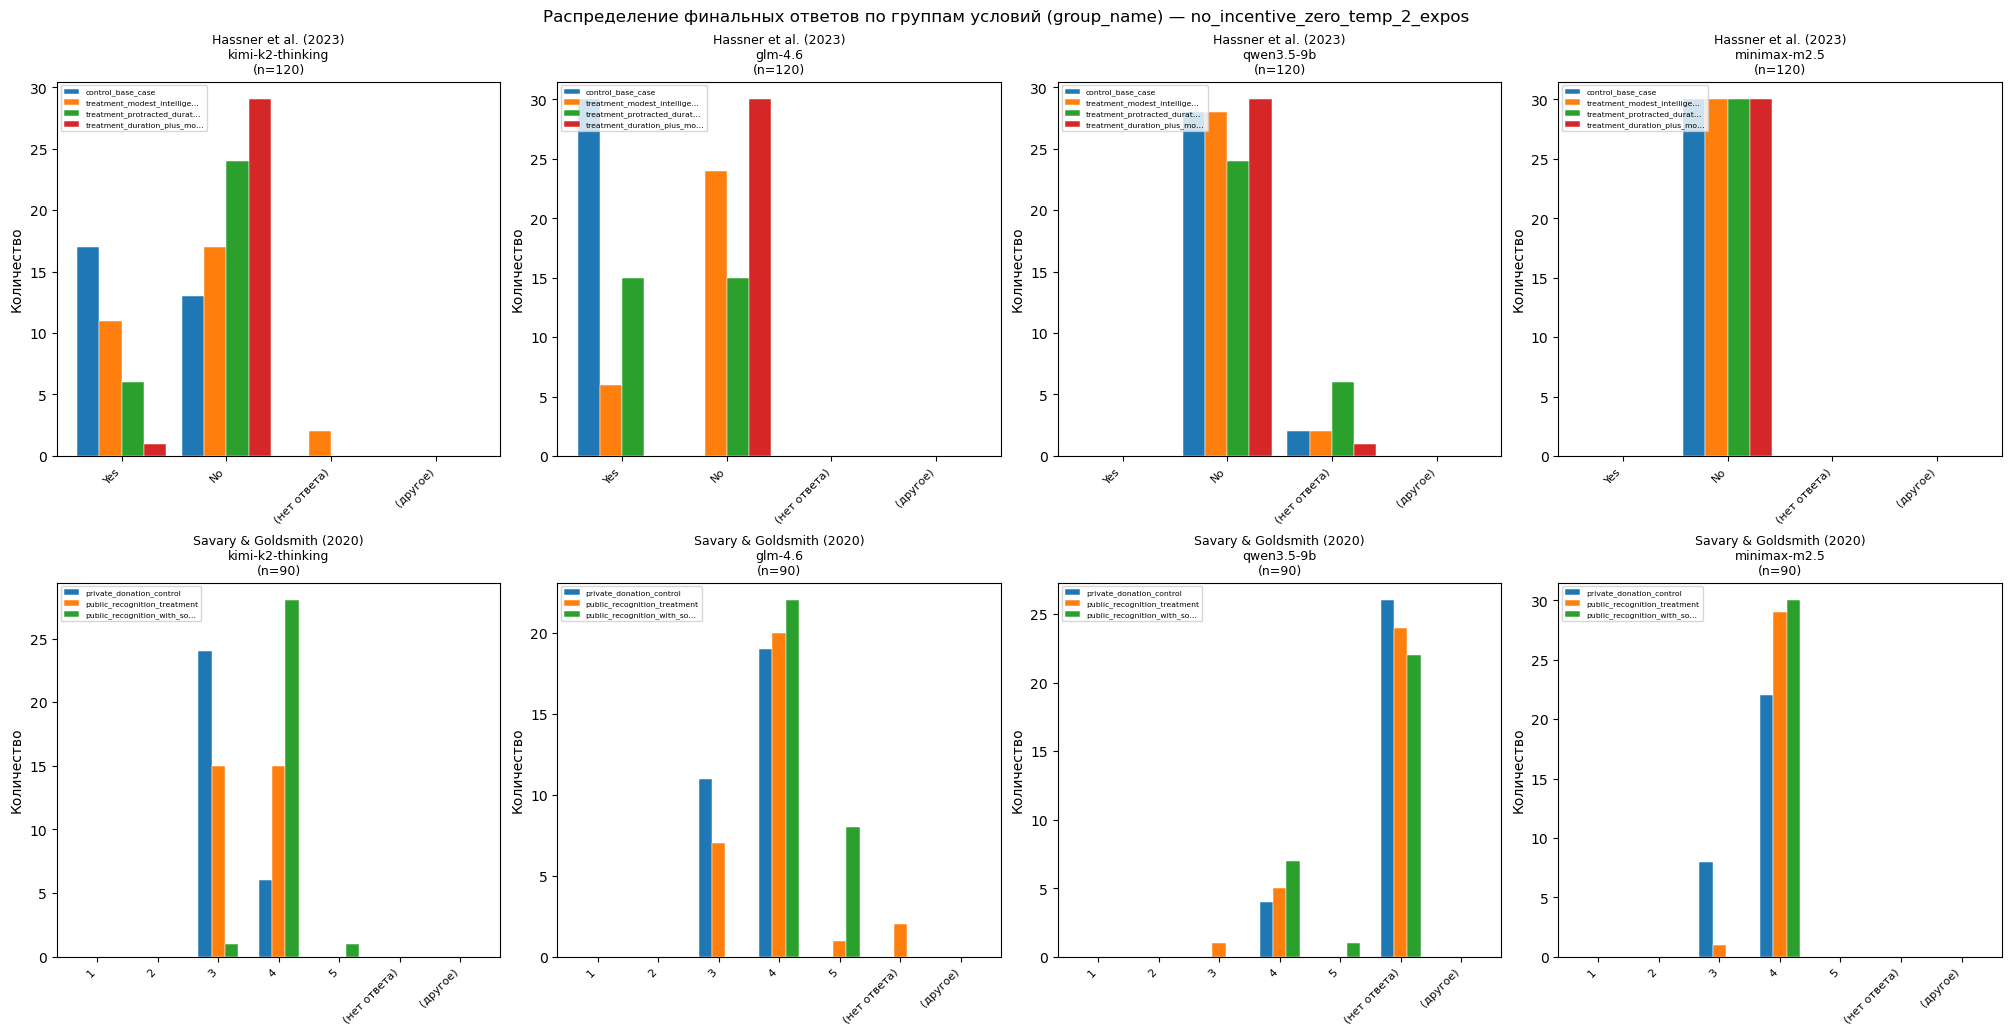

In [ ]:
# Распределение ответов: 2 эксперимента × 4 модели; внутри панели — группы (group_name)
import re
import numpy as np
import matplotlib.pyplot as plt

VIEW_RUN_ID = "no_incentive_zero_temp_2_expos_reasoning_trace"  # как в run_id прогона (ячейка sharp_results)
_path = RUNS_DIR / VIEW_RUN_ID / "responses_final.parquet"
if not _path.is_file():
    raise FileNotFoundError(f"Нет {_path} — сначала прогон или смените VIEW_RUN_ID")

_plot_df = pd.read_parquet(_path)

EXPERIMENTS = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE = {
    EXPERIMENTS[0]: "Hassner et al. (2023)",
    EXPERIMENTS[1]: "Savary & Goldsmith (2020)",
}

# Порядок условий (как в two_experiments_…json); неизвестные группы добавляются в конец
GROUP_ORDER: Dict[str, List[str]] = {
    EXPERIMENTS[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}


def _ordered_groups_for_panel(exp: str, present: List[str]) -> List[str]:
    base = list(GROUP_ORDER.get(exp, []))
    out = [g for g in base if g in present]
    for g in sorted(present):
        if g not in out:
            out.append(g)
    return out


def _group_label_short(name: str) -> str:
    if len(name) <= 28:
        return name
    return name[:26] + "…"


_model_order = [m for m in models if m in set(_plot_df["model"])]
for m in _plot_df["model"].unique():
    if m not in _model_order:
        _model_order.append(m)


def _bucket_answer(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    if "Savary" in experiment_name or "Donate" in experiment_name:
        m = re.search(r"\b([1-5])\b", s)
        if m:
            return m.group(1)
        return "(другое)"
    return "(другое)"


def _cat_order(experiment_name: str) -> List[str]:
    if "Hassner" in experiment_name:
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


_plot_df = _plot_df.copy()
_plot_df["answer_cat"] = _plot_df.apply(
    lambda r: _bucket_answer(r["final_answer_text"], r["experiment_name"]), axis=1
)

fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
for i, exp in enumerate(EXPERIMENTS):
    cats = _cat_order(exp)
    x = np.arange(len(cats))
    for j, model in enumerate(_model_order):
        ax = axes[i, j]
        sub = _plot_df[(_plot_df["experiment_name"] == exp) & (_plot_df["model"] == model)]
        present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
        groups = _ordered_groups_for_panel(exp, present_groups)
        n_g = len(groups)
        if n_g == 0:
            ax.set_visible(False)
            continue
        width = min(0.85 / n_g, 0.22)
        for gi, gname in enumerate(groups):
            subg = sub[sub["group_name"].astype(str) == gname]
            vc = subg["answer_cat"].value_counts()
            heights = [int(vc.get(c, 0)) for c in cats]
            offset = (gi - (n_g - 1) / 2) * width
            ax.bar(
                x + offset,
                heights,
                width,
                label=_group_label_short(gname),
                color=f"C{gi % 10}",
                edgecolor="white",
                linewidth=0.35,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
        short = model.split("/")[-1]
        ax.set_title(f"{EXP_TITLE[exp]}\n{short}\n(n={len(sub)})", fontsize=9)
        ax.set_ylabel("Количество")
        ax.legend(fontsize=5.5, loc="upper left", frameon=True)

fig.suptitle(
    f"Распределение финальных ответов по группам условий (group_name) — {VIEW_RUN_ID}",
    fontsize=12,
    y=1.02,
)
plt.show()


### non-reasoning
- без стимула
- reasoning: отключен
- 2 экспа
- 30 респондентов

In [ ]:
# non-reasoning — (1) сбор датасета (reasoning отключён в extra_body)
# Нужны: models, build_requests_dataset, SHARP_TEMPLATE_MAP, experiments_for_run,
# SHARP_NUM_RESPONDENTS_PER_CONDITION, selected_profiles, RANDOM_SEED

NON_REASONING_EXTRA_BODY: Dict[str, Any] = {
    "enabled": False,
    "exclude": True,
}

two_experiments_requests_df_nonreasoning = build_requests_dataset(
    models_list=models,
    templates_map=SHARP_TEMPLATE_MAP,
    experiments=experiments_for_run,
    num_respondents=SHARP_NUM_RESPONDENTS_PER_CONDITION,
    respondent_profiles=selected_profiles,
    reasoning_extra_body=NON_REASONING_EXTRA_BODY,
    base_seed=RANDOM_SEED,
)
print(
    "two_experiments_requests_df_nonreasoning rows:",
    len(two_experiments_requests_df_nonreasoning),
    "| logical jobs:",
    two_experiments_requests_df_nonreasoning["logical_job_id"].nunique(),
)

two_experiments_requests_df_nonreasoning rows: 840 | logical jobs: 840


In [ ]:
# non-reasoning — (2) запросы к API
from IPython.display import display

# Нужны: run_sdb_experiments_async, SHARP_TEMPERATURE, two_experiments_requests_df_nonreasoning

sharp_results_nonreasoning = await run_sdb_experiments_async(
    requests_df=two_experiments_requests_df_nonreasoning,
    temperature=SHARP_TEMPERATURE,
    run_id="no_incentive_zero_temp_2_expos_nonreasoning",
    resume=True,
    max_concurrency=8,
    batch_size=120,
    checkpoint_every=100,
)
display(sharp_results_nonreasoning["responses_df"].head())
display(sharp_results_nonreasoning["usage_summary_df"].head())


Всего логических задач:   0%|          | 0/840 [00:00<?, ?job/s]

moonshotai/kimi-k2-thinking:   0%|          | 0/210 [00:00<?, ?job/s]

z-ai/glm-4.6:   0%|          | 0/210 [00:00<?, ?job/s]

qwen/qwen3.5-9b:   0%|          | 0/210 [00:00<?, ?job/s]

minimax/minimax-m2.5:   0%|          | 0/210 [00:00<?, ?job/s]

Run ID: no_incentive_zero_temp_2_expos_nonreasoning
Completed rows: 840 / 840
Missing usage share: 0.5000
Total tokens used: 80400
Top errors:
error_message
Error code: 400 - {'error': {'message': 'Reasoning is mandatory for this endpoint and cannot be disabled.', 'code': 400, 'metadata': {'provider_name': None}}, 'user_id': 'user_37ogpsgTteNTWEMKawAWMHO5UlK'}    420
Name: count, dtype: int64


,job_id,seed,model,template_name,template_type,experiment_name,group_name,respondent_id,profile_id,profile_pid,...,usage_missing,retry_attempts_stage1,retry_attempts_stage2,stage1_reasoning_text,stage1_reasoning_details_json,stage1_reasoning_trace,stage2_reasoning_text,stage2_reasoning_details_json,stage2_reasoning_trace,reasoning_trace_combined
0,1,43,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,1,<NA>,None,...,True,5,None,,None,,,None,,
1,2,44,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,2,<NA>,None,...,True,5,None,,None,,,None,,
2,3,45,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,3,<NA>,None,...,True,5,None,,None,,,None,,
3,4,46,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,4,<NA>,None,...,True,5,None,,None,,,None,,
4,5,47,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,5,<NA>,None,...,True,5,None,,None,,,None,,


,model,template_name,experiment_name,group_name,respondents,ok_rows,error_rows,total_tokens_sum,stage1_tokens_sum,stage2_tokens_sum,usage_missing_rows,avg_tokens_per_row
0,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,30,0,30,0.0,0.0,0,30,0.0
1,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_duration_plus_modest_intelligence,30,0,30,0.0,0.0,0,30,0.0
2,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_modest_intelligence,30,0,30,0.0,0.0,0,30,0.0
3,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_protracted_duration,30,0,30,0.0,0.0,0,30,0.0
4,minimax/minimax-m2.5,one_stage_attitude_expression,Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate,private_donation_control,30,0,30,0.0,0.0,0,30,0.0


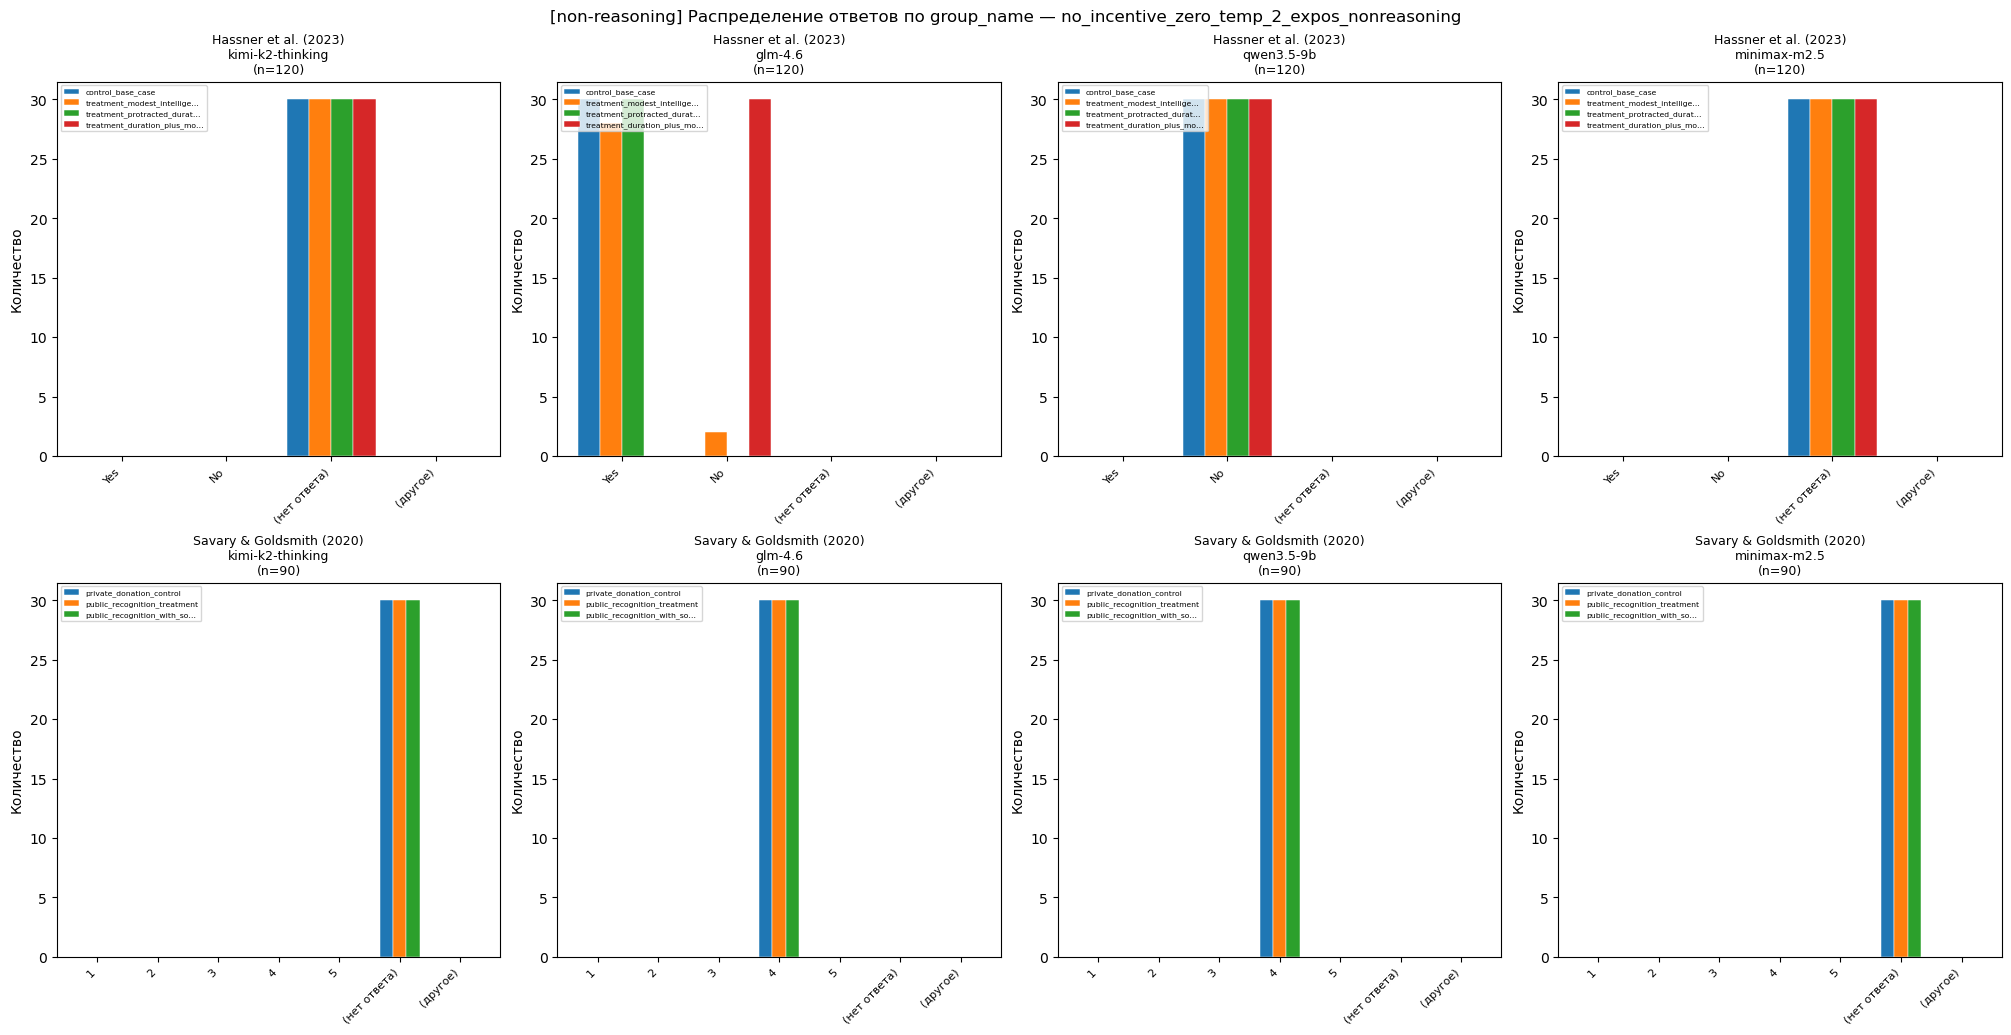

In [ ]:
# non-reasoning — (3) анализ: столбчатые диаграммы по моделям, экспериментам и group_name
import re
import numpy as np
import matplotlib.pyplot as plt

VIEW_RUN_ID_NR = "no_incentive_zero_temp_2_expos_nonreasoning"
_path_nr = RUNS_DIR / VIEW_RUN_ID_NR / "responses_final.parquet"
if not _path_nr.is_file():
    raise FileNotFoundError(f"Нет {_path_nr} — сначала выполните ячейку с прогоном API выше")

_plot_nr = pd.read_parquet(_path_nr)

EXPERIMENTS_NR = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE_NR = {
    EXPERIMENTS_NR[0]: "Hassner et al. (2023)",
    EXPERIMENTS_NR[1]: "Savary & Goldsmith (2020)",
}

GROUP_ORDER_NR: Dict[str, List[str]] = {
    EXPERIMENTS_NR[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS_NR[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}


def _ordered_groups_nr(exp: str, present: List[str]) -> List[str]:
    base = list(GROUP_ORDER_NR.get(exp, []))
    out = [g for g in base if g in present]
    for g in sorted(present):
        if g not in out:
            out.append(g)
    return out


def _group_label_short_nr(name: str) -> str:
    if len(name) <= 28:
        return name
    return name[:26] + "…"


def _bucket_nr(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    if "Savary" in experiment_name or "Donate" in experiment_name:
        m = re.search(r"\b([1-5])\b", s)
        if m:
            return m.group(1)
        return "(другое)"
    return "(другое)"


def _cat_order_nr(experiment_name: str) -> List[str]:
    if "Hassner" in experiment_name:
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


_plot_nr = _plot_nr.copy()
_plot_nr["answer_cat"] = _plot_nr.apply(
    lambda r: _bucket_nr(r["final_answer_text"], r["experiment_name"]), axis=1
)

_model_order_nr = [m for m in models if m in set(_plot_nr["model"])]
for m in _plot_nr["model"].unique():
    if m not in _model_order_nr:
        _model_order_nr.append(m)

fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
for i, exp in enumerate(EXPERIMENTS_NR):
    cats = _cat_order_nr(exp)
    x = np.arange(len(cats))
    for j, model in enumerate(_model_order_nr):
        ax = axes[i, j]
        sub = _plot_nr[(_plot_nr["experiment_name"] == exp) & (_plot_nr["model"] == model)]
        present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
        groups = _ordered_groups_nr(exp, present_groups)
        n_g = len(groups)
        if n_g == 0:
            ax.set_visible(False)
            continue
        width = min(0.85 / n_g, 0.22)
        for gi, gname in enumerate(groups):
            subg = sub[sub["group_name"].astype(str) == gname]
            vc = subg["answer_cat"].value_counts()
            heights = [int(vc.get(c, 0)) for c in cats]
            offset = (gi - (n_g - 1) / 2) * width
            ax.bar(
                x + offset,
                heights,
                width,
                label=_group_label_short_nr(gname),
                color=f"C{gi % 10}",
                edgecolor="white",
                linewidth=0.35,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
        short = model.split("/")[-1]
        ax.set_title(f"{EXP_TITLE_NR[exp]}\n{short}\n(n={len(sub)})", fontsize=9)
        ax.set_ylabel("Количество")
        ax.legend(fontsize=5.5, loc="upper left", frameon=True)

fig.suptitle(
    f"[non-reasoning] Распределение ответов по group_name — {VIEW_RUN_ID_NR}",
    fontsize=12,
    y=1.02,
)
plt.show()

In [ ]:
# non-reasoning — только Kimi и Minimax: оба эксперимента из `experiments_for_run`, reasoning выключен
# Нужны: NON_REASONING_EXTRA_BODY, SHARP_TEMPLATE_MAP, experiments_for_run, SHARP_NUM_RESPONDENTS_PER_CONDITION,
# selected_profiles, RANDOM_SEED, run_sdb_experiments_async, SHARP_TEMPERATURE

from IPython.display import display

MODELS_KIMI_MINIMAX = [
    "moonshotai/kimi-k2-thinking",
    "minimax/minimax-m2.5",
]

two_experiments_requests_df_nr_kimi_minimax = build_requests_dataset(
    models_list=MODELS_KIMI_MINIMAX,
    templates_map=SHARP_TEMPLATE_MAP,
    experiments=experiments_for_run,
    num_respondents=SHARP_NUM_RESPONDENTS_PER_CONDITION,
    respondent_profiles=selected_profiles,
    reasoning_extra_body=NON_REASONING_EXTRA_BODY,
    base_seed=RANDOM_SEED,
)
print(
    "two_experiments_requests_df_nr_kimi_minimax rows:",
    len(two_experiments_requests_df_nr_kimi_minimax),
    "| logical jobs:",
    two_experiments_requests_df_nr_kimi_minimax["logical_job_id"].nunique(),
)

sharp_results_nr_kimi_minimax = await run_sdb_experiments_async(
    requests_df=two_experiments_requests_df_nr_kimi_minimax,
    temperature=SHARP_TEMPERATURE,
    run_id="no_incentive_zero_temp_2_expos_nonreasoning_kimi_minimax",
    resume=True,
    max_concurrency=8,
    batch_size=120,
    checkpoint_every=100,
)
display(sharp_results_nr_kimi_minimax["responses_df"].head())
display(sharp_results_nr_kimi_minimax["usage_summary_df"].head())


### базовый incentive
- t = 0.01 (как SHARP_TEMPERATURE)
- инсентив **C_balanced_realism** из `incentives.json` в system prompt
- reasoning: включён, **reasoning trace** собирается отдельно (`exclude: false`)
- 2 экспа, 30 респондентов на условие


In [ ]:
# базовый incentive — (1) датасет: reasoning включён, trace в ответе API (exclude=False), инсентив C_balanced_realism
# Нужны: models, SHARP_TEMPLATE_MAP, experiments_for_run, SHARP_NUM_RESPONDENTS_PER_CONDITION, selected_profiles, build_requests_dataset, INCENTIVES_PATH

REASONING_TRACE_BODY: Dict[str, Any] = {
    "enabled": True,
    "exclude": False,
}

BALANCED_INCENTIVE_RUN_ID = "incentive_C_balanced_realism_reasoning_trace"

two_experiments_requests_df_balanced = build_requests_dataset(
    models_list=models,
    templates_map=SHARP_TEMPLATE_MAP,
    experiments=experiments_for_run,
    num_respondents=SHARP_NUM_RESPONDENTS_PER_CONDITION,
    respondent_profiles=selected_profiles,
    reasoning_extra_body=REASONING_TRACE_BODY,
    base_seed=RANDOM_SEED,
    incentive_key="C_balanced_realism",
)
print(
    "two_experiments_requests_df_balanced rows:",
    len(two_experiments_requests_df_balanced),
    "| logical jobs:",
    two_experiments_requests_df_balanced["logical_job_id"].nunique(),
)


In [ ]:
# базовый incentive — (2) запросы к API
from IPython.display import display

sharp_results_balanced = await run_sdb_experiments_async(
    requests_df=two_experiments_requests_df_balanced,
    temperature=SHARP_TEMPERATURE,
    run_id=BALANCED_INCENTIVE_RUN_ID,
    resume=True,
    max_concurrency=8,
    batch_size=120,
    checkpoint_every=100,
)
display(sharp_results_balanced["responses_df"].head())
display(sharp_results_balanced["usage_summary_df"].head())


In [ ]:
# базовый incentive — (3) анализ: распределения (те же графики, что для no-incentive прогона)
import re
import numpy as np
import matplotlib.pyplot as plt

VIEW_RUN_ID_BAL = BALANCED_INCENTIVE_RUN_ID
_path_b = RUNS_DIR / VIEW_RUN_ID_BAL / "responses_final.parquet"
if not _path_b.is_file():
    raise FileNotFoundError(f"Нет {_path_b} — сначала выполните прогон API выше")

_plot_b = pd.read_parquet(_path_b)

EXPERIMENTS_B = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE_B = {
    EXPERIMENTS_B[0]: "Hassner et al. (2023)",
    EXPERIMENTS_B[1]: "Savary & Goldsmith (2020)",
}

GROUP_ORDER_B: Dict[str, List[str]] = {
    EXPERIMENTS_B[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS_B[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}


def _ordered_groups_b(exp: str, present: List[str]) -> List[str]:
    base = list(GROUP_ORDER_B.get(exp, []))
    out = [g for g in base if g in present]
    for g in sorted(present):
        if g not in out:
            out.append(g)
    return out


def _group_label_short_b(name: str) -> str:
    if len(name) <= 28:
        return name
    return name[:26] + "…"


def _bucket_b(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    if "Savary" in experiment_name or "Donate" in experiment_name:
        m = re.search(r"\b([1-5])\b", s)
        if m:
            return m.group(1)
        return "(другое)"
    return "(другое)"


def _cat_order_b(experiment_name: str) -> List[str]:
    if "Hassner" in experiment_name:
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


_plot_b = _plot_b.copy()
_plot_b["answer_cat"] = _plot_b.apply(
    lambda r: _bucket_b(r["final_answer_text"], r["experiment_name"]), axis=1
)

_model_order_b = [m for m in models if m in set(_plot_b["model"])]
for m in _plot_b["model"].unique():
    if m not in _model_order_b:
        _model_order_b.append(m)

fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
for i, exp in enumerate(EXPERIMENTS_B):
    cats = _cat_order_b(exp)
    x = np.arange(len(cats))
    for j, model in enumerate(_model_order_b):
        ax = axes[i, j]
        sub = _plot_b[(_plot_b["experiment_name"] == exp) & (_plot_b["model"] == model)]
        present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
        groups = _ordered_groups_b(exp, present_groups)
        n_g = len(groups)
        if n_g == 0:
            ax.set_visible(False)
            continue
        width = min(0.85 / n_g, 0.22)
        for gi, gname in enumerate(groups):
            subg = sub[sub["group_name"].astype(str) == gname]
            vc = subg["answer_cat"].value_counts()
            heights = [int(vc.get(c, 0)) for c in cats]
            offset = (gi - (n_g - 1) / 2) * width
            ax.bar(
                x + offset,
                heights,
                width,
                label=_group_label_short_b(gname),
                color=f"C{gi % 10}",
                edgecolor="white",
                linewidth=0.35,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
        short = model.split("/")[-1]
        ax.set_title(f"{EXP_TITLE_B[exp]}\n{short}\n(n={len(sub)})", fontsize=9)
        ax.set_ylabel("Количество")
        ax.legend(fontsize=5.5, loc="upper left", frameon=True)

fig.suptitle(
    f"[C_balanced_realism + reasoning trace] Распределение по group_name — {VIEW_RUN_ID_BAL}",
    fontsize=12,
    y=1.02,
)
plt.show()


NameError: name 'BALANCED_INCENTIVE_RUN_ID' is not defined

### Тест: отдельный trace и отдельный final answer
По одному короткому запросу на каждую модель из `models`: `reasoning.enabled=true`, `exclude=false`. Trace — `extract_reasoning_trace_from_message`; финальный ответ — `extract_final_answer` из `content`, иначе из `_assistant_reply_text`.


In [ ]:
# Тест сетапа (каждая модель из `models`): reasoning включён, trace отдельно + final answer отдельно
# Нужны: client, models, build_openrouter_extra_body_for_model, extract_reasoning_trace_from_message,
# `_assistant_reply_text`, `extract_final_answer`, asyncio, pandas.
from IPython.display import display

REASONING_TRACE_TEST_BODY: Dict[str, Any] = {
    "enabled": True,
    "exclude": False,
}


def _split_trace_and_final_answer(msg: Any) -> Dict[str, Any]:
    """Отдельно: полный reasoning trace (из полей reasoning / reasoning_details) и финальный ответ по тем же правилам, что в прогоне."""
    fields = extract_reasoning_trace_from_message(msg)
    trace_full = (fields.get("reasoning_trace") or "").strip()

    content_only = getattr(msg, "content", None)
    if content_only is None:
        content_only = ""
    elif not isinstance(content_only, str):
        content_only = str(content_only)

    visible = _assistant_reply_text(msg)
    # Сначала парсим final answer из чистого content (финальный канал ответа)
    final_ans = extract_final_answer(content_only)
    # Если модель положила всё в reasoning, а content пуст — пробуем видимый текст целиком
    if not (final_ans or "").strip():
        final_ans = extract_final_answer(visible)

    return {
        "reasoning_trace": trace_full,
        "content_raw": content_only,
        "visible_reply": visible,
        "final_answer_extracted": (final_ans or "").strip(),
    }


async def _one_model_reasoning_trace_test(model: str) -> Dict[str, Any]:
    out: Dict[str, Any] = {
        "model": model,
        "ok": False,
        "reasoning_trace_len": 0,
        "final_answer": "",
        "content_len": 0,
        "trace_preview": "",
        "final_answer_ok": False,
        "error": None,
    }
    try:
        completion = await client.chat.completions.create(
            model=model,
            messages=[
                {"role": "system", "content": "You are a helpful assistant."},
                {
                    "role": "user",
                    "content": (
                        "Briefly reason step by step, then give a final line exactly: "
                        "Final answer: YES or Final answer: NO. "
                        "Question: Is ice made of frozen water?"
                    ),
                },
            ],
            temperature=0.2,
            max_tokens=512,
            extra_body=build_openrouter_extra_body_for_model(
                model, REASONING_TRACE_TEST_BODY
            ),
        )
        msg = completion.choices[0].message
        sp = _split_trace_and_final_answer(msg)
        trace = sp["reasoning_trace"]
        fa = sp["final_answer_extracted"]
        content_raw = sp["content_raw"]

        out["reasoning_trace_len"] = len(trace)
        out["content_len"] = len(content_raw or "")
        out["final_answer"] = fa
        out["trace_preview"] = trace[:320]
        out["final_answer_ok"] = bool(
            fa and fa.upper().strip().replace(".", "") in ("YES", "NO")
        )
        out["ok"] = bool(trace) or bool((content_raw or "").strip()) or bool(fa)
    except Exception as exc:
        out["error"] = repr(exc)
    return out


async def run_reasoning_trace_test_all_models() -> pd.DataFrame:
    rows = []
    for m in models:
        rows.append(await _one_model_reasoning_trace_test(m))
    return pd.DataFrame(rows)


df_reasoning_trace_setup = await run_reasoning_trace_test_all_models()
display(df_reasoning_trace_setup)
print(
    "reasoning_trace — отдельное поле trace (reasoning + reasoning_details); "
    "final_answer — extract_final_answer(content), иначе из видимого ответа. "
    "final_answer_ok — распознан ли YES/NO."
)


,model,ok,reasoning_trace_len,final_answer,content_len,trace_preview,final_answer_ok,error
0,moonshotai/kimi-k2-thinking,True,1721,YES,265,"The user asks: ""Is ice made of frozen water?"" This is a straightforward factual question. I need...",True,None
1,z-ai/glm-4.6,True,4749,YES,201,"1. **Analyze the user's request:** The user wants a brief, step-by-step reasoning followed by a...",True,None
2,qwen/qwen3.5-9b,True,3410,YES,257,Thinking Process:\n\n1. **Analyze the Request:**\n * Task: Briefly reason step by step.\n ...,True,None
3,minimax/minimax-m2.5,True,3137,YES,185,"The user asks: ""Briefly reason step by step, then give a final line exactly: Final answer: YES o...",True,None


reasoning_trace — отдельное поле trace (reasoning + reasoning_details); final_answer — extract_final_answer(content), иначе из видимого ответа. final_answer_ok — распознан ли YES/NO.


### Тест: Kimi и Minimax при отключённом reasoning
По **два** коротких запроса на модель (`reasoning.enabled=false`, `exclude=true`, как в non-reasoning прогоне). Проверяем: успешен ли вызов API и извлекается ли строка с `Final answer` через `extract_final_answer`.


In [ ]:
# Тест: при отключённом reasoning — отдают ли Kimi/Minimax видимый ответ и Final answer
# Нужны: client, _chat_completion_with_retry, extract_final_answer, pandas, typing

from IPython.display import display

NON_REASONING_SMOKETEST_BODY: Dict[str, Any] = {
    "enabled": False,
    "exclude": True,
}

MODELS_NR_SMOKETEST = [
    "moonshotai/kimi-k2-thinking",
    "minimax/minimax-m2.5",
]

_USER_PROMPTS_NR = [
    (
        "You are a helpful assistant.",
        "Reply briefly. Last line must be exactly: Final answer: YES or Final answer: NO. "
        "Question: Is 2+2 equal to 4?",
    ),
    (
        "You are a helpful assistant.",
        "Last line must be exactly: Final answer: YES or Final answer: NO. "
        "Question: Is ice made of frozen water?",
    ),
]


async def _one_nr_smoketest(
    model: str, prompt_idx: int, system_text: str, user_text: str
) -> Dict[str, Any]:
    st = await _chat_completion_with_retry(
        model=model,
        system_text=system_text,
        user_text=user_text,
        reasoning_body=NON_REASONING_SMOKETEST_BODY,
        temperature=0.2,
    )
    rt = st.get("response_text") or ""
    err = st.get("error_message")
    fa = extract_final_answer(rt)
    return {
        "model": model,
        "prompt_idx": prompt_idx,
        "ok_http": bool(st.get("ok")),
        "error": err,
        "response_len": len(rt),
        "response_preview": ((rt[:400] + "…") if len(rt) > 400 else rt),
        "final_answer": fa,
        "final_answer_ok": bool(
            fa and fa.upper().strip().replace(".", "") in ("YES", "NO")
        ),
    }


async def run_nonreasoning_smoketest_kimi_minimax() -> pd.DataFrame:
    rows: List[Dict[str, Any]] = []
    for m in MODELS_NR_SMOKETEST:
        for i, (sys_t, usr_t) in enumerate(_USER_PROMPTS_NR, start=1):
            rows.append(await _one_nr_smoketest(m, i, sys_t, usr_t))
    return pd.DataFrame(rows)


df_nonreasoning_km_smoketest = await run_nonreasoning_smoketest_kimi_minimax()
display(df_nonreasoning_km_smoketest)
print(
    "ok_http — успешный ответ API; error — сообщение при сбое; "
    "final_answer — extract_final_answer(response_text); final_answer_ok — распознан ли YES/NO."
)


,model,prompt_idx,ok_http,error,response_len,response_preview,final_answer,final_answer_ok
0,moonshotai/kimi-k2-thinking,1,False,Error code: 400 - {'error': {'message': 'Reasoning is mandatory for this endpoint and cannot be ...,0,,,False
1,moonshotai/kimi-k2-thinking,2,False,Error code: 400 - {'error': {'message': 'Reasoning is mandatory for this endpoint and cannot be ...,0,,,False
2,minimax/minimax-m2.5,1,False,Error code: 400 - {'error': {'message': 'Reasoning is mandatory for this endpoint and cannot be ...,0,,,False
3,minimax/minimax-m2.5,2,False,Error code: 400 - {'error': {'message': 'Reasoning is mandatory for this endpoint and cannot be ...,0,,,False


ok_http — успешный ответ API; error — сообщение при сбое; final_answer — extract_final_answer(response_text); final_answer_ok — распознан ли YES/NO.


### План: no incentive (50 респондентов)
- **t = 0.01**
- без инсентива в prompt (как в no-incentive прогоне выше)
- **reasoning:** включён, trace собирается (`reasoning.enabled=true`, `exclude=false`)
- два эксперимента из `two_experiments_hassner_savary_goldsmith.json`, **50** респондентов на каждое условие (group)


In [ ]:
# План 50 / no incentive — (1) сбор датасета: reasoning включён, trace в ответе API (`exclude=false`), без инсентива
# Нужны: models, SHARP_TEMPLATE_MAP, experiments_for_run, selected_profiles (≥50 профилей при Twin2k), RANDOM_SEED

PLAN50_NO_INC_RUN_ID = "no_incentive_50_reasoning_trace_p2"

REASONING_ON_TRACE_COLLECT_BODY: Dict[str, Any] = {
    "enabled": True,
    "exclude": False,
}

PLAN50_NUM_RESPONDENTS_PER_CONDITION = 50
PLAN50_TEMPERATURE = 0.01

two_experiments_requests_df_plan50_no_inc = build_requests_dataset(
    models_list=models,
    templates_map=SHARP_TEMPLATE_MAP,
    experiments=experiments_for_run,
    num_respondents=PLAN50_NUM_RESPONDENTS_PER_CONDITION,
    respondent_profiles=selected_profiles,
    reasoning_extra_body=REASONING_ON_TRACE_COLLECT_BODY,
    base_seed=RANDOM_SEED,
)
print(
    "two_experiments_requests_df_plan50_no_inc rows:",
    len(two_experiments_requests_df_plan50_no_inc),
    "| logical jobs:",
    two_experiments_requests_df_plan50_no_inc["logical_job_id"].nunique(),
)



two_experiments_requests_df_plan50_no_inc rows: 1400 | logical jobs: 1400


In [ ]:
# План 50 / no incentive — (2) прогон датасета
from IPython.display import display

sharp_results_plan50_no_inc = await run_sdb_experiments_async(
    requests_df=two_experiments_requests_df_plan50_no_inc,
    temperature=PLAN50_TEMPERATURE,
    run_id=PLAN50_NO_INC_RUN_ID,
    resume=True,
    max_concurrency=8,
    batch_size=120,
    checkpoint_every=100,
)
display(sharp_results_plan50_no_inc["responses_df"].head())
display(sharp_results_plan50_no_inc["usage_summary_df"].head())

Всего логических задач:   0%|          | 0/1400 [00:00<?, ?job/s]

moonshotai/kimi-k2-thinking:   0%|          | 0/350 [00:00<?, ?job/s]

z-ai/glm-4.6:   0%|          | 0/350 [00:00<?, ?job/s]

qwen/qwen3.5-9b:   0%|          | 0/350 [00:00<?, ?job/s]

minimax/minimax-m2.5:   0%|          | 0/350 [00:00<?, ?job/s]

Run ID: no_incentive_50_reasoning_trace_p2
Completed rows: 1400 / 1400
Missing usage share: 0.1043
Total tokens used: 1575684
Top errors:
error_message
Expecting value: line 433 column 1 (char 2376)    1
Name: count, dtype: int64


,job_id,seed,model,template_name,template_type,experiment_name,group_name,respondent_id,profile_id,profile_pid,...,usage_missing,retry_attempts_stage1,retry_attempts_stage2,stage1_reasoning_text,stage1_reasoning_details_json,stage1_reasoning_trace,stage2_reasoning_text,stage2_reasoning_details_json,stage2_reasoning_trace,reasoning_trace_combined
0,1,43,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,1,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to ...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...
1,2,44,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,2,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to ...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...
2,3,45,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,3,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to ...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...
3,4,46,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,4,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to ...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...
4,5,47,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,5,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to ...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...


,model,template_name,experiment_name,group_name,respondents,ok_rows,error_rows,total_tokens_sum,stage1_tokens_sum,stage2_tokens_sum,usage_missing_rows,avg_tokens_per_row
0,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,50,50,0,31623.0,31623.0,0,0,632.46
1,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_duration_plus_modest_intelligence,50,50,0,39301.0,39301.0,0,0,786.02
2,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_modest_intelligence,50,50,0,32067.0,32067.0,0,0,641.34
3,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_protracted_duration,50,50,0,37726.0,37726.0,0,0,754.52
4,minimax/minimax-m2.5,one_stage_attitude_expression,Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate,private_donation_control,50,50,0,32050.0,32050.0,0,0,641.00


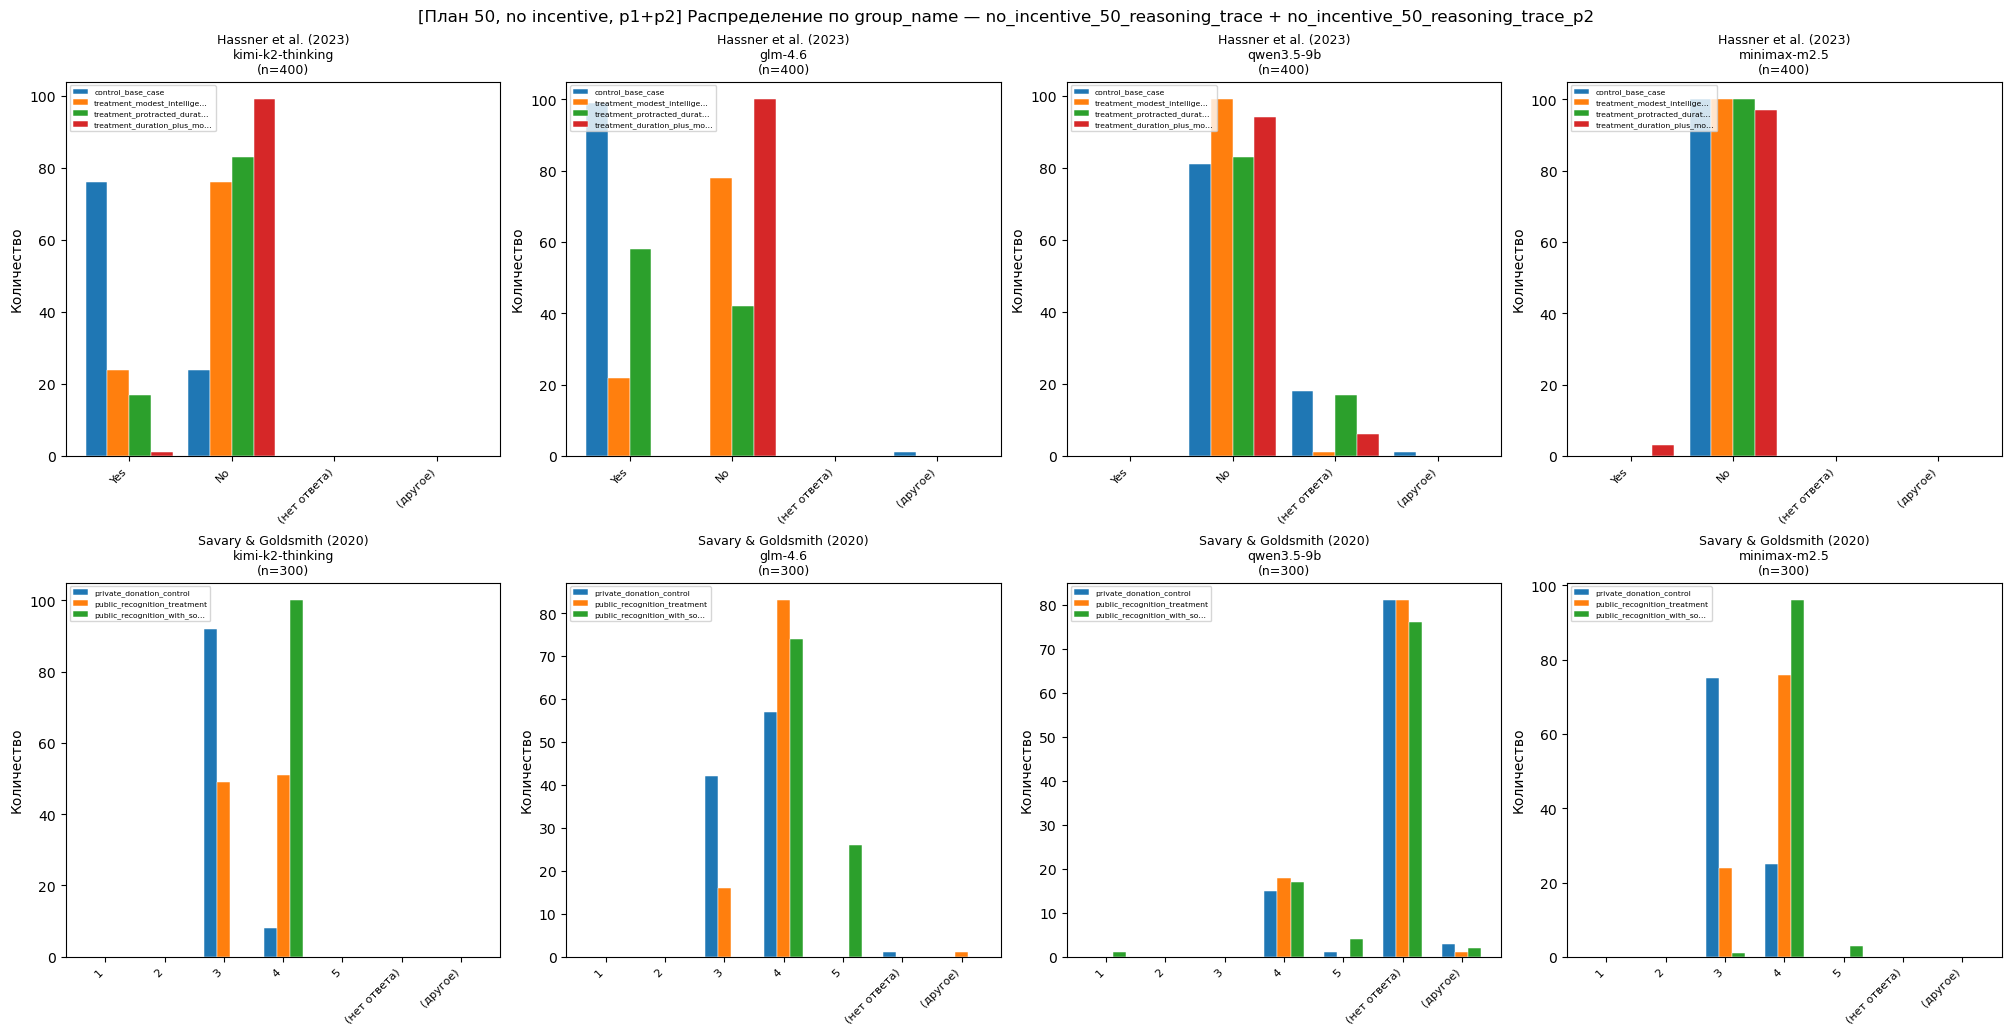

In [ ]:
# План 50 / no incentive — (3) анализ: распределения
# Распределение ответов: 2 эксперимента × 4 модели; внутри панели — группы (group_name)
import re
import numpy as np
import matplotlib.pyplot as plt

VIEW_RUN_ID_PLAN50_NO_INC = "no_incentive_50_reasoning_trace"
RUN_ID_PLAN50_NO_INC_P2 = "no_incentive_50_reasoning_trace_p2"

_path_plan50_no_inc_p1 = (
    RUNS_DIR / VIEW_RUN_ID_PLAN50_NO_INC / "responses_final_no_incentive_50_reasoning_trace.parquet"
)
_path_plan50_no_inc_p2 = (
    RUNS_DIR / RUN_ID_PLAN50_NO_INC_P2 / "responses_final_no_incentive_50_reasoning_trace_p2.parquet"
)
for _p in (_path_plan50_no_inc_p1, _path_plan50_no_inc_p2):
    if not _p.is_file():
        raise FileNotFoundError(
            f"Нет {_p} — нужны оба parquet (p1 и p2) для склейки no-incentive"
        )

_plot_plan50_no_inc = pd.concat(
    [
        pd.read_parquet(_path_plan50_no_inc_p1),
        pd.read_parquet(_path_plan50_no_inc_p2),
    ],
    ignore_index=True,
)
# p1 и p2 — разные прогоны: job_id в каждом файле обычно с 1…N, они пересекаются между частями.
# Дедуп по job_id после concat ошибочно убирал бы половину строк (~50 вместо 100 респондентов на условие).

EXPERIMENTS = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE = {
    EXPERIMENTS[0]: "Hassner et al. (2023)",
    EXPERIMENTS[1]: "Savary & Goldsmith (2020)",
}

# Порядок условий (как в two_experiments_…json); неизвестные группы добавляются в конец
GROUP_ORDER: Dict[str, List[str]] = {
    EXPERIMENTS[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}


def _ordered_groups_for_panel(exp: str, present: List[str]) -> List[str]:
    base = list(GROUP_ORDER.get(exp, []))
    out = [g for g in base if g in present]
    for g in sorted(present):
        if g not in out:
            out.append(g)
    return out


def _group_label_short(name: str) -> str:
    if len(name) <= 28:
        return name
    return name[:26] + "…"


_model_order_plan50_no_inc = [m for m in models if m in set(_plot_plan50_no_inc["model"])]
for m in _plot_plan50_no_inc["model"].unique():
    if m not in _model_order_plan50_no_inc:
        _model_order_plan50_no_inc.append(m)


def _bucket_answer(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    if "Savary" in experiment_name or "Donate" in experiment_name:
        m = re.search(r"\b([1-5])\b", s)
        if m:
            return m.group(1)
        return "(другое)"
    return "(другое)"


def _cat_order(experiment_name: str) -> List[str]:
    if "Hassner" in experiment_name:
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


_plot_plan50_no_inc = _plot_plan50_no_inc.copy()
_plot_plan50_no_inc["answer_cat"] = _plot_plan50_no_inc.apply(
    lambda r: _bucket_answer(r["final_answer_text"], r["experiment_name"]), axis=1
)

fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
for i, exp in enumerate(EXPERIMENTS):
    cats = _cat_order(exp)
    x = np.arange(len(cats))
    for j, model in enumerate(_model_order_plan50_no_inc):
        ax = axes[i, j]
        sub = _plot_plan50_no_inc[(_plot_plan50_no_inc["experiment_name"] == exp) & (_plot_plan50_no_inc["model"] == model)]
        present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
        groups = _ordered_groups_for_panel(exp, present_groups)
        n_g = len(groups)
        if n_g == 0:
            ax.set_visible(False)
            continue
        width = min(0.85 / n_g, 0.22)
        for gi, gname in enumerate(groups):
            subg = sub[sub["group_name"].astype(str) == gname]
            vc = subg["answer_cat"].value_counts()
            heights = [int(vc.get(c, 0)) for c in cats]
            offset = (gi - (n_g - 1) / 2) * width
            ax.bar(
                x + offset,
                heights,
                width,
                label=_group_label_short(gname),
                color=f"C{gi % 10}",
                edgecolor="white",
                linewidth=0.35,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
        short = model.split("/")[-1]
        ax.set_title(f"{EXP_TITLE[exp]}\n{short}\n(n={len(sub)})", fontsize=9)
        ax.set_ylabel("Количество")
        ax.legend(fontsize=5.5, loc="upper left", frameon=True)

fig.suptitle(
    f"[План 50, no incentive, p1+p2] Распределение по group_name — {VIEW_RUN_ID_PLAN50_NO_INC} + {RUN_ID_PLAN50_NO_INC_P2}",
    fontsize=12,
    y=1.02,
)
plt.show()



### temp = 1.0 — no incentive (50 респондентов)
- как **План 50 / no incentive** выше, но **температура 1.0** (вместо 0.01)
- без инсентива, **reasoning** включён и trace собирается (`exclude=false`)
- отдельный `run_id`, чтобы не перезаписать прогон при t=0.01


In [ ]:
# no incentive, t=1.0 — (1) сбор датасета
# Нужны: models, SHARP_TEMPLATE_MAP, experiments_for_run, selected_profiles, RANDOM_SEED

PLAN50_NO_INC_T1_RUN_ID = "no_incentive_50_reasoning_trace_t1"
PLAN50_TEMP_NO_INC_T1 = 1.0

REASONING_ON_TRACE_COLLECT_BODY_NO_INC_T1: Dict[str, Any] = {
    "enabled": True,
    "exclude": False,
}

two_experiments_requests_df_plan50_no_inc_t1 = build_requests_dataset(
    models_list=models,
    templates_map=SHARP_TEMPLATE_MAP,
    experiments=experiments_for_run,
    num_respondents=50,
    respondent_profiles=selected_profiles,
    reasoning_extra_body=REASONING_ON_TRACE_COLLECT_BODY_NO_INC_T1,
    base_seed=RANDOM_SEED,
)
print(
    "two_experiments_requests_df_plan50_no_inc_t1 rows:",
    len(two_experiments_requests_df_plan50_no_inc_t1),
    "| logical jobs:",
    two_experiments_requests_df_plan50_no_inc_t1["logical_job_id"].nunique(),
)


two_experiments_requests_df_plan50_no_inc_t1 rows: 1400 | logical jobs: 1400


In [ ]:
# no incentive, t=1.0 — (2) прогон датасета
from IPython.display import display

sharp_results_plan50_no_inc_t1 = await run_sdb_experiments_async(
    requests_df=two_experiments_requests_df_plan50_no_inc_t1,
    temperature=PLAN50_TEMP_NO_INC_T1,
    run_id=PLAN50_NO_INC_T1_RUN_ID,
    resume=True,
    max_concurrency=8,
    batch_size=120,
    checkpoint_every=100,
)
display(sharp_results_plan50_no_inc_t1["responses_df"].head())
display(sharp_results_plan50_no_inc_t1["usage_summary_df"].head())


Всего логических задач:   0%|          | 0/1400 [00:00<?, ?job/s]

moonshotai/kimi-k2-thinking:   0%|          | 0/350 [00:00<?, ?job/s]

z-ai/glm-4.6:   0%|          | 0/350 [00:00<?, ?job/s]

qwen/qwen3.5-9b:   0%|          | 0/350 [00:00<?, ?job/s]

minimax/minimax-m2.5:   0%|          | 0/350 [00:00<?, ?job/s]

Run ID: no_incentive_50_reasoning_trace_t1
Completed rows: 1400 / 1400
Missing usage share: 0.0014
Total tokens used: 2199835


,job_id,seed,model,template_name,template_type,experiment_name,group_name,respondent_id,profile_id,profile_pid,...,usage_missing,retry_attempts_stage1,retry_attempts_stage2,stage1_reasoning_text,stage1_reasoning_details_json,stage1_reasoning_trace,stage2_reasoning_text,stage2_reasoning_details_json,stage2_reasoning_trace,reasoning_trace_combined
0,1,43,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,1,<NA>,None,...,False,0,None,The user wants me to role-play as a plausible survey respondent in a vignette-based study.\n Th...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to role-play as a plausible survey respo...",The user wants me to role-play as a plausible survey respondent in a vignette-based study.\n The...,,None,,The user wants me to role-play as a plausible survey respondent in a vignette-based study.\n The...
1,2,44,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,2,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to ...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. I need to r...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to r...
2,3,45,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,3,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study.\n The vign...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study.\n The vigne...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study.\n The vigne...
3,4,46,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,4,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to ...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. I need to c...
4,5,47,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,5,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study.\n\nThe vig...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study.\n\nThe vign...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study.\n\nThe vign...


,model,template_name,experiment_name,group_name,respondents,ok_rows,error_rows,total_tokens_sum,stage1_tokens_sum,stage2_tokens_sum,usage_missing_rows,avg_tokens_per_row
0,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,50,50,0,30269.0,30269.0,0,0,605.38
1,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_duration_plus_modest_intelligence,50,50,0,29868.0,29868.0,0,0,597.36
2,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_modest_intelligence,50,50,0,31535.0,31535.0,0,0,630.70
3,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_protracted_duration,50,50,0,29762.0,29762.0,0,0,595.24
4,minimax/minimax-m2.5,one_stage_attitude_expression,Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate,private_donation_control,50,50,0,32443.0,32443.0,0,0,648.86


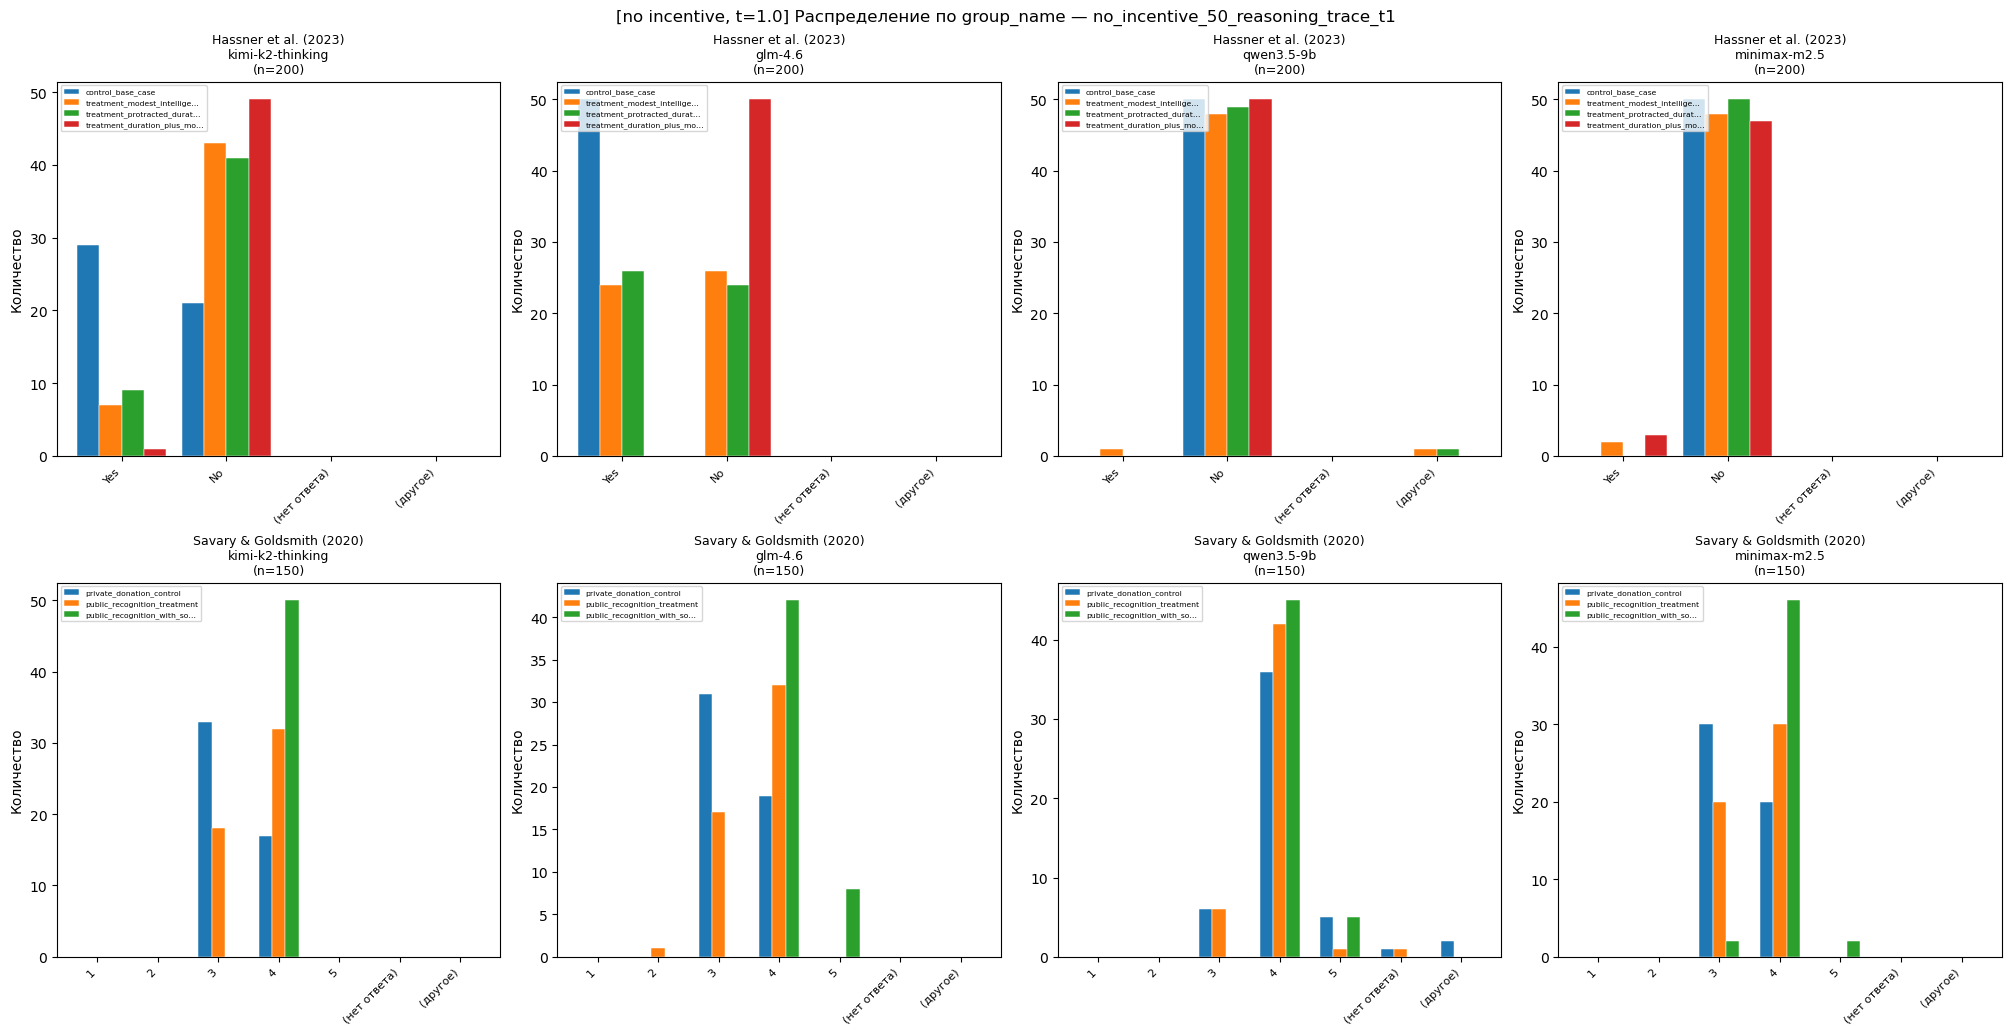

In [ ]:
# no incentive, t=1.0 — (3) анализ: распределения (файл прогона: responses_final.parquet)
import re
import numpy as np
import matplotlib.pyplot as plt

VIEW_RUN_ID_PLAN50_NO_INC_T1 = "no_incentive_50_reasoning_trace_t1"
_path_plan50_no_inc_t1 = RUNS_DIR / VIEW_RUN_ID_PLAN50_NO_INC_T1 / "responses_final.parquet"
if not _path_plan50_no_inc_t1.is_file():
    raise FileNotFoundError(
        f"Нет {_path_plan50_no_inc_t1} — сначала выполните прогон t=1.0 выше"
    )

_plot_plan50_no_inc_t1 = pd.read_parquet(_path_plan50_no_inc_t1)

EXPERIMENTS_T1 = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE_T1 = {
    EXPERIMENTS_T1[0]: "Hassner et al. (2023)",
    EXPERIMENTS_T1[1]: "Savary & Goldsmith (2020)",
}

GROUP_ORDER_T1: Dict[str, List[str]] = {
    EXPERIMENTS_T1[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS_T1[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}


def _ordered_groups_t1(exp: str, present: List[str]) -> List[str]:
    base = list(GROUP_ORDER_T1.get(exp, []))
    out = [g for g in base if g in present]
    for g in sorted(present):
        if g not in out:
            out.append(g)
    return out


def _group_label_short_t1(name: str) -> str:
    if len(name) <= 28:
        return name
    return name[:26] + "…"


_model_order_plan50_no_inc_t1 = [m for m in models if m in set(_plot_plan50_no_inc_t1["model"])]
for m in _plot_plan50_no_inc_t1["model"].unique():
    if m not in _model_order_plan50_no_inc_t1:
        _model_order_plan50_no_inc_t1.append(m)


def _bucket_answer_t1(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    if "Savary" in experiment_name or "Donate" in experiment_name:
        m = re.search(r"\b([1-5])\b", s)
        if m:
            return m.group(1)
        return "(другое)"
    return "(другое)"


def _cat_order_t1(experiment_name: str) -> List[str]:
    if "Hassner" in experiment_name:
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


_plot_plan50_no_inc_t1 = _plot_plan50_no_inc_t1.copy()
_plot_plan50_no_inc_t1["answer_cat"] = _plot_plan50_no_inc_t1.apply(
    lambda r: _bucket_answer_t1(r["final_answer_text"], r["experiment_name"]), axis=1
)

fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
for i, exp in enumerate(EXPERIMENTS_T1):
    cats = _cat_order_t1(exp)
    x = np.arange(len(cats))
    for j, model in enumerate(_model_order_plan50_no_inc_t1):
        ax = axes[i, j]
        sub = _plot_plan50_no_inc_t1[
            (_plot_plan50_no_inc_t1["experiment_name"] == exp)
            & (_plot_plan50_no_inc_t1["model"] == model)
        ]
        present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
        groups = _ordered_groups_t1(exp, present_groups)
        n_g = len(groups)
        if n_g == 0:
            ax.set_visible(False)
            continue
        width = min(0.85 / n_g, 0.22)
        for gi, gname in enumerate(groups):
            subg = sub[sub["group_name"].astype(str) == gname]
            vc = subg["answer_cat"].value_counts()
            heights = [int(vc.get(c, 0)) for c in cats]
            offset = (gi - (n_g - 1) / 2) * width
            ax.bar(
                x + offset,
                heights,
                width,
                label=_group_label_short_t1(gname),
                color=f"C{gi % 10}",
                edgecolor="white",
                linewidth=0.35,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
        short = model.split("/")[-1]
        ax.set_title(f"{EXP_TITLE_T1[exp]}\n{short}\n(n={len(sub)})", fontsize=9)
        ax.set_ylabel("Количество")
        ax.legend(fontsize=5.5, loc="upper left", frameon=True)

fig.suptitle(
    f"[no incentive, t=1.0] Распределение по group_name — {VIEW_RUN_ID_PLAN50_NO_INC_T1}",
    fontsize=12,
    y=1.02,
)
plt.show()


### План: инсентив C_balanced_realism (50 респондентов)
- **t = 0.01**
- инсентив **C_balanced_realism** из `incentives.json` в system prompt
- **reasoning:** включён, trace собирается (`reasoning.enabled=true`, `exclude=false`)
- два эксперимента из `two_experiments_hassner_savary_goldsmith.json`, **50** респондентов на каждое условие (group)


In [ ]:
# План 50 / C_balanced_realism — (1) сбор датасета: reasoning включён, trace в ответе API (`exclude=false`)
# Нужны: models, SHARP_TEMPLATE_MAP, experiments_for_run, selected_profiles (≥50 профилей при Twin2k), RANDOM_SEED, INCENTIVES_PATH

PLAN50_BAL_RUN_ID = "incentive_C_balanced_realism_50_reasoning_trace_p2"

REASONING_ON_TRACE_COLLECT_BODY_BAL: Dict[str, Any] = {
    "enabled": True,
    "exclude": False,
}

two_experiments_requests_df_plan50_bal = build_requests_dataset(
    models_list=models,
    templates_map=SHARP_TEMPLATE_MAP,
    experiments=experiments_for_run,
    num_respondents=50,
    respondent_profiles=selected_profiles,
    reasoning_extra_body=REASONING_ON_TRACE_COLLECT_BODY_BAL,
    incentive_key="C_balanced_realism",
    base_seed=RANDOM_SEED,
)
print(
    "two_experiments_requests_df_plan50_bal rows:",
    len(two_experiments_requests_df_plan50_bal),
    "| logical jobs:",
    two_experiments_requests_df_plan50_bal["logical_job_id"].nunique(),
)



two_experiments_requests_df_plan50_bal rows: 1400 | logical jobs: 1400


In [ ]:
# План 50 / C_balanced_realism — (2) прогон датасета
from IPython.display import display

sharp_results_plan50_bal = await run_sdb_experiments_async(
    requests_df=two_experiments_requests_df_plan50_bal,
    temperature=0.01,
    run_id=PLAN50_BAL_RUN_ID,
    resume=True,
    max_concurrency=8,
    batch_size=120,
    checkpoint_every=100,
)
display(sharp_results_plan50_bal["responses_df"].head())
display(sharp_results_plan50_bal["usage_summary_df"].head())



Всего логических задач:   0%|          | 0/1400 [00:00<?, ?job/s]

moonshotai/kimi-k2-thinking:   0%|          | 0/350 [00:00<?, ?job/s]

z-ai/glm-4.6:   0%|          | 0/350 [00:00<?, ?job/s]

qwen/qwen3.5-9b:   0%|          | 0/350 [00:00<?, ?job/s]

minimax/minimax-m2.5:   0%|          | 0/350 [00:00<?, ?job/s]

Run ID: incentive_C_balanced_realism_50_reasoning_trace_p2
Completed rows: 1400 / 1400
Missing usage share: 0.1479
Total tokens used: 1963468
Top errors:
error_message
Expecting value: line 241 column 1 (char 1320)    1
Expecting value: line 813 column 1 (char 4466)    1
Name: count, dtype: int64


,job_id,seed,model,template_name,template_type,experiment_name,group_name,respondent_id,profile_id,profile_pid,...,usage_missing,retry_attempts_stage1,retry_attempts_stage2,stage1_reasoning_text,stage1_reasoning_details_json,stage1_reasoning_trace,stage2_reasoning_text,stage2_reasoning_details_json,stage2_reasoning_trace,reasoning_trace_combined
0,1,43,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,1,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. The vignet...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. The vignett...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. The vignett...
1,2,44,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,2,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. The vignet...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. The vignett...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. The vignett...
2,3,45,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,3,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. The scenar...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. The scenari...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. The scenari...
3,4,46,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,4,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. The vignet...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. The vignett...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. The vignett...
4,5,47,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,5,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey respondent in a vignette-based study. The vignet...,"[{""type"": ""reasoning.text"", ""text"": "" The user wants me to act as a plausible survey respondent ...",The user wants me to act as a plausible survey respondent in a vignette-based study. The vignett...,,None,,The user wants me to act as a plausible survey respondent in a vignette-based study. The vignett...


,model,template_name,experiment_name,group_name,respondents,ok_rows,error_rows,total_tokens_sum,stage1_tokens_sum,stage2_tokens_sum,usage_missing_rows,avg_tokens_per_row
0,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,control_base_case,50,50,0,38674.0,38674.0,0,0,773.48
1,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_duration_plus_modest_intelligence,50,50,0,32000.0,32000.0,0,0,640.00
2,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_modest_intelligence,50,50,0,30623.0,30623.0,0,0,612.46
3,minimax/minimax-m2.5,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture,treatment_protracted_duration,50,50,0,30381.0,30381.0,0,0,607.62
4,minimax/minimax-m2.5,one_stage_attitude_expression,Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate,private_donation_control,50,50,0,28083.0,28083.0,0,0,561.66


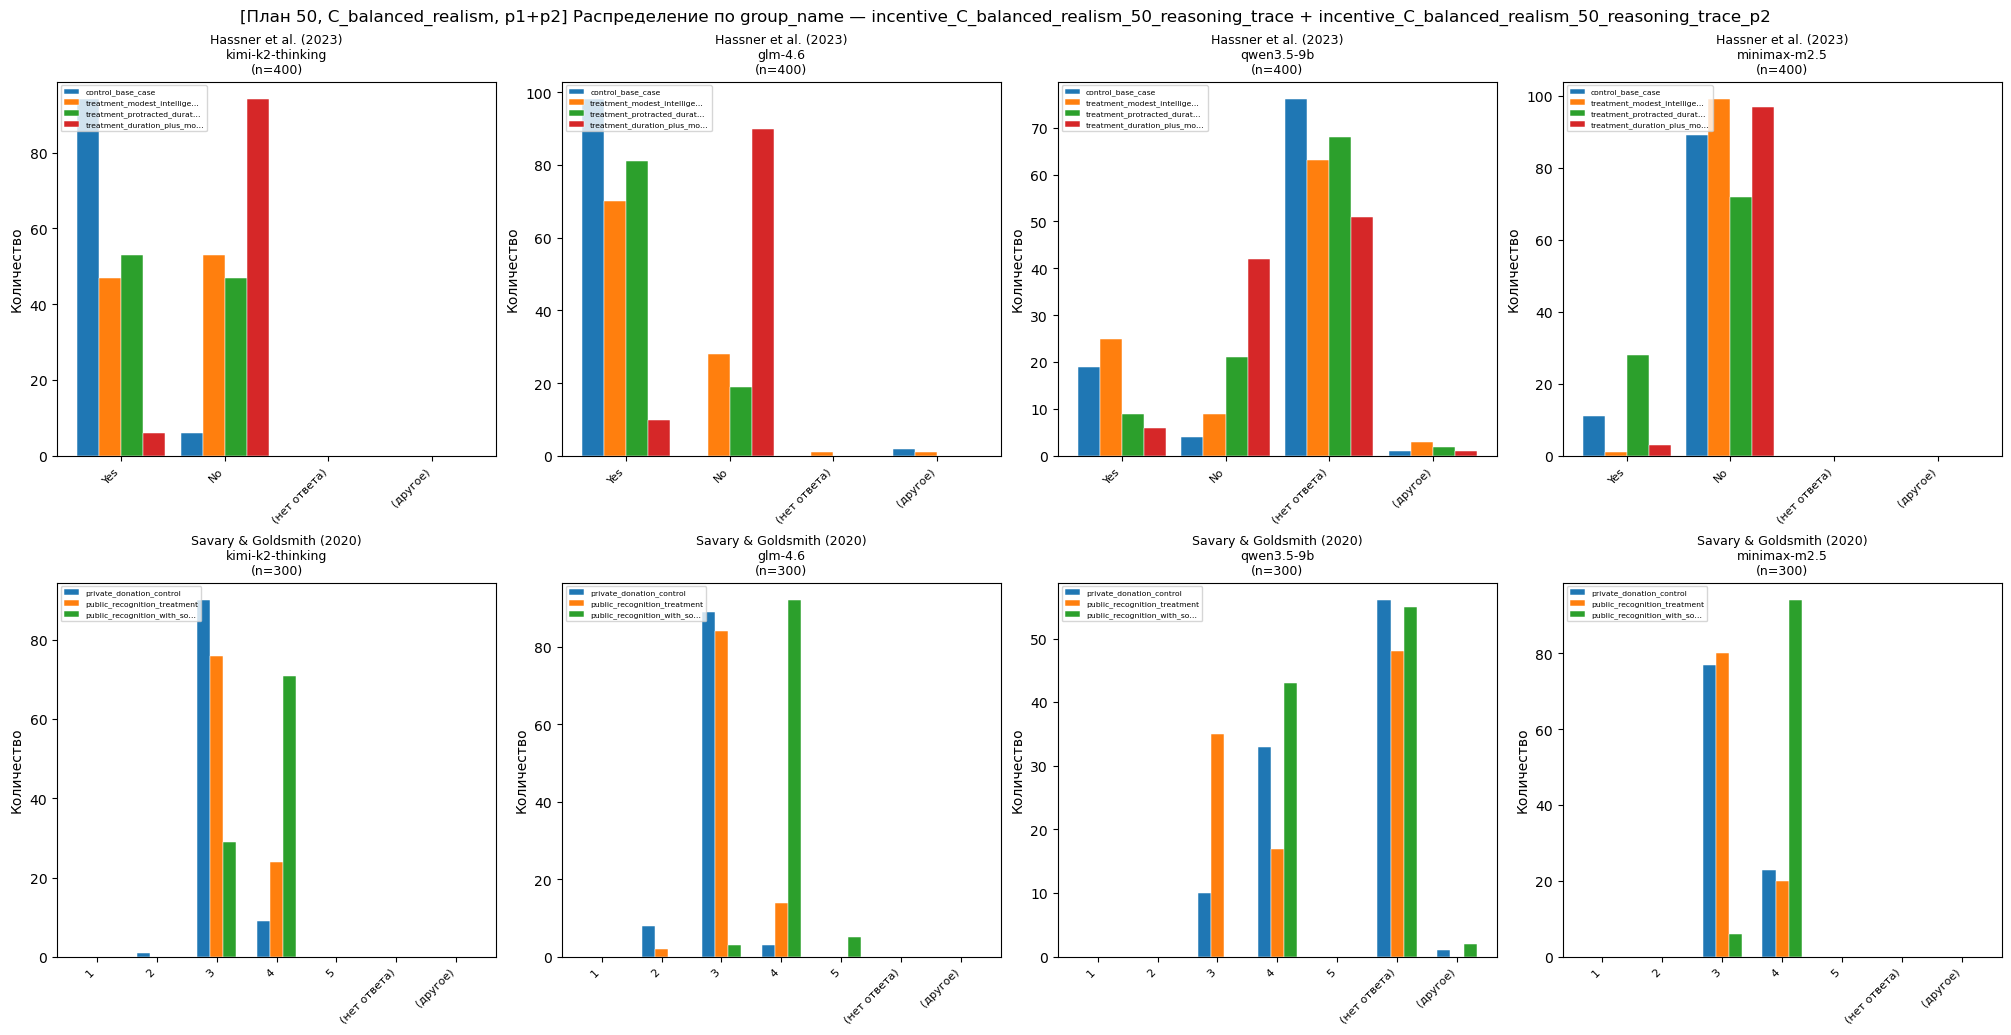

In [ ]:
# План 50 / C_balanced_realism — (3) анализ: распределения
import re
import numpy as np
import matplotlib.pyplot as plt

VIEW_RUN_ID_PLAN50_BAL = "incentive_C_balanced_realism_50_reasoning_trace"
RUN_ID_PLAN50_BAL_P2 = "incentive_C_balanced_realism_50_reasoning_trace_p2"

_path_plan50_bal_p1 = (
    RUNS_DIR
    / VIEW_RUN_ID_PLAN50_BAL
    / "responses_final_incentive_C_balanced_realism_50_reasoning_trace.parquet"
)
_path_plan50_bal_p2 = (
    RUNS_DIR
    / RUN_ID_PLAN50_BAL_P2
    / "responses_final_incentive_C_balanced_realism_50_reasoning_trace_p2.parquet"
)
for _p in (_path_plan50_bal_p1, _path_plan50_bal_p2):
    if not _p.is_file():
        raise FileNotFoundError(
            f"Нет {_p} — нужны оба parquet (p1 и p2) для склейки C_balanced_realism"
        )

_plot_plan50_bal = pd.concat(
    [
        pd.read_parquet(_path_plan50_bal_p1),
        pd.read_parquet(_path_plan50_bal_p2),
    ],
    ignore_index=True,
)
# См. no-incentive: job_id в p1 и p2 пересекаются — без дедупа по job_id после concat.

EXPERIMENTS_B = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE_B = {
    EXPERIMENTS_B[0]: "Hassner et al. (2023)",
    EXPERIMENTS_B[1]: "Savary & Goldsmith (2020)",
}

GROUP_ORDER_B: Dict[str, List[str]] = {
    EXPERIMENTS_B[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS_B[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}


def _ordered_groups_b(exp: str, present: List[str]) -> List[str]:
    base = list(GROUP_ORDER_B.get(exp, []))
    out = [g for g in base if g in present]
    for g in sorted(present):
        if g not in out:
            out.append(g)
    return out


def _group_label_short_b(name: str) -> str:
    if len(name) <= 28:
        return name
    return name[:26] + "…"


def _bucket_b(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    if "Savary" in experiment_name or "Donate" in experiment_name:
        m = re.search(r"\b([1-5])\b", s)
        if m:
            return m.group(1)
        return "(другое)"
    return "(другое)"


def _cat_order_b(experiment_name: str) -> List[str]:
    if "Hassner" in experiment_name:
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


_plot_plan50_bal = _plot_plan50_bal.copy()
_plot_plan50_bal["answer_cat"] = _plot_plan50_bal.apply(
    lambda r: _bucket_b(r["final_answer_text"], r["experiment_name"]), axis=1
)

_model_order_plan50_bal = [m for m in models if m in set(_plot_plan50_bal["model"])]
for m in _plot_plan50_bal["model"].unique():
    if m not in _model_order_plan50_bal:
        _model_order_plan50_bal.append(m)

fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
for i, exp in enumerate(EXPERIMENTS_B):
    cats = _cat_order_b(exp)
    x = np.arange(len(cats))
    for j, model in enumerate(_model_order_plan50_bal):
        ax = axes[i, j]
        sub = _plot_plan50_bal[(_plot_plan50_bal["experiment_name"] == exp) & (_plot_plan50_bal["model"] == model)]
        present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
        groups = _ordered_groups_b(exp, present_groups)
        n_g = len(groups)
        if n_g == 0:
            ax.set_visible(False)
            continue
        width = min(0.85 / n_g, 0.22)
        for gi, gname in enumerate(groups):
            subg = sub[sub["group_name"].astype(str) == gname]
            vc = subg["answer_cat"].value_counts()
            heights = [int(vc.get(c, 0)) for c in cats]
            offset = (gi - (n_g - 1) / 2) * width
            ax.bar(
                x + offset,
                heights,
                width,
                label=_group_label_short_b(gname),
                color=f"C{gi % 10}",
                edgecolor="white",
                linewidth=0.35,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
        short = model.split("/")[-1]
        ax.set_title(f"{EXP_TITLE_B[exp]}\n{short}\n(n={len(sub)})", fontsize=9)
        ax.set_ylabel("Количество")
        ax.legend(fontsize=5.5, loc="upper left", frameon=True)

fig.suptitle(
    f"[План 50, C_balanced_realism, p1+p2] Распределение по group_name — {VIEW_RUN_ID_PLAN50_BAL} + {RUN_ID_PLAN50_BAL_P2}",
    fontsize=12,
    y=1.02,
)
plt.show()



### План: инсентив X_measurement_neutrality (50 респондентов)
- **t = 0.01**
- инсентив **X_measurement_neutrality** из `incentives.json` в system prompt
- **reasoning:** включён, trace собирается (`reasoning.enabled=true`, `exclude=false`)
- два эксперимента из `two_experiments_hassner_savary_goldsmith.json`, **50** респондентов на каждое условие (group)


In [ ]:
# План 50 / X_measurement_neutrality — (1) сбор датасета: reasoning включён, trace в ответе API (`exclude=false`)
# Нужны: models, SHARP_TEMPLATE_MAP, experiments_for_run, selected_profiles (≥50 профилей при Twin2k), RANDOM_SEED, INCENTIVES_PATH

PLAN50_XMN_RUN_ID = "incentive_X_measurement_neutrality_50_reasoning_trace"

REASONING_ON_TRACE_COLLECT_BODY_XMN: Dict[str, Any] = {
    "enabled": True,
    "exclude": False,
}

two_experiments_requests_df_plan50_xmn = build_requests_dataset(
    models_list=models,
    templates_map=SHARP_TEMPLATE_MAP,
    experiments=experiments_for_run,
    num_respondents=50,
    respondent_profiles=selected_profiles,
    reasoning_extra_body=REASONING_ON_TRACE_COLLECT_BODY_XMN,
    incentive_key="X_measurement_neutrality",
    base_seed=RANDOM_SEED,
)
print(
    "two_experiments_requests_df_plan50_xmn rows:",
    len(two_experiments_requests_df_plan50_xmn),
    "| logical jobs:",
    two_experiments_requests_df_plan50_xmn["logical_job_id"].nunique(),
)




In [ ]:
# План 50 / X_measurement_neutrality — (2) прогон датасета
from IPython.display import display

sharp_results_plan50_xmn = await run_sdb_experiments_async(
    requests_df=two_experiments_requests_df_plan50_xmn,
    temperature=0.01,
    run_id=PLAN50_XMN_RUN_ID,
    resume=True,
    max_concurrency=8,
    batch_size=120,
    checkpoint_every=100,
)
display(sharp_results_plan50_xmn["responses_df"].head())
display(sharp_results_plan50_xmn["usage_summary_df"].head())




In [ ]:
# План 50 / X_measurement_neutrality — (3) анализ: распределения
import re
import numpy as np
import matplotlib.pyplot as plt

VIEW_RUN_ID_PLAN50_XMN = "incentive_X_measurement_neutrality_50_reasoning_trace"
_path_plan50_xmn = RUNS_DIR / VIEW_RUN_ID_PLAN50_XMN / "responses_final.parquet"
if not _path_plan50_xmn.is_file():
    raise FileNotFoundError(f"Нет {_path_plan50_xmn} — сначала прогон плана 50 (X_measurement_neutrality) выше")

_plot_plan50_xmn = pd.read_parquet(_path_plan50_xmn)

EXPERIMENTS_B = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE_B = {
    EXPERIMENTS_B[0]: "Hassner et al. (2023)",
    EXPERIMENTS_B[1]: "Savary & Goldsmith (2020)",
}

GROUP_ORDER_B: Dict[str, List[str]] = {
    EXPERIMENTS_B[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS_B[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}


def _ordered_groups_b(exp: str, present: List[str]) -> List[str]:
    base = list(GROUP_ORDER_B.get(exp, []))
    out = [g for g in base if g in present]
    for g in sorted(present):
        if g not in out:
            out.append(g)
    return out


def _group_label_short_b(name: str) -> str:
    if len(name) <= 28:
        return name
    return name[:26] + "…"


def _bucket_b(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    if "Savary" in experiment_name or "Donate" in experiment_name:
        m = re.search(r"\b([1-5])\b", s)
        if m:
            return m.group(1)
        return "(другое)"
    return "(другое)"


def _cat_order_b(experiment_name: str) -> List[str]:
    if "Hassner" in experiment_name:
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


_plot_plan50_xmn = _plot_plan50_xmn.copy()
_plot_plan50_xmn["answer_cat"] = _plot_plan50_xmn.apply(
    lambda r: _bucket_b(r["final_answer_text"], r["experiment_name"]), axis=1
)

_model_order_plan50_xmn = [m for m in models if m in set(_plot_plan50_xmn["model"])]
for m in _plot_plan50_xmn["model"].unique():
    if m not in _model_order_plan50_xmn:
        _model_order_plan50_xmn.append(m)

fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
for i, exp in enumerate(EXPERIMENTS_B):
    cats = _cat_order_b(exp)
    x = np.arange(len(cats))
    for j, model in enumerate(_model_order_plan50_xmn):
        ax = axes[i, j]
        sub = _plot_plan50_xmn[(_plot_plan50_xmn["experiment_name"] == exp) & (_plot_plan50_xmn["model"] == model)]
        present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
        groups = _ordered_groups_b(exp, present_groups)
        n_g = len(groups)
        if n_g == 0:
            ax.set_visible(False)
            continue
        width = min(0.85 / n_g, 0.22)
        for gi, gname in enumerate(groups):
            subg = sub[sub["group_name"].astype(str) == gname]
            vc = subg["answer_cat"].value_counts()
            heights = [int(vc.get(c, 0)) for c in cats]
            offset = (gi - (n_g - 1) / 2) * width
            ax.bar(
                x + offset,
                heights,
                width,
                label=_group_label_short_b(gname),
                color=f"C{gi % 10}",
                edgecolor="white",
                linewidth=0.35,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
        short = model.split("/")[-1]
        ax.set_title(f"{EXP_TITLE_B[exp]}\n{short}\n(n={len(sub)})", fontsize=9)
        ax.set_ylabel("Количество")
        ax.legend(fontsize=5.5, loc="upper left", frameon=True)

fig.suptitle(
    f"[План 50, X_measurement_neutrality] Распределение по group_name — {VIEW_RUN_ID_PLAN50_XMN}",
    fontsize=12,
    y=1.02,
)
plt.show()




### План: инсентив A_original_core_realism (50 респондентов)
- **t = 0.01**
- инсентив **A_original_core_realism** из `incentives.json` в system prompt
- **reasoning:** включён, trace собирается (`reasoning.enabled=true`, `exclude=false`)
- два эксперимента из `two_experiments_hassner_savary_goldsmith.json`, **50** респондентов на каждое условие (group)



In [ ]:
# План 50 / A_original_core_realism — (1) сбор датасета: reasoning включён, trace в ответе API (`exclude=false`)
# Нужны: models, SHARP_TEMPLATE_MAP, experiments_for_run, selected_profiles (≥50 профилей при Twin2k), RANDOM_SEED, INCENTIVES_PATH

PLAN50_ACR_RUN_ID = "incentive_A_original_core_realism_50_reasoning_trace"

REASONING_ON_TRACE_COLLECT_BODY_ACR: Dict[str, Any] = {
    "enabled": True,
    "exclude": False,
}

two_experiments_requests_df_plan50_acr = build_requests_dataset(
    models_list=models,
    templates_map=SHARP_TEMPLATE_MAP,
    experiments=experiments_for_run,
    num_respondents=50,
    respondent_profiles=selected_profiles,
    reasoning_extra_body=REASONING_ON_TRACE_COLLECT_BODY_ACR,
    incentive_key="A_original_core_realism",
    base_seed=RANDOM_SEED,
)
print(
    "two_experiments_requests_df_plan50_acr rows:",
    len(two_experiments_requests_df_plan50_acr),
    "| logical jobs:",
    two_experiments_requests_df_plan50_acr["logical_job_id"].nunique(),
)





In [ ]:
# План 50 / A_original_core_realism — (2) прогон датасета
from IPython.display import display

sharp_results_plan50_acr = await run_sdb_experiments_async(
    requests_df=two_experiments_requests_df_plan50_acr,
    temperature=0.01,
    run_id=PLAN50_ACR_RUN_ID,
    resume=True,
    max_concurrency=8,
    batch_size=120,
    checkpoint_every=100,
)
display(sharp_results_plan50_acr["responses_df"].head())
display(sharp_results_plan50_acr["usage_summary_df"].head())





In [ ]:
# План 50 / A_original_core_realism — (3) анализ: распределения
import re
import numpy as np
import matplotlib.pyplot as plt

VIEW_RUN_ID_PLAN50_ACR = "incentive_A_original_core_realism_50_reasoning_trace"
_path_plan50_acr = RUNS_DIR / VIEW_RUN_ID_PLAN50_ACR / "responses_final.parquet"
if not _path_plan50_acr.is_file():
    raise FileNotFoundError(f"Нет {_path_plan50_acr} — сначала прогон плана 50 (A_original_core_realism) выше")

_plot_plan50_acr = pd.read_parquet(_path_plan50_acr)

EXPERIMENTS_B = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE_B = {
    EXPERIMENTS_B[0]: "Hassner et al. (2023)",
    EXPERIMENTS_B[1]: "Savary & Goldsmith (2020)",
}

GROUP_ORDER_B: Dict[str, List[str]] = {
    EXPERIMENTS_B[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS_B[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}


def _ordered_groups_b(exp: str, present: List[str]) -> List[str]:
    base = list(GROUP_ORDER_B.get(exp, []))
    out = [g for g in base if g in present]
    for g in sorted(present):
        if g not in out:
            out.append(g)
    return out


def _group_label_short_b(name: str) -> str:
    if len(name) <= 28:
        return name
    return name[:26] + "…"


def _bucket_b(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    if "Savary" in experiment_name or "Donate" in experiment_name:
        m = re.search(r"\b([1-5])\b", s)
        if m:
            return m.group(1)
        return "(другое)"
    return "(другое)"


def _cat_order_b(experiment_name: str) -> List[str]:
    if "Hassner" in experiment_name:
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


_plot_plan50_acr = _plot_plan50_acr.copy()
_plot_plan50_acr["answer_cat"] = _plot_plan50_acr.apply(
    lambda r: _bucket_b(r["final_answer_text"], r["experiment_name"]), axis=1
)

_model_order_plan50_acr = [m for m in models if m in set(_plot_plan50_acr["model"])]
for m in _plot_plan50_acr["model"].unique():
    if m not in _model_order_plan50_acr:
        _model_order_plan50_acr.append(m)

fig, axes = plt.subplots(2, 4, figsize=(20, 10), constrained_layout=True)
for i, exp in enumerate(EXPERIMENTS_B):
    cats = _cat_order_b(exp)
    x = np.arange(len(cats))
    for j, model in enumerate(_model_order_plan50_acr):
        ax = axes[i, j]
        sub = _plot_plan50_acr[(_plot_plan50_acr["experiment_name"] == exp) & (_plot_plan50_acr["model"] == model)]
        present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
        groups = _ordered_groups_b(exp, present_groups)
        n_g = len(groups)
        if n_g == 0:
            ax.set_visible(False)
            continue
        width = min(0.85 / n_g, 0.22)
        for gi, gname in enumerate(groups):
            subg = sub[sub["group_name"].astype(str) == gname]
            vc = subg["answer_cat"].value_counts()
            heights = [int(vc.get(c, 0)) for c in cats]
            offset = (gi - (n_g - 1) / 2) * width
            ax.bar(
                x + offset,
                heights,
                width,
                label=_group_label_short_b(gname),
                color=f"C{gi % 10}",
                edgecolor="white",
                linewidth=0.35,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
        short = model.split("/")[-1]
        ax.set_title(f"{EXP_TITLE_B[exp]}\n{short}\n(n={len(sub)})", fontsize=9)
        ax.set_ylabel("Количество")
        ax.legend(fontsize=5.5, loc="upper left", frameon=True)

fig.suptitle(
    f"[План 50, A_original_core_realism] Распределение по group_name — {VIEW_RUN_ID_PLAN50_ACR}",
    fontsize=12,
    y=1.02,
)
plt.show()





### План: стимулы H–K (science/company stakes), только GLM + Kimi (50 респондентов, t=0.01)

- **Модели:** `moonshotai/kimi-k2-thinking`, `z-ai/glm-4.6` (только эти две)
- **Эксперименты:** два из `attitude/two_experiments_hassner_savary_goldsmith.json` — в ячейке (1): `experiments_for_run = load_sdb_experiments(EXPERIMENTS_PATH)`
- **Шаблон промптов:** только **`one_stage_attitude_expression`** из `attitude/prompts_attitude.json` — тот же источник и ключ, что и `SHARP_TEMPLATE_MAP` в блоке «(а) Таблица запросов» (одна запись в `templates_map`)
- **Профили респондентов:** не задаём — **`respondent_profiles=None`** (пустой persona в `build_requests_dataset`, `profile_id`/`profile_pid` — пусто; при `INCLUDE_PROFILE_IN_PROMPT` по умолчанию демография в system не добавляется)
- **Респонденты:** **50** на каждое условие (group), то есть 50 виртуальных `respondent_id` без Twin2k
- **Температура:** **0.01**
- **Reasoning:** включён, trace собирается (`reasoning.enabled=true`, `exclude=false`), как в плане 50 с инсентивом
- **Стимулы** (отдельный прогон и подпапка `attitude/runs/<run_id>/` на каждый ключ): **`H_science_personal_gain`**, **`I_science_public_good`**, **`J_company_personal_gain`**, **`K_company_public_good`** в `incentives.json`

Формат `requests_df` / итогового parquet — тот же pipeline, что у других прогонов `build_requests_dataset` → `run_sdb_experiments_async`; отличие только в пустых полях профиля и в том, что в `templates_map` только один шаблон (как в остальных sharp-прогонах). В каждой подпапке: `responses_final.parquet`.

In [ ]:
# Стимулы H–K (stakes) — (1) сбор датасетов: один requests_df на каждый incentive_key
#
# Шаблоны: только one_stage_attitude_expression из prompts_attitude.json (идентично по смыслу SHARP_TEMPLATE_MAP).
# Эксперименты: two_experiments_hassner_savary_goldsmith.json через EXPERIMENTS_PATH.
# Профили Twin2k не используются: respondent_profiles=None (см. docstring build_requests_dataset).
# Нужны: ячейка helpers (build_requests_dataset, load_*, PROMPT_TEMPLATES_PATH, INCENTIVES_PATH), RANDOM_SEED.

experiments_for_run = load_sdb_experiments(EXPERIMENTS_PATH)
assert len(experiments_for_run) == 2, (
    "Ожидаются 2 эксперимента в two_experiments_hassner_savary_goldsmith.json"
)

_prompts_stakes = load_prompt_templates(PROMPT_TEMPLATES_PATH)
STAKES_TEMPLATE_MAP: Dict[str, Dict[str, str]] = {
    "one_stage_attitude_expression": _prompts_stakes["one_stage_attitude_expression"],
}

MODELS_GLM_KIMI = [
    "moonshotai/kimi-k2-thinking",
    "z-ai/glm-4.6",
]

STAKES_INCENTIVE_KEYS = [
    "H_science_personal_gain",
    "I_science_public_good",
    "J_company_personal_gain",
    "K_company_public_good",
]

REASONING_ON_TRACE_COLLECT_BODY_STAKES: Dict[str, Any] = {
    "enabled": True,
    "exclude": False,
}

STAKES_TEMPERATURE = 0.01


def _stakes_run_id(key: str) -> str:
    return f"incentive_{key}_50_reasoning_trace_glm_kimi_t001"


STAKES_RUN_ID_BY_KEY = {_k: _stakes_run_id(_k) for _k in STAKES_INCENTIVE_KEYS}

stakes_requests_df_by_key: Dict[str, pd.DataFrame] = {}
for _key in STAKES_INCENTIVE_KEYS:
    stakes_requests_df_by_key[_key] = build_requests_dataset(
        models_list=MODELS_GLM_KIMI,
        templates_map=STAKES_TEMPLATE_MAP,
        experiments=experiments_for_run,
        num_respondents=50,
        respondent_profiles=None,
        reasoning_extra_body=REASONING_ON_TRACE_COLLECT_BODY_STAKES,
        incentive_key=_key,
        base_seed=RANDOM_SEED,
    )
    print(
        _key,
        "rows:",
        len(stakes_requests_df_by_key[_key]),
        "| logical jobs:",
        stakes_requests_df_by_key[_key]["logical_job_id"].nunique(),
    )


H_science_personal_gain rows: 700 | logical jobs: 700
I_science_public_good rows: 700 | logical jobs: 700
J_company_personal_gain rows: 700 | logical jobs: 700
K_company_public_good rows: 700 | logical jobs: 700


In [ ]:
# Стимулы H–K — (2) прогон: отдельный run_id (папка в attitude/runs/) на каждый стимул

from IPython.display import display

stakes_results_by_key: Dict[str, Any] = {}

for _key in STAKES_INCENTIVE_KEYS:
    _rid = STAKES_RUN_ID_BY_KEY[_key]
    print(f"=== Running {_key} → run_id={_rid} ===")
    stakes_results_by_key[_key] = await run_sdb_experiments_async(
        requests_df=stakes_requests_df_by_key[_key],
        temperature=STAKES_TEMPERATURE,
        run_id=_rid,
        resume=True,
        max_concurrency=8,
        batch_size=120,
        checkpoint_every=100,
    )

print("Done. Пример — последний ключ:")
_last = STAKES_INCENTIVE_KEYS[-1]
display(stakes_results_by_key[_last]["responses_df"].head())
display(stakes_results_by_key[_last]["usage_summary_df"].head())


=== Running H_science_personal_gain → run_id=incentive_H_science_personal_gain_50_reasoning_trace_glm_kimi_t001 ===


Всего логических задач:   0%|          | 0/700 [00:00<?, ?job/s]

moonshotai/kimi-k2-thinking:   0%|          | 0/350 [00:00<?, ?job/s]

z-ai/glm-4.6:   0%|          | 0/350 [00:00<?, ?job/s]

Run ID: incentive_H_science_personal_gain_50_reasoning_trace_glm_kimi_t001
Completed rows: 700 / 700
Missing usage share: 0.5000
Total tokens used: 526256
Top errors:
error_message
Error code: 404 - {'error': {'message': 'No endpoints found for moonshotai/kimi-k2-thinking.', 'code': 404}, 'user_id': 'user_37ogpsgTteNTWEMKawAWMHO5UlK'}    350
Name: count, dtype: int64
=== Running I_science_public_good → run_id=incentive_I_science_public_good_50_reasoning_trace_glm_kimi_t001 ===


...

moonshotai/kimi-k2-thinking:   0%|          | 0/350 [00:00<?, ?job/s]

z-ai/glm-4.6:   0%|          | 0/350 [00:00<?, ?job/s]

Run ID: incentive_K_company_public_good_50_reasoning_trace_glm_kimi_t001
Completed rows: 700 / 700
Missing usage share: 0.5000
Total tokens used: 525299
Top errors:
error_message
Error code: 404 - {'error': {'message': 'No endpoints found for moonshotai/kimi-k2-thinking.', 'code': 404}, 'user_id': 'user_37ogpsgTteNTWEMKawAWMHO5UlK'}    350
Name: count, dtype: int64
Done. Пример — последний ключ:


,job_id,seed,model,template_name,template_type,experiment_name,group_name,respondent_id,profile_id,profile_pid,...,usage_missing,retry_attempts_stage1,retry_attempts_stage2,stage1_reasoning_text,stage1_reasoning_details_json,stage1_reasoning_trace,stage2_reasoning_text,stage2_reasoning_details_json,stage2_reasoning_trace,reasoning_trace_combined
0,1,43,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,1,<NA>,None,...,True,5,None,,None,,,None,,
1,2,44,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,2,<NA>,None,...,True,5,None,,None,,,None,,
2,3,45,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,3,<NA>,None,...,True,5,None,,None,,,None,,
3,4,46,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,4,<NA>,None,...,True,5,None,,None,,,None,,
4,5,47,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,5,<NA>,None,...,True,5,None,,None,,,None,,


,model,template_name,experiment_name,group_name,respondents,ok_rows,error_rows,total_tokens_sum,stage1_tokens_sum,stage2_tokens_sum,usage_missing_rows,avg_tokens_per_row
0,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,50,0,50,0.0,0.0,0,50,0.0
1,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,treatment_duration_plus_modest_intelligence,50,0,50,0.0,0.0,0,50,0.0
2,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,treatment_modest_intelligence,50,0,50,0.0,0.0,0,50,0.0
3,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,treatment_protracted_duration,50,0,50,0.0,0.0,0,50,0.0
4,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,private_donation_control,50,0,50,0.0,0.0,0,50,0.0


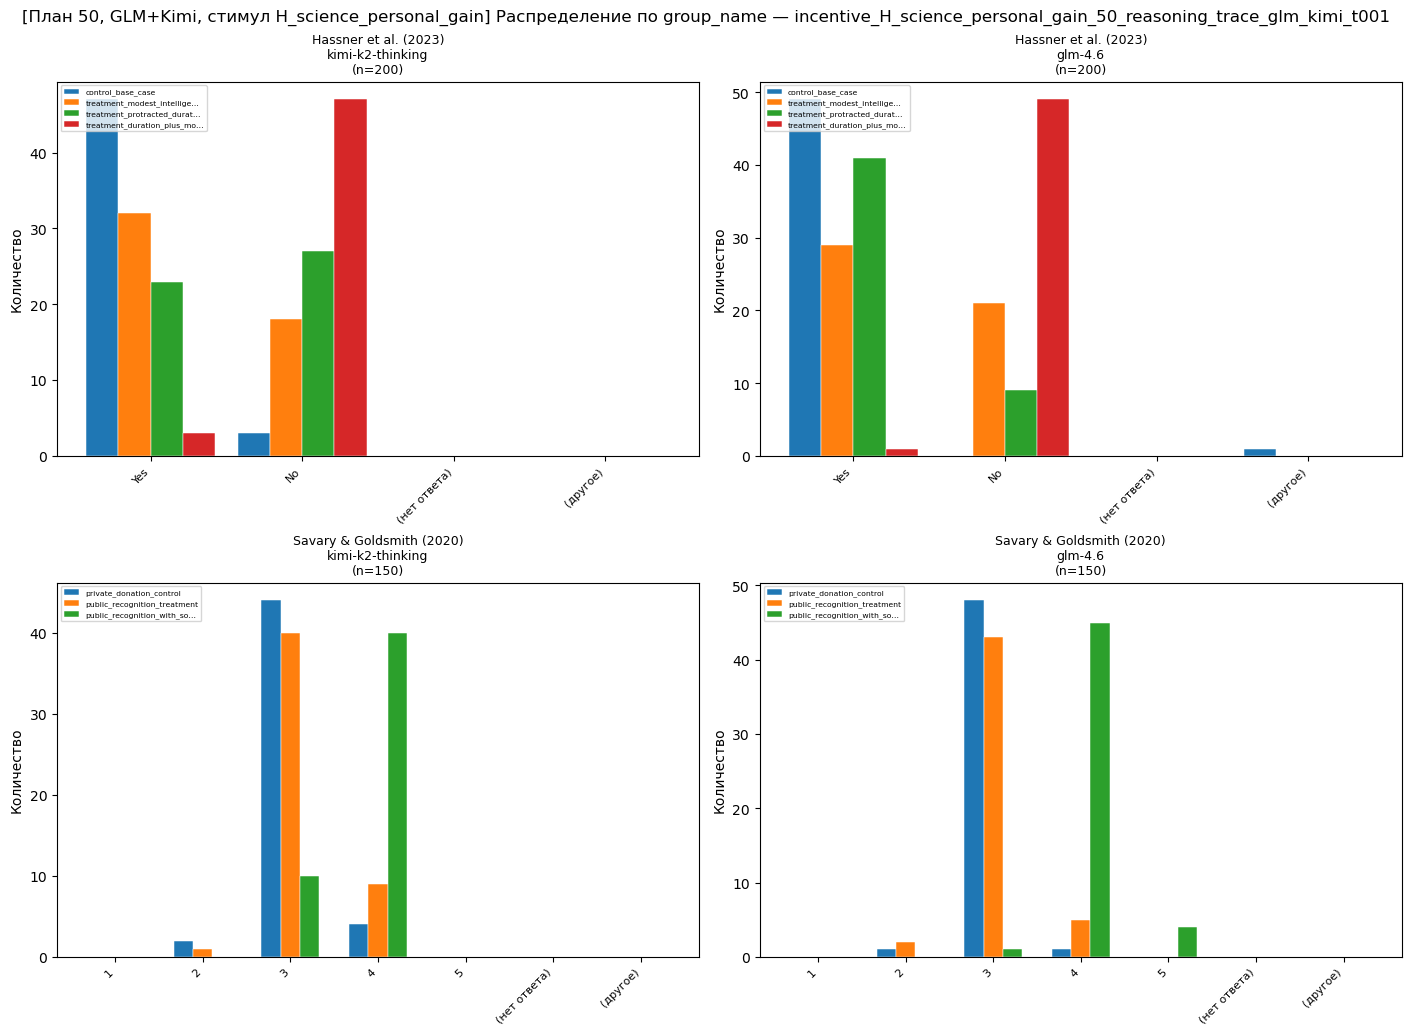

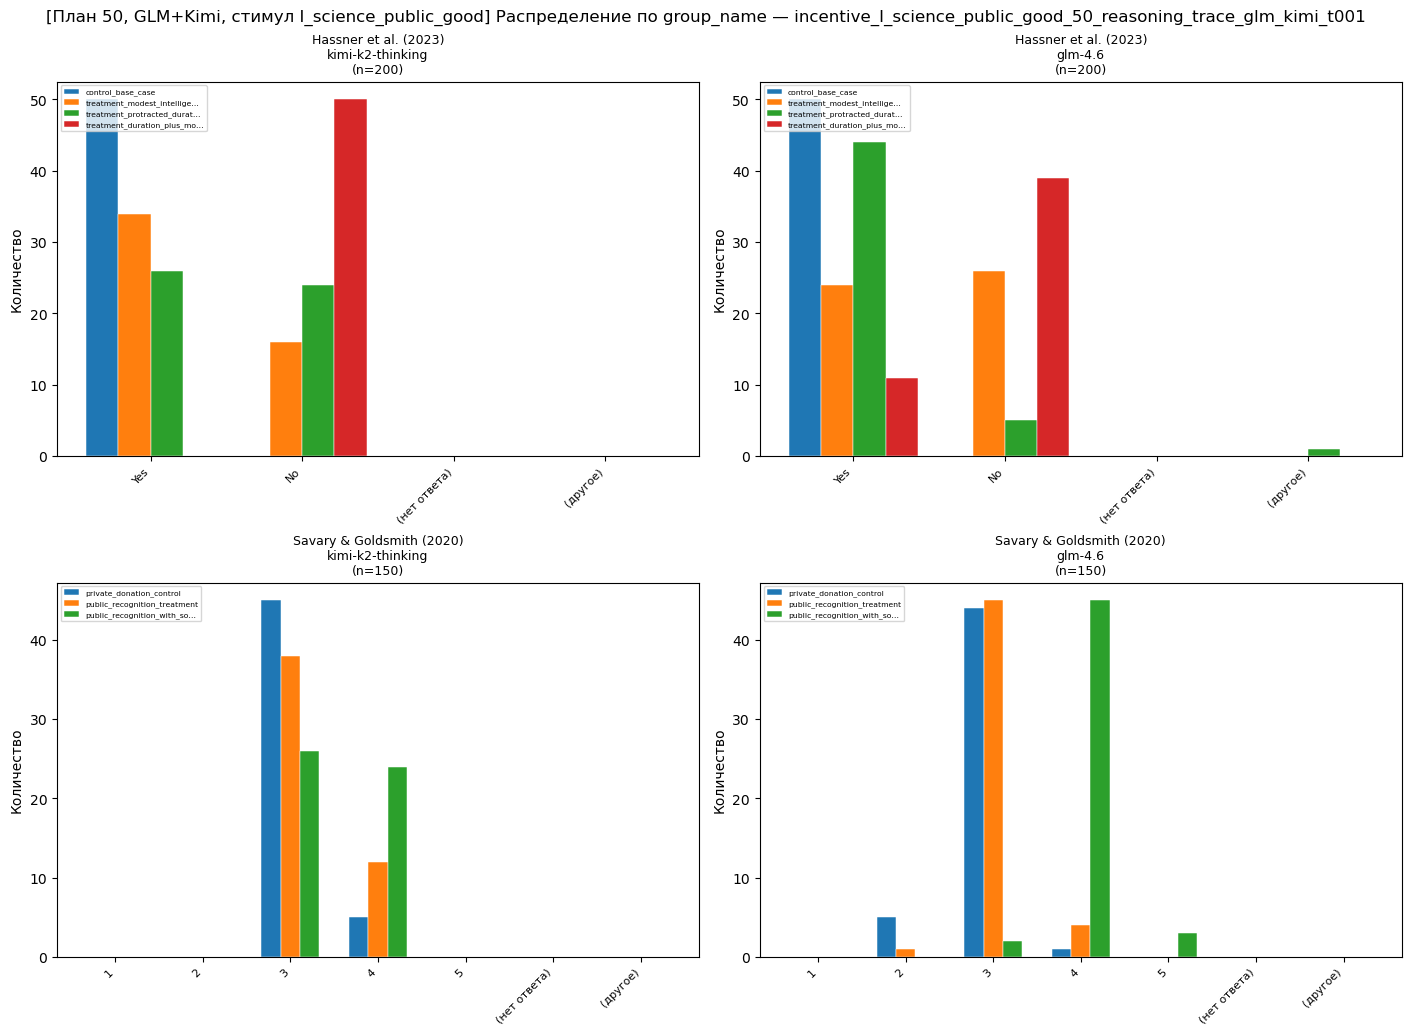

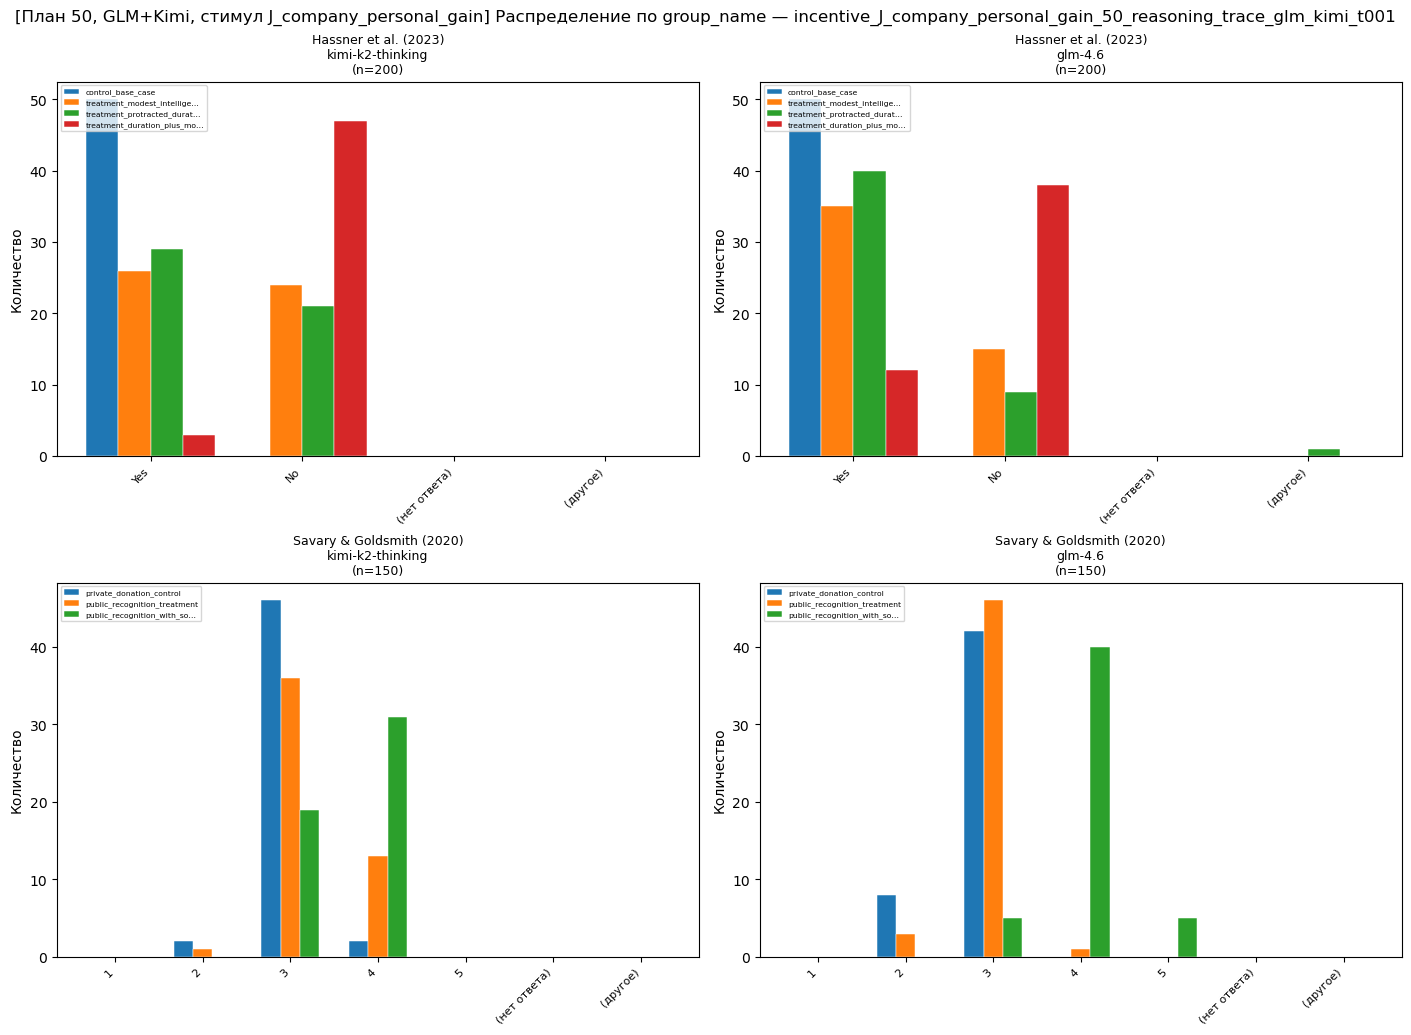

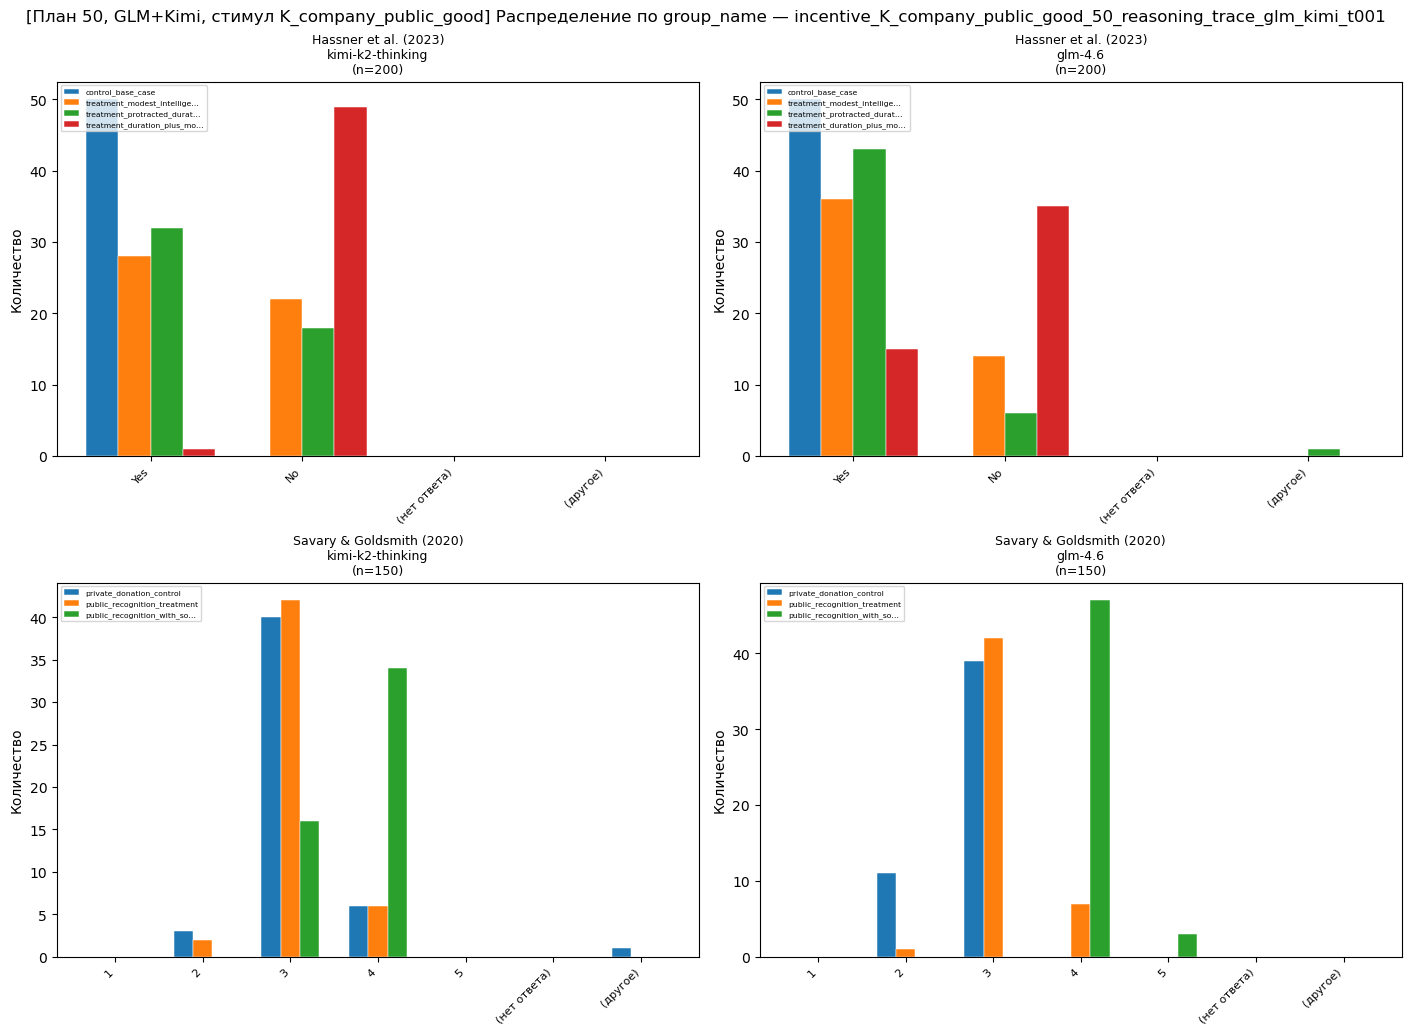

In [ ]:
# Стимулы H–K — (3) анализ: распределения по group_name для каждого из четырёх прогонов

import re
import numpy as np
import matplotlib.pyplot as plt

EXPERIMENTS_B = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE_B = {
    EXPERIMENTS_B[0]: "Hassner et al. (2023)",
    EXPERIMENTS_B[1]: "Savary & Goldsmith (2020)",
}

GROUP_ORDER_B: Dict[str, List[str]] = {
    EXPERIMENTS_B[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS_B[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}


def _ordered_groups_bs(exp: str, present: List[str]) -> List[str]:
    base = list(GROUP_ORDER_B.get(exp, []))
    out = [g for g in base if g in present]
    for g in sorted(present):
        if g not in out:
            out.append(g)
    return out


def _group_label_short_bs(name: str) -> str:
    if len(name) <= 28:
        return name
    return name[:26] + "…"


def _bucket_bs(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    if "Savary" in experiment_name or "Donate" in experiment_name:
        m = re.search(r"\b([1-5])\b", s)
        if m:
            return m.group(1)
        return "(другое)"
    return "(другое)"


def _cat_order_bs(experiment_name: str) -> List[str]:
    if "Hassner" in experiment_name:
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


for _key in STAKES_INCENTIVE_KEYS:
    VIEW_RUN_ID_STAKES = STAKES_RUN_ID_BY_KEY[_key]
    _path_stakes = RUNS_DIR / VIEW_RUN_ID_STAKES / "responses_final.parquet"
    if not _path_stakes.is_file():
        raise FileNotFoundError(f"Нет {_path_stakes} — сначала прогон для {_key}")

    _plot_stakes = pd.read_parquet(_path_stakes)
    _plot_stakes = _plot_stakes.copy()
    _plot_stakes["answer_cat"] = _plot_stakes.apply(
        lambda r: _bucket_bs(r["final_answer_text"], r["experiment_name"]), axis=1
    )

    _model_order_bs = [m for m in MODELS_GLM_KIMI if m in set(_plot_stakes["model"])]
    for m in _plot_stakes["model"].unique():
        if m not in _model_order_bs:
            _model_order_bs.append(m)

    fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
    for i, exp in enumerate(EXPERIMENTS_B):
        cats = _cat_order_bs(exp)
        x = np.arange(len(cats))
        for j, model in enumerate(_model_order_bs):
            ax = axes[i, j]
            sub = _plot_stakes[
                (_plot_stakes["experiment_name"] == exp)
                & (_plot_stakes["model"] == model)
            ]
            present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
            groups = _ordered_groups_bs(exp, present_groups)
            n_g = len(groups)
            if n_g == 0:
                ax.set_visible(False)
                continue
            width = min(0.85 / n_g, 0.22)
            for gi, gname in enumerate(groups):
                subg = sub[sub["group_name"].astype(str) == gname]
                vc = subg["answer_cat"].value_counts()
                heights = [int(vc.get(c, 0)) for c in cats]
                offset = (gi - (n_g - 1) / 2) * width
                ax.bar(
                    x + offset,
                    heights,
                    width,
                    label=_group_label_short_bs(gname),
                    color=f"C{gi % 10}",
                    edgecolor="white",
                    linewidth=0.35,
                )
            ax.set_xticks(x)
            ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
            short = model.split("/")[-1]
            ax.set_title(f"{EXP_TITLE_B[exp]}\n{short}\n(n={len(sub)})", fontsize=9)
            ax.set_ylabel("Количество")
            ax.legend(fontsize=5.5, loc="upper left", frameon=True)

    fig.suptitle(
        f"[План 50, GLM+Kimi, стимул {_key}] Распределение по group_name — {VIEW_RUN_ID_STAKES}",
        fontsize=12,
        y=1.02,
    )
    plt.show()


In [ ]:
# Стимулы H–K — (4) пере-прогон только Kimi и замена Kimi-строк в существующих parquet тех же run_id
#
# Что делает ячейка:
# 1) запускает только модель moonshotai/kimi-k2-thinking для каждого из 4 стимулов H-K,
# 2) сохраняет служебный kimi-only прогон в отдельный run_id,
# 3) перезаписывает Kimi-строки в исходных responses_final.parquet (H-K run_id), оставляя GLM без изменений.

MODEL_KIMI_ONLY = ["moonshotai/kimi-k2-thinking"]

kimi_rerun_results_by_key: Dict[str, Any] = {}
kimi_replace_summary_rows: List[Dict[str, Any]] = []

for _key in STAKES_INCENTIVE_KEYS:
    _base_rid = STAKES_RUN_ID_BY_KEY[_key]
    _kimi_rid = _base_rid + "__kimi_rerun"

    # 1) requests только для Kimi
    _req_kimi = build_requests_dataset(
        models_list=MODEL_KIMI_ONLY,
        templates_map=STAKES_TEMPLATE_MAP,
        experiments=experiments_for_run,
        num_respondents=50,
        respondent_profiles=None,
        reasoning_extra_body=REASONING_ON_TRACE_COLLECT_BODY_STAKES,
        incentive_key=_key,
        base_seed=RANDOM_SEED,
    )

    # 2) kimi-only прогон (без resume, чтобы точно перезапросить)
    print(f"=== Kimi rerun for {_key}: {_kimi_rid} ===")
    _res_kimi = await run_sdb_experiments_async(
        requests_df=_req_kimi,
        temperature=STAKES_TEMPERATURE,
        run_id=_kimi_rid,
        resume=False,
        max_concurrency=8,
        batch_size=120,
        checkpoint_every=100,
    )
    kimi_rerun_results_by_key[_key] = _res_kimi

    _df_kimi = _res_kimi["responses_df"].copy()
    _df_kimi = _df_kimi[_df_kimi["model"] == "moonshotai/kimi-k2-thinking"].copy()

    # 3) заменить Kimi-строки в исходном parquet того же run_id
    _base_path = RUNS_DIR / _base_rid / "responses_final.parquet"
    if not _base_path.is_file():
        raise FileNotFoundError(f"Нет {_base_path}")

    _df_base = pd.read_parquet(_base_path)
    _df_base_wo_kimi = _df_base[_df_base["model"] != "moonshotai/kimi-k2-thinking"].copy()

    # Выравниваем набор колонок с исходным parquet (для безопасной склейки)
    _df_kimi = _df_kimi.reindex(columns=_df_base.columns)

    _df_merged = pd.concat([_df_base_wo_kimi, _df_kimi], ignore_index=True)
    _df_merged = _df_merged.sort_values(["model", "experiment_name", "group_name", "respondent_id"]).reset_index(drop=True)
    _df_merged.to_parquet(_base_path, index=False)

    kimi_replace_summary_rows.append(
        {
            "incentive_key": _key,
            "base_run_id": _base_rid,
            "kimi_rerun_run_id": _kimi_rid,
            "base_rows_before": len(_df_base),
            "base_kimi_rows_before": int((_df_base["model"] == "moonshotai/kimi-k2-thinking").sum()),
            "kimi_rows_new": len(_df_kimi),
            "base_rows_after": len(_df_merged),
            "kimi_ok_after": int(((_df_merged["model"] == "moonshotai/kimi-k2-thinking") & (_df_merged["parse_status"] == "ok")).sum()),
            "kimi_error_after": int(((_df_merged["model"] == "moonshotai/kimi-k2-thinking") & (_df_merged["parse_status"] == "error")).sum()),
            "kimi_answers_after": int(((_df_merged["model"] == "moonshotai/kimi-k2-thinking") & (_df_merged["final_answer_text"].fillna("").astype(str).str.strip().ne(""))).sum()),
            "kimi_trace_after": int(((_df_merged["model"] == "moonshotai/kimi-k2-thinking") & (_df_merged["reasoning_trace_combined"].fillna("").astype(str).str.strip().ne(""))).sum()),
        }
    )

kimi_replace_summary_df = pd.DataFrame(kimi_replace_summary_rows)
display(kimi_replace_summary_df)


=== Kimi rerun for H_science_personal_gain: incentive_H_science_personal_gain_50_reasoning_trace_glm_kimi_t001__kimi_rerun ===


Всего логических задач:   0%|          | 0/350 [00:00<?, ?job/s]

moonshotai/kimi-k2-thinking:   0%|          | 0/350 [00:00<?, ?job/s]

Run ID: incentive_H_science_personal_gain_50_reasoning_trace_glm_kimi_t001__kimi_rerun
Completed rows: 350 / 350
Missing usage share: 0.0000
Total tokens used: 517262
=== Kimi rerun for I_science_public_good: incentive_I_science_public_good_50_reasoning_trace_glm_kimi_t001__kimi_rerun ===


Всего логических задач:   0%|          | 0/350 [00:00<?, ?job/s]

...

Run ID: incentive_J_company_personal_gain_50_reasoning_trace_glm_kimi_t001__kimi_rerun
Completed rows: 350 / 350
Missing usage share: 0.0000
Total tokens used: 512619
=== Kimi rerun for K_company_public_good: incentive_K_company_public_good_50_reasoning_trace_glm_kimi_t001__kimi_rerun ===


Всего логических задач:   0%|          | 0/350 [00:00<?, ?job/s]

moonshotai/kimi-k2-thinking:   0%|          | 0/350 [00:00<?, ?job/s]

Run ID: incentive_K_company_public_good_50_reasoning_trace_glm_kimi_t001__kimi_rerun
Completed rows: 350 / 350
Missing usage share: 0.0000
Total tokens used: 506482


,incentive_key,base_run_id,kimi_rerun_run_id,base_rows_before,base_kimi_rows_before,kimi_rows_new,base_rows_after,kimi_ok_after,kimi_error_after,kimi_answers_after,kimi_trace_after
0,H_science_personal_gain,incentive_H_science_personal_gain_50_reasoning...,incentive_H_science_personal_gain_50_reasoning...,700,350,350,700,350,0,350,350
1,I_science_public_good,incentive_I_science_public_good_50_reasoning_t...,incentive_I_science_public_good_50_reasoning_t...,700,350,350,700,350,0,350,350
2,J_company_personal_gain,incentive_J_company_personal_gain_50_reasoning...,incentive_J_company_personal_gain_50_reasoning...,700,350,350,700,350,0,350,350
3,K_company_public_good,incentive_K_company_public_good_50_reasoning_t...,incentive_K_company_public_good_50_reasoning_t...,700,350,350,700,350,0,350,350


In [ ]:
# Стимулы H–K — (5) контроль после замены: Kimi ошибки/trace/ответы в обновлённых базовых parquet

check_rows: List[Dict[str, Any]] = []
for _key in STAKES_INCENTIVE_KEYS:
    _rid = STAKES_RUN_ID_BY_KEY[_key]
    _p = RUNS_DIR / _rid / "responses_final.parquet"
    _df = pd.read_parquet(_p)
    _k = _df[_df["model"] == "moonshotai/kimi-k2-thinking"].copy()

    check_rows.append(
        {
            "incentive_key": _key,
            "run_id": _rid,
            "kimi_rows": len(_k),
            "kimi_ok": int((_k["parse_status"] == "ok").sum()),
            "kimi_error": int((_k["parse_status"] == "error").sum()),
            "kimi_answers_nonempty": int(_k["final_answer_text"].fillna("").astype(str).str.strip().ne("").sum()),
            "kimi_raw_nonempty": int(_k["raw_response_text"].fillna("").astype(str).str.strip().ne("").sum()),
            "kimi_trace_nonempty": int(_k["reasoning_trace_combined"].fillna("").astype(str).str.strip().ne("").sum()),
        }
    )

display(pd.DataFrame(check_rows))


,incentive_key,run_id,kimi_rows,kimi_ok,kimi_error,kimi_answers_nonempty,kimi_raw_nonempty,kimi_trace_nonempty
0,H_science_personal_gain,incentive_H_science_personal_gain_50_reasoning...,350,350,0,350,350,350
1,I_science_public_good,incentive_I_science_public_good_50_reasoning_t...,350,350,0,350,350,350
2,J_company_personal_gain,incentive_J_company_personal_gain_50_reasoning...,350,350,0,350,350,350
3,K_company_public_good,incentive_K_company_public_good_50_reasoning_t...,350,350,0,350,350,350


### План: стимулы L–M (positive framing), GLM + Kimi (50 респондентов, t=0.01)

- **Модели:** `moonshotai/kimi-k2-thinking`, `z-ai/glm-4.6`
- **Эксперименты:** два из `attitude/two_experiments_hassner_savary_goldsmith.json`
- **Шаблон:** только `one_stage_attitude_expression` из `attitude/prompts_attitude.json`
- **Профили:** без Twin2k (`respondent_profiles=None`)
- **Респонденты:** 50 на каждое условие (group)
- **Reasoning:** включён, trace собирается (`reasoning.enabled=true`, `exclude=false`)
- **Стимулы:** `L_science_public_good_positive`, `M_company_personal_gain_positive`

Итог: по одному `responses_final.parquet` в `attitude/runs/<run_id>/` для каждого стимула L/M.

In [ ]:
# Стимулы L–M — (1) сбор датасетов (GLM + Kimi)

experiments_for_run = load_sdb_experiments(EXPERIMENTS_PATH)
assert len(experiments_for_run) == 2, (
    "Ожидаются 2 эксперимента в two_experiments_hassner_savary_goldsmith.json"
)

_prompts_lm = load_prompt_templates(PROMPT_TEMPLATES_PATH)
LM_TEMPLATE_MAP: Dict[str, Dict[str, str]] = {
    "one_stage_attitude_expression": _prompts_lm["one_stage_attitude_expression"],
}

MODELS_GLM_KIMI_LM = [
    "moonshotai/kimi-k2-thinking",
    "z-ai/glm-4.6",
]

LM_INCENTIVE_KEYS = [
    "L_science_public_good_positive",
    "M_company_personal_gain_positive",
]

REASONING_ON_TRACE_COLLECT_BODY_LM: Dict[str, Any] = {
    "enabled": True,
    "exclude": False,
}

LM_TEMPERATURE = 0.01


def _lm_run_id(key: str) -> str:
    return f"incentive_{key}_50_reasoning_trace_glm_kimi_t001"


LM_RUN_ID_BY_KEY = {_k: _lm_run_id(_k) for _k in LM_INCENTIVE_KEYS}

lm_requests_df_by_key: Dict[str, pd.DataFrame] = {}
for _key in LM_INCENTIVE_KEYS:
    lm_requests_df_by_key[_key] = build_requests_dataset(
        models_list=MODELS_GLM_KIMI_LM,
        templates_map=LM_TEMPLATE_MAP,
        experiments=experiments_for_run,
        num_respondents=50,
        respondent_profiles=None,
        reasoning_extra_body=REASONING_ON_TRACE_COLLECT_BODY_LM,
        incentive_key=_key,
        base_seed=RANDOM_SEED,
    )
    print(
        _key,
        "rows:",
        len(lm_requests_df_by_key[_key]),
        "| logical jobs:",
        lm_requests_df_by_key[_key]["logical_job_id"].nunique(),
    )

L_science_public_good_positive rows: 700 | logical jobs: 700
M_company_personal_gain_positive rows: 700 | logical jobs: 700


In [ ]:
# Стимулы L–M — (2) прогон (GLM + Kimi)

from IPython.display import display

lm_results_by_key: Dict[str, Any] = {}

for _key in LM_INCENTIVE_KEYS:
    _rid = LM_RUN_ID_BY_KEY[_key]
    print(f"=== Running {_key} → run_id={_rid} ===")
    lm_results_by_key[_key] = await run_sdb_experiments_async(
        requests_df=lm_requests_df_by_key[_key],
        temperature=LM_TEMPERATURE,
        run_id=_rid,
        resume=True,
        max_concurrency=8,
        batch_size=120,
        checkpoint_every=100,
    )

print("Done. Пример — последний ключ:")
_last = LM_INCENTIVE_KEYS[-1]
display(lm_results_by_key[_last]["responses_df"].head())
display(lm_results_by_key[_last]["usage_summary_df"].head())

=== Running L_science_public_good_positive → run_id=incentive_L_science_public_good_positive_50_reasoning_trace_glm_kimi_t001 ===


Всего логических задач:   0%|          | 0/700 [00:00<?, ?job/s]

moonshotai/kimi-k2-thinking:   0%|          | 0/350 [00:00<?, ?job/s]

z-ai/glm-4.6:   0%|          | 0/350 [00:00<?, ?job/s]

CancelledError: 

In [ ]:
# M-only: прогон стимула M на 2 моделях (Kimi + GLM), без зависимостей от L

from IPython.display import display

M_KEY = "M_company_personal_gain_positive"
M_MODELS = ["moonshotai/kimi-k2-thinking", "z-ai/glm-4.6"]
M_NUM_RESPONDENTS = 50
M_TEMPERATURE = 0.01

# Локальная инициализация, чтобы ячейка работала автономно
_experiments_m = load_sdb_experiments(EXPERIMENTS_PATH)
assert len(_experiments_m) == 2, "Ожидаются 2 эксперимента в two_experiments_hassner_savary_goldsmith.json"

_prompts_m = load_prompt_templates(PROMPT_TEMPLATES_PATH)
_m_template_map: Dict[str, Dict[str, str]] = {
    "one_stage_attitude_expression": _prompts_m["one_stage_attitude_expression"],
}

_m_reasoning_body: Dict[str, Any] = {
    "enabled": True,
    "exclude": False,
}

M_RUN_ID = f"incentive_{M_KEY}_50_reasoning_trace_glm_kimi_t001"

req_m_only = build_requests_dataset(
    models_list=M_MODELS,
    templates_map=_m_template_map,
    experiments=_experiments_m,
    num_respondents=M_NUM_RESPONDENTS,
    respondent_profiles=None,
    reasoning_extra_body=_m_reasoning_body,
    incentive_key=M_KEY,
    base_seed=RANDOM_SEED,
)

print("rows:", len(req_m_only), "| logical jobs:", req_m_only["logical_job_id"].nunique())
print("run_id:", M_RUN_ID)

res_m_only = await run_sdb_experiments_async(
    requests_df=req_m_only,
    temperature=M_TEMPERATURE,
    run_id=M_RUN_ID,
    resume=True,
    max_concurrency=8,
    batch_size=120,
    checkpoint_every=100,
)

display(res_m_only["responses_df"].head())
display(res_m_only["usage_summary_df"].head())

# quick check по двум моделям в финальном parquet
p_m = RUNS_DIR / M_RUN_ID / "responses_final.parquet"
if p_m.is_file():
    d = pd.read_parquet(p_m)
    rows = []
    for m in M_MODELS:
        dm = d[d["model"] == m]
        rows.append({
            "model": m,
            "rows": len(dm),
            "ok": int((dm["parse_status"] == "ok").sum()),
            "error": int((dm["parse_status"] == "error").sum()),
            "answers_nonempty": int(dm["final_answer_text"].fillna("").astype(str).str.strip().ne("").sum()),
            "trace_nonempty": int(dm["reasoning_trace_combined"].fillna("").astype(str).str.strip().ne("").sum()),
        })
    display(pd.DataFrame(rows))
else:
    print(f"[warn] Пока нет {p_m} — прогон может быть не завершён")

rows: 700 | logical jobs: 700
run_id: incentive_M_company_personal_gain_positive_50_reasoning_trace_glm_kimi_t001


Всего логических задач:   0%|          | 0/700 [00:00<?, ?job/s]

moonshotai/kimi-k2-thinking:   0%|          | 0/350 [00:00<?, ?job/s]

z-ai/glm-4.6:   0%|          | 0/350 [00:00<?, ?job/s]

Run ID: incentive_M_company_personal_gain_positive_50_reasoning_trace_glm_kimi_t001
Completed rows: 700 / 700
Missing usage share: 0.0000
Total tokens used: 998390


,job_id,seed,model,template_name,template_type,experiment_name,group_name,respondent_id,profile_id,profile_pid,...,usage_missing,retry_attempts_stage1,retry_attempts_stage2,stage1_reasoning_text,stage1_reasoning_details_json,stage1_reasoning_trace,stage2_reasoning_text,stage2_reasoning_details_json,stage2_reasoning_trace,reasoning_trace_combined
0,1,43,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,1,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey...,"[{""type"": ""reasoning.text"", ""text"": ""The user ...",The user wants me to act as a plausible survey...,,None,,The user wants me to act as a plausible survey...
1,2,44,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,2,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey...,"[{""type"": ""reasoning.text"", ""text"": ""The user ...",The user wants me to act as a plausible survey...,,None,,The user wants me to act as a plausible survey...
2,3,45,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,3,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey...,"[{""type"": ""reasoning.text"", ""text"": ""The user ...",The user wants me to act as a plausible survey...,,None,,The user wants me to act as a plausible survey...
3,4,46,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,4,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey...,"[{""type"": ""reasoning.text"", ""text"": ""The user ...",The user wants me to act as a plausible survey...,,None,,The user wants me to act as a plausible survey...
4,5,47,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,single_stage,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,5,<NA>,None,...,False,0,None,The user wants me to act as a plausible survey...,"[{""type"": ""reasoning.text"", ""text"": ""The user ...",The user wants me to act as a plausible survey...,,None,,The user wants me to act as a plausible survey...


,model,template_name,experiment_name,group_name,respondents,ok_rows,error_rows,total_tokens_sum,stage1_tokens_sum,stage2_tokens_sum,usage_missing_rows,avg_tokens_per_row
0,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,control_base_case,50,50,0,49625,49625,0,0,992.50
1,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,treatment_duration_plus_modest_intelligence,50,50,0,87283,87283,0,0,1745.66
2,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,treatment_modest_intelligence,50,50,0,73178,73178,0,0,1463.56
3,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,Hassner_2023_Persuasive_and_Unpersuasive_Criti...,treatment_protracted_duration,50,50,0,76457,76457,0,0,1529.14
4,moonshotai/kimi-k2-thinking,one_stage_attitude_expression,Savary_Goldsmith_2020_Unobserved_Altruism_Will...,private_donation_control,50,50,0,54099,54099,0,0,1081.98


,model,rows,ok,error,answers_nonempty,trace_nonempty
0,moonshotai/kimi-k2-thinking,350,350,0,350,350
1,z-ai/glm-4.6,350,350,0,350,350


In [ ]:
# Стимулы L–M — (3) анализ: распределения по group_name для каждого из двух прогонов

import re
import numpy as np
import matplotlib.pyplot as plt

EXPERIMENTS_B = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE_B = {
    EXPERIMENTS_B[0]: "Hassner et al. (2023)",
    EXPERIMENTS_B[1]: "Savary & Goldsmith (2020)",
}

GROUP_ORDER_B: Dict[str, List[str]] = {
    EXPERIMENTS_B[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS_B[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}


def _ordered_groups_lm(exp: str, present: List[str]) -> List[str]:
    base = list(GROUP_ORDER_B.get(exp, []))
    out = [g for g in base if g in present]
    for g in sorted(present):
        if g not in out:
            out.append(g)
    return out


def _group_label_short_lm(name: str) -> str:
    if len(name) <= 28:
        return name
    return name[:26] + "…"


def _bucket_lm(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    if "Savary" in experiment_name or "Donate" in experiment_name:
        m = re.search(r"\b([1-5])\b", s)
        if m:
            return m.group(1)
        return "(другое)"
    return "(другое)"


def _cat_order_lm(experiment_name: str) -> List[str]:
    if "Hassner" in experiment_name:
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


for _key in LM_INCENTIVE_KEYS:
    VIEW_RUN_ID_LM = LM_RUN_ID_BY_KEY[_key]
    _path_lm = RUNS_DIR / VIEW_RUN_ID_LM / "responses_final.parquet"
    if not _path_lm.is_file():
        raise FileNotFoundError(f"Нет {_path_lm} — сначала прогон для {_key}")

    _plot_lm = pd.read_parquet(_path_lm)
    _plot_lm = _plot_lm.copy()
    _plot_lm["answer_cat"] = _plot_lm.apply(
        lambda r: _bucket_lm(r["final_answer_text"], r["experiment_name"]), axis=1
    )

    _model_order_lm = [m for m in MODELS_GLM_KIMI_LM if m in set(_plot_lm["model"])]
    for m in _plot_lm["model"].unique():
        if m not in _model_order_lm:
            _model_order_lm.append(m)

    fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
    for i, exp in enumerate(EXPERIMENTS_B):
        cats = _cat_order_lm(exp)
        x = np.arange(len(cats))
        for j, model in enumerate(_model_order_lm):
            ax = axes[i, j]
            sub = _plot_lm[
                (_plot_lm["experiment_name"] == exp)
                & (_plot_lm["model"] == model)
            ]
            present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
            groups = _ordered_groups_lm(exp, present_groups)
            n_g = len(groups)
            if n_g == 0:
                ax.set_visible(False)
                continue
            width = min(0.85 / n_g, 0.22)
            for gi, gname in enumerate(groups):
                subg = sub[sub["group_name"].astype(str) == gname]
                vc = subg["answer_cat"].value_counts()
                heights = [int(vc.get(c, 0)) for c in cats]
                offset = (gi - (n_g - 1) / 2) * width
                ax.bar(
                    x + offset,
                    heights,
                    width,
                    label=_group_label_short_lm(gname),
                    color=f"C{gi % 10}",
                    edgecolor="white",
                    linewidth=0.35,
                )
            ax.set_xticks(x)
            ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
            short = model.split("/")[-1]
            ax.set_title(f"{EXP_TITLE_B[exp]}\n{short}\n(n={len(sub)})", fontsize=9)
            ax.set_ylabel("Количество")
            ax.legend(fontsize=5.5, loc="upper left", frameon=True)

    fig.suptitle(
        f"[План 50, GLM+Kimi, стимул {_key}] Распределение по group_name — {VIEW_RUN_ID_LM}",
        fontsize=12,
        y=1.02,
    )
    plt.show()

FileNotFoundError: Нет /Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinking_expos/attitude/runs/incentive_L_science_public_good_positive_50_reasoning_trace_glm_kimi_t001/responses_final.parquet — сначала прогон для L_science_public_good_positive

[warn] incentive_L_science_public_good_positive_50_reasoning_trace_glm_kimi_t001: responses_final.parquet не найден, собираю из parts


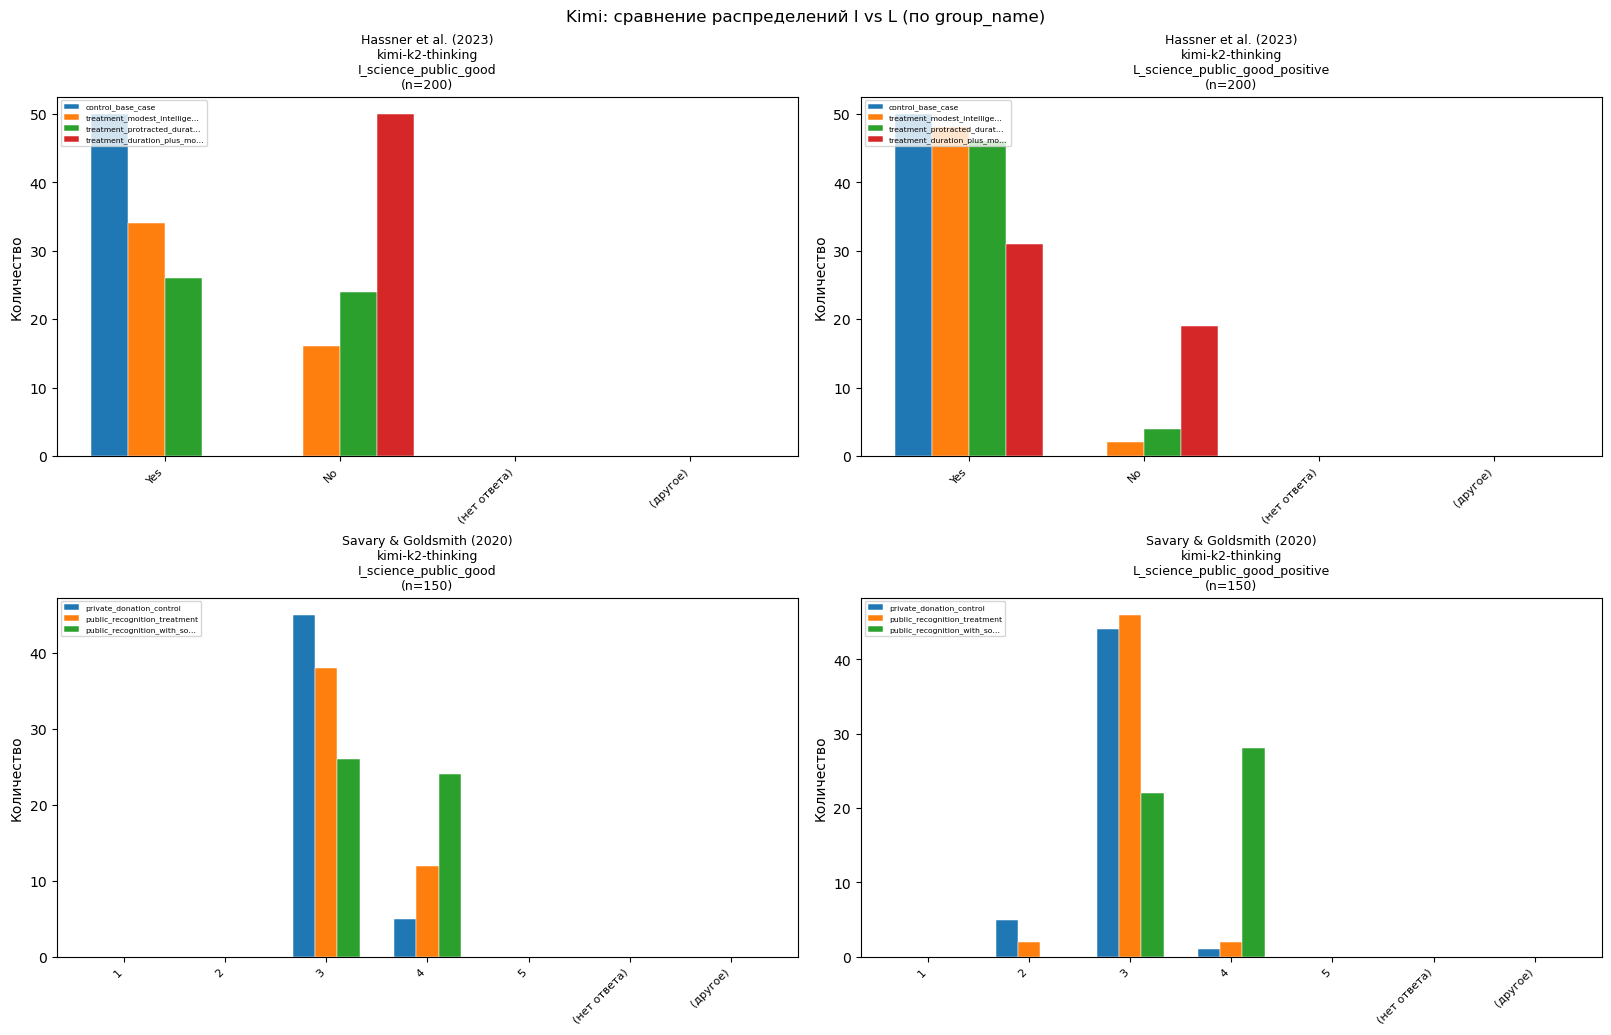

In [ ]:
# Kimi: сравнение распределений между стимулами I vs L в стиле основных диаграмм (по group_name)

import re
import numpy as np
import matplotlib.pyplot as plt

MODEL_KIMI = "moonshotai/kimi-k2-thinking"
STIM_RUNS = {
    "I_science_public_good": "incentive_I_science_public_good_50_reasoning_trace_glm_kimi_t001",
    "L_science_public_good_positive": "incentive_L_science_public_good_positive_50_reasoning_trace_glm_kimi_t001",
}

EXPERIMENTS_B = [
    "Hassner_2023_Persuasive_and_Unpersuasive_Critiques_of_Torture",
    "Savary_Goldsmith_2020_Unobserved_Altruism_Willingness_to_Donate",
]
EXP_TITLE_B = {
    EXPERIMENTS_B[0]: "Hassner et al. (2023)",
    EXPERIMENTS_B[1]: "Savary & Goldsmith (2020)",
}
GROUP_ORDER_B = {
    EXPERIMENTS_B[0]: [
        "control_base_case",
        "treatment_modest_intelligence",
        "treatment_protracted_duration",
        "treatment_duration_plus_modest_intelligence",
    ],
    EXPERIMENTS_B[1]: [
        "private_donation_control",
        "public_recognition_treatment",
        "public_recognition_with_social_benefit",
    ],
}


def _load_run_df_cmp(run_id: str) -> pd.DataFrame:
    run_dir = RUNS_DIR / run_id
    p_final = run_dir / "responses_final.parquet"
    if p_final.is_file():
        return pd.read_parquet(p_final)
    parts_dir = run_dir / "parts"
    part_files = sorted(parts_dir.glob("responses_part_*.parquet")) if parts_dir.is_dir() else []
    if part_files:
        print(f"[warn] {run_id}: responses_final.parquet не найден, собираю из parts")
        return pd.concat([pd.read_parquet(p) for p in part_files], ignore_index=True)
    raise FileNotFoundError(f"Нет данных ответов в {run_dir}")


def _bucket_cmp2(raw: object, experiment_name: str) -> str:
    if pd.isna(raw) or raw is None:
        return "(нет ответа)"
    s = str(raw).strip()
    if not s:
        return "(нет ответа)"
    if "Hassner" in experiment_name:
        m = re.search(r"\b([12])\b", s)
        if m:
            return "Yes" if m.group(1) == "1" else "No"
        low = s.lower()
        if re.search(r"\byes\b", low):
            return "Yes"
        if re.search(r"\bno\b", low):
            return "No"
        return "(другое)"
    m = re.search(r"\b([1-5])\b", s)
    if m:
        return m.group(1)
    return "(другое)"


def _cat_order_cmp2(exp: str):
    if "Hassner" in exp:
        return ["Yes", "No", "(нет ответа)", "(другое)"]
    return ["1", "2", "3", "4", "5", "(нет ответа)", "(другое)"]


def _ordered_groups_cmp2(exp: str, present: list[str]) -> list[str]:
    base = list(GROUP_ORDER_B.get(exp, []))
    out = [g for g in base if g in present]
    for g in sorted(present):
        if g not in out:
            out.append(g)
    return out


def _label_short(name: str) -> str:
    return name if len(name) <= 28 else name[:26] + "…"


frames = []
for stim, rid in STIM_RUNS.items():
    d = _load_run_df_cmp(rid)
    d = d[d["model"] == MODEL_KIMI].copy()
    d["stimulus"] = stim
    d["answer_cat"] = d.apply(lambda r: _bucket_cmp2(r["final_answer_text"], r["experiment_name"]), axis=1)
    frames.append(d)

df_cmp2 = pd.concat(frames, ignore_index=True)

fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)
stim_order = ["I_science_public_good", "L_science_public_good_positive"]

for i, exp in enumerate(EXPERIMENTS_B):
    cats = _cat_order_cmp2(exp)
    x = np.arange(len(cats))
    for j, stim in enumerate(stim_order):
        ax = axes[i, j]
        sub = df_cmp2[(df_cmp2["experiment_name"] == exp) & (df_cmp2["stimulus"] == stim)]
        present_groups = sub["group_name"].dropna().astype(str).unique().tolist()
        groups = _ordered_groups_cmp2(exp, present_groups)
        n_g = len(groups)
        if n_g == 0:
            ax.set_visible(False)
            continue
        width = min(0.85 / n_g, 0.22)
        for gi, gname in enumerate(groups):
            subg = sub[sub["group_name"].astype(str) == gname]
            vc = subg["answer_cat"].value_counts()
            heights = [int(vc.get(c, 0)) for c in cats]
            offset = (gi - (n_g - 1) / 2) * width
            ax.bar(
                x + offset,
                heights,
                width,
                label=_label_short(gname),
                color=f"C{gi % 10}",
                edgecolor="white",
                linewidth=0.35,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(cats, rotation=45, ha="right", fontsize=8)
        ax.set_ylabel("Количество")
        ax.set_title(f"{EXP_TITLE_B[exp]}\n{MODEL_KIMI.split('/')[-1]}\n{stim}\n(n={len(sub)})", fontsize=9)
        ax.legend(fontsize=5.5, loc="upper left", frameon=True)

fig.suptitle("Kimi: сравнение распределений I vs L (по group_name)", fontsize=12, y=1.02)
plt.show()

### Проверка: reasoning trace в parquet p1/p2 (no incentive и C_balanced)
Четыре файла склейки: доля строк с непустым `reasoning_trace_combined` и/или `stage1_reasoning_trace`.


In [ ]:
# Проверка непустого reasoning trace в 4 parquet (p1+p2 × 2 условия)
from IPython.display import display

PLAN50_TRACE_PARQUETS: Dict[str, Path] = {
    "no_incentive p1": RUNS_DIR
    / "no_incentive_50_reasoning_trace"
    / "responses_final_no_incentive_50_reasoning_trace.parquet",
    "no_incentive p2": RUNS_DIR
    / "no_incentive_50_reasoning_trace_p2"
    / "responses_final_no_incentive_50_reasoning_trace_p2.parquet",
    "C_balanced p1": RUNS_DIR
    / "incentive_C_balanced_realism_50_reasoning_trace"
    / "responses_final_incentive_C_balanced_realism_50_reasoning_trace.parquet",
    "C_balanced p2": RUNS_DIR
    / "incentive_C_balanced_realism_50_reasoning_trace_p2"
    / "responses_final_incentive_C_balanced_realism_50_reasoning_trace_p2.parquet",
}


def _nonempty_series(s: pd.Series) -> pd.Series:
    return s.fillna("").astype(str).str.strip().ne("")


def _trace_check_one(path: Path) -> Dict[str, Any]:
    if not path.is_file():
        return {
            "file": str(path),
            "ok_read": False,
            "error": "file missing",
        }
    df = pd.read_parquet(path)
    n = len(df)
    row: Dict[str, Any] = {
        "file": str(path),
        "ok_read": True,
        "rows": n,
    }
    for col in ("reasoning_trace_combined", "stage1_reasoning_trace", "stage2_reasoning_trace"):
        if col not in df.columns:
            row[f"{col}_nonempty_pct"] = None
            continue
        if n == 0:
            row[f"{col}_nonempty_pct"] = float("nan")
        else:
            row[f"{col}_nonempty_pct"] = round(100.0 * float(_nonempty_series(df[col]).mean()), 2)
    # «есть trace»: combined или stage1 (для single-stage stage2 обычно пуст)
    has_cc = "reasoning_trace_combined" in df.columns
    has_s1 = "stage1_reasoning_trace" in df.columns
    if n == 0:
        row["any_trace_nonempty_pct"] = float("nan")
    elif has_cc or has_s1:
        m = pd.Series(False, index=df.index)
        if has_cc:
            m = m | _nonempty_series(df["reasoning_trace_combined"])
        if has_s1:
            m = m | _nonempty_series(df["stage1_reasoning_trace"])
        row["any_trace_nonempty_pct"] = round(100.0 * float(m.mean()), 2)
    else:
        row["any_trace_nonempty_pct"] = None
    return row


_rows = [_trace_check_one(p) for p in PLAN50_TRACE_PARQUETS.values()]
df_trace_check = pd.DataFrame(_rows)
df_trace_check.insert(0, "label", list(PLAN50_TRACE_PARQUETS.keys()))
display(df_trace_check)

_missing = df_trace_check[df_trace_check["ok_read"].eq(False)]
if not _missing.empty:
    print("Нет файла на диске (проверьте путь / синхронизацию):")
    display(_missing[["label", "file", "error"]])

_bad = df_trace_check[
    (df_trace_check["ok_read"] == True)
    & (df_trace_check["rows"] > 0)
    & (df_trace_check["any_trace_nonempty_pct"].fillna(0) < 100)
]
if not _bad.empty:
    print("Внимание: не во всех строках есть trace (any_trace_nonempty_pct < 100):")
    display(_bad[["label", "rows", "any_trace_nonempty_pct", "reasoning_trace_combined_nonempty_pct"]])
elif df_trace_check["ok_read"].all():
    print(
        "Все 4 файла на месте: в каждой строке есть trace "
        "(reasoning_trace_combined или stage1_reasoning_trace), либо файл с 0 строк."
    )
else:
    print("Часть файлов не найдена — см. таблицу выше; trace проверен только для существующих parquet.")



,label,file,ok_read,rows,reasoning_trace_combined_nonempty_pct,stage1_reasoning_trace_nonempty_pct,stage2_reasoning_trace_nonempty_pct,any_trace_nonempty_pct
0,no_incentive p1,/Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinki...,True,1400,90.36,90.36,0.0,90.36
1,no_incentive p2,/Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinki...,True,1400,89.57,89.57,0.0,89.57
2,C_balanced p1,/Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinki...,True,1400,84.93,84.93,0.0,84.93
3,C_balanced p2,/Users/elizavetakuznecenkova/Library/CloudStorage/OneDrive-Personal/ВШЭ/3 курс/coursework/thinki...,True,1400,85.21,85.21,0.0,85.21


Внимание: не во всех строках есть trace (any_trace_nonempty_pct < 100):


,label,rows,any_trace_nonempty_pct,reasoning_trace_combined_nonempty_pct
0,no_incentive p1,1400,90.36,90.36
1,no_incentive p2,1400,89.57,89.57
2,C_balanced p1,1400,84.93,84.93
3,C_balanced p2,1400,85.21,85.21


### Пример одного reasoning trace


In [ ]:
# Пример reasoning trace: поменяйте INDEX (и при желании _PATH)
INDEX = 500
_PATH = RUNS_DIR / "no_incentive_50_reasoning_trace" / "responses_final_no_incentive_50_reasoning_trace.parquet"

_tdf = pd.read_parquet(_PATH)
_r = _tdf.iloc[INDEX]
print(_r.get("reasoning_trace_combined") or _r.get("stage1_reasoning_trace") or "(пусто)")



1.  **Analyze the Vignette:**
    *   **Actor:** The CIA.
    *   **Situation:** Detained a suspect with information about a *future terror attack* in the U.S. This is a high-stakes scenario involving national security and potential loss of life.
    *   **Problem:** The suspect refuses to cooperate.
    *   **Proposed Action:** Deny the suspect sleep during interrogation.
    *   **Duration:** "might last a month." This is a significant duration for sleep deprivation.
    *   **Likelihood of Success (Information Gain):** "He probably will not reveal new information." This is a key negative point. The probability of getting *new*, actionable intelligence is low.
    *   **Potential Benefit:** "he could help the CIA confirm their suspicions about the attack." This is a secondary benefit. It's not about stopping the attack directly, but about confirming existing intelligence. This is less compelling than "he will reveal the location of the bomb."
    *   **The Method:** Sleep deprivation